# Project - Segmentation-informed monocular depth estimation: how much labelled data is enough?

**Computer Vision Project · Object Identification and Depth Estimation for Mobility Assistance**

Groups of up to three; one member submits the group's notebook (`.ipynb`). Every member must be able to explain every cell.

A visually impaired person could benefit from knowing how far away different parts of a scene are. Monocular depth estimation turns one ordinary RGB photograph into a depth map, where every pixel holds an estimated distance in metres. This project asks a narrow, measurable question:

> **Starting from a pretrained depth model, and telling it which pixels belong to which object instance, how does indoor depth accuracy change as the number of labelled training images grows from 0 to 1,000?**

The project does **not** build a navigation system. It evaluates depth estimation as one possible perception component.

### The experiment in one picture

```
RGB image ────────────────┐
                          ├──▶  depth model  ──▶  predicted depth  ──▶  compared with GT depth
GT instance masks ────────┘          ▲
(cup 1, cup 2, cup 3, ...)           │
                                     └── fine-tuned on N labelled images,  N = 0, 100, 300, 500, 1000
```

NYU Depth V2 labels every object with a **class and an instance number** (cup 1, cup 2, cup 3). A pretrained depth model sees only textures and edges and need not discover the same objects the annotators did. So instead of hoping it does, we **hand the model the ground-truth instance masks as an input**. The model is then free to concentrate on one job: working out how far away things are.

| Stage | RGB | GT instance masks | GT depth |
|---|---|---|---|
| Training | input | input | **target** |
| Validation | input | input | used to pick the checkpoint |
| Test | input | input | **evaluation only** — never shown to the model |

Two consequences you should keep in mind throughout, and that Section 14 asks you to write down:

1. Because the masks are ground truth at test time too, every number measures *how well depth can be estimated when perfect instance information is available*. It is an upper bound for a system that has to predict its own masks.
2. There is no RGB-only control in this design. **N = 0** is the segmentation-informed model *before any training*: its architecture accepts the masks, but they have not yet been used to learn anything (Section 5 shows why this equals the pretrained model's own prediction). The variable that changes is N and nothing else.

### How this notebook works

Each major section is a stage of the project. Each **Q*x.y*** is one small task: it says what to do, what to report, and is followed by a code cell. Cells containing `# YOUR CODE HERE` are yours to write. Cells without it are provided; read them anyway. Cells ending in *Answer:* are written answers: edit the cell and type under the word.

| Section | Stage | Rough runtime on a T4 |
|---|---|---|
| 0 | GPU, W&B, NYU Depth V2 download | 5–10 min (2.8 GB) |
| 1 | Inspect the dataset and its labels | seconds |
| 2 | Scene-aware splits and nested training sets | seconds |
| 3 | Data pipeline for the model | 5 min (one-off cache) |
| 4 | Metrics, implemented by you and checked on paper | seconds |
| 5 | The segmentation-informed model at N = 0 | 1 min |
| 6 | Loss, training loop, experiment runner | 2 min smoke test |
| 7–10 | Fine-tune with 100, 300, 500, 1,000 images | ~8–15 min each |
| 11 | Compare models: learning curve, uncertainty, seeds | ~30 min (two extra runs) |
| 12 | Object-level depth evaluation | seconds |
| 13 | W&B summary | seconds |
| 14 | Final analysis | — |

## 0. GPU, W&B, and NYU Depth V2

Open this notebook in [Colab](https://colab.research.google.com), then **File ▸ Save a copy in Drive**. Set **Runtime ▸ Change runtime type** to a GPU. Log in to W&B when asked; this project logs to a project called `cv-depth-seg`.

In [ ]:
# Group members — fill in before submitting.
MEMBERS = [
    ("Keevon Lyle Jacobs", "2762460"),("Aluwani Nndwamato", "2671832"),("Mmakwena Moichela","2663211")
]
for name, number in MEMBERS:
    print(f"{number}  {name}")

2762460  Keevon Lyle Jacobs
2671832  Aluwani Nndwamato
2663211  Mmakwena Moichela


In [ ]:

!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
!pip install -q wandb transformers h5py
import wandb
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 2671832 (2671832-university-of-the-witwatersrand) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

Checkpoints and result tables are written to Google Drive, so a disconnected Colab session does not cost you a 15-minute training run.

In [ ]:
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/cv-depth-seg"
except ImportError:
    WORK = "./work"
os.makedirs(WORK, exist_ok=True)
print("checkpoints and result tables go to", WORK)

Mounted at /content/drive
checkpoints and result tables go to /content/drive/MyDrive/cv-depth-seg


The data is the labelled subset of [NYU Depth V2](https://cs.nyu.edu/~fergus/datasets/nyu_depth_v2.html) (Silberman et al., 2012): 1,449 aligned RGB and depth pairs from 464 indoor scenes in three cities, filmed with a Microsoft Kinect. Every object is labelled with a class and an instance number, and the depth maps have been preprocessed to fill in missing readings. It is one 2.8 GB MATLAB v7.3 file. The download takes several minutes; if the NYU server is slow, download once and keep a copy in Drive.

In [ ]:
!mkdir -p /content/data
!wget -nc -q --show-progress -P /content/data http://horatio.cs.nyu.edu/mit/silberman/nyu_depth_v2/nyu_depth_v2_labeled.mat
!ls -lh /content/data

nyu_depth_v2_labele 100%[===================>]   2.77G  14.3MB/s    in 3m 49s  
total 2.8G
-rw-r--r-- 1 root root 2.8G Jul 14  2020 nyu_depth_v2_labeled.mat


Imports, one configuration dictionary, and reproducibility. Every hyperparameter that matters lives in `CONFIG` so that nothing is silently different between the five experiments. **Do not change `CONFIG` between runs once you have started Section 7**; if you must change it, re-run Sections 5 to 10 from the top.

In [ ]:
import copy, json, math, random, time
from pathlib import Path
from torch.optim.lr_scheduler import LambdaLR
import gc
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForDepthEstimation

DEV = "cuda" if torch.cuda.is_available() else "cpu"

CONFIG = dict(
    mat_path="/content/data/nyu_depth_v2_labeled.mat",
    pretrained_id="depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf",
    input_hw=(252, 336),            # multiples of 14, as the ViT backbone requires
    n_classes=894,                  # NYU class ids run 1..894; 0 means unlabelled
    min_depth=1e-3, max_depth=10.0, # metres; pixels outside this range are ignored
    n_pool=1000, n_val=100, n_test=349,
    train_sizes=[100, 300, 500, 1000],
    steps=1500, batch_size=8, eval_every=100, warmup=50,
    lr_base=5e-6, lr_head=3e-4, weight_decay=1e-2,
    silog_lambda=0.85, emb_dim=16, head_ch=32,
    seed=0, wandb_project="cv-depth-seg",
)
MIN_DEPTH, MAX_DEPTH = CONFIG["min_depth"], CONFIG["max_depth"]


def seed_everything(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG["seed"])
RESULTS = {}        # N -> dict(per_image, objects, strata, history, summary)
print("device:", DEV)

device: cuda


## 1. Inspect NYU Depth V2 and its labels

The labelled subset ships as a single HDF5 container. Before building anything, look at what is inside it. The labels matter most: the model's extra input is built from them, and everything in the object-level evaluation at the end depends on understanding exactly what an "instance" is here. Each pixel carries a **class** (what is it?) and an **instance number within that class** (which one?). That second number is what lets us tell cup 1 from cup 2.

**Q1.1.** Open the file (done below, as `f`) and list every key with its shape and dtype. Say which keys hold the RGB images, the depth maps, the class labels and the instance labels, and how many images there are. Look at the axis order of each array: it is not the order you expect an image to have.

In [ ]:
# f = h5py.File(CONFIG["mat_path"], "r")
# # YOUR CODE HERE

# # 1. List every top-level key with its shape and dtype.
# print(f"{'key':<12} {'shape':<28} {'dtype'}")
# print("-" * 55)
# for k in f.keys():
#     ds = f[k]
#     print(f"{k:<12} {str(ds.shape):<28} {ds.dtype}")
f = h5py.File(CONFIG["mat_path"], "r")

print(f"{'key':<12} {'shape':<28} {'dtype'}")
print("-" * 55)

for k in f.keys():
    obj = f[k]
    if isinstance(obj, h5py.Dataset):
        print(f"{k:<12} {str(obj.shape):<28} {obj.dtype}")
    elif isinstance(obj, h5py.Group):
        print(f"{k:<12} {'<Group>':<28} {'-'}")

key          shape                        dtype
-------------------------------------------------------
#refs#       <Group>                      -
#subsystem#  <Group>                      -
accelData    (4, 1449)                    float32
depths       (1449, 640, 480)             float32
images       (1449, 3, 640, 480)          uint8
instances    (1449, 640, 480)             uint8
labels       (1449, 640, 480)             uint16
names        (1, 894)                     object
namesToIds   (1, 6)                       uint32
rawDepthFilenames (1, 1449)                    object
rawDepths    (1449, 640, 480)             float32
rawRgbFilenames (1, 1449)                    object
sceneTypes   (1, 1449)                    object
scenes       (1, 1449)                    object


**Q1.2.** MATLAB stores arrays column-major, so h5py shows each one with its axes reversed relative to the image convention. Write `load_sample(f, i)` returning four arrays for image `i`: RGB as `uint8` $(480, 640, 3)$, depth as `float32` $(480, 640)$ in metres, class labels as `int32` $(480, 640)$, and instance labels as `int32` $(480, 640)$. Then, for image 0, print the four shapes and dtypes, the minimum, maximum and mean depth, and show the RGB image beside its depth map. Depth should be in metres, roughly 0.7 to 10.

*Hint:* RGB needs a different transpose from the other three, because it has a channel axis.

rgb    shape=(480, 640, 3) dtype=uint8
depth  shape=(480, 640) dtype=float32
cls    shape=(480, 640) dtype=int32
inst   shape=(480, 640) dtype=int32
depth min/mean/max = 1.799 / 2.880 / 3.616 m


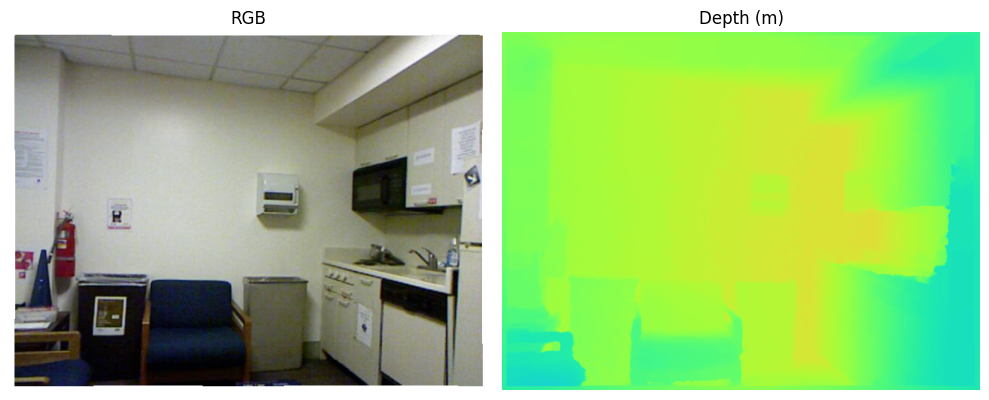

In [ ]:
def load_sample(f, i):
    rgb = f["images"][i].astype(np.uint8)

    # Convert RGB to (H, W, 3)
    if rgb.shape == (3, 640, 480):
        rgb = np.transpose(rgb, (2, 1, 0))
    elif rgb.shape == (640, 480, 3):
        rgb = np.transpose(rgb, (1, 0, 2))

    depth = f["depths"][i].transpose(1, 0).astype(np.float32)
    cls = f["labels"][i].transpose(1, 0).astype(np.int32)
    inst = f["instances"][i].transpose(1, 0).astype(np.int32)

    return rgb, depth, cls, inst


rgb0, depth0, cls0, inst0 = load_sample(f, 0)

for name, arr in [("rgb", rgb0), ("depth", depth0), ("cls", cls0), ("inst", inst0)]:
    print(f"{name:<6} shape={arr.shape} dtype={arr.dtype}")

print(f"depth min/mean/max = "
      f"{depth0.min():.3f} / {depth0.mean():.3f} / {depth0.max():.3f} m")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(rgb0)
ax[0].set_title("RGB")
ax[0].axis("off")

ax[1].imshow(depth0, cmap="turbo", vmin=0, vmax=6)
ax[1].set_title("Depth (m)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

**Q1.3.** Class labels are integers; their names live in `f["names"]`, an array of HDF5 object references to MATLAB strings. The names list is 1-indexed: class id $k$ is `names[k-1]`, and id 0 means *unlabelled*. Build `CLASS_NAMES` so that `CLASS_NAMES[k]` is the name of class id $k$ and `CLASS_NAMES[0] == "unlabelled"`. Report its length and confirm it equals `CONFIG["n_classes"] + 1`. Then, over the first 100 images, count pixels per class and print the ten most common classes with their names and their share of all pixels, unlabelled included.

*Hint:* print `f["names"].shape` first. `f["names"][:].flatten()` gives the references; `read_str` below decodes one.

In [ ]:
def read_str(f, ref):
    # Decode a MATLAB character array stored behind an HDF5 object reference.
    return "".join(chr(c) for c in f[ref][:].flatten())

# --- Build CLASS_NAMES -------------------------------------------------
print("f['names'].shape =", f["names"].shape)

refs = f["names"][:].flatten()                     # (894,) of h5py.Reference
CLASS_NAMES = ["unlabelled"] + [read_str(f, r) for r in refs]

print("len(CLASS_NAMES) =", len(CLASS_NAMES),
      "| expected =", CONFIG["n_classes"] + 1)
print("CLASS_NAMES[0]  =", CLASS_NAMES[0])
print("CLASS_NAMES[1:6] =", CLASS_NAMES[1:6])

# --- Pixel frequencies over first 100 images ---------------------------
counts = np.zeros(len(CLASS_NAMES), dtype=np.int64)
for i in range(100):
    _, _, cls_i, _ = load_sample(f, i)
    # clip in case anything unexpected slipped in, but ids should be 0..894
    counts += np.bincount(cls_i.ravel(), minlength=len(CLASS_NAMES))

total = counts.sum()
top10 = np.argsort(counts)[::-1][:10]

print(f"\ntop-10 classes over first 100 images "
      f"(total pixels = {total:,}):")
print(f"{'id':>4}  {'name':<20} {'pixels':>12}  {'share':>7}")
print("-" * 50)
for k in top10:
    print(f"{k:>4}  {CLASS_NAMES[k]:<20} {counts[k]:>12,}  "
          f"{counts[k]/total:>7.2%}")

f['names'].shape = (1, 894)
len(CLASS_NAMES) = 895 | expected = 895
CLASS_NAMES[0]  = unlabelled
CLASS_NAMES[1:6] = ['book', 'bottle', 'cabinet', 'ceiling', 'chair']

top-10 classes over first 100 images (total pixels = 30,720,000):
  id  name                       pixels    share
--------------------------------------------------
  21  wall                    7,963,815   25.92%
   0  unlabelled              5,536,733   18.02%
  28  door                    1,081,354    3.52%
  88  bookshelf                 966,086    3.14%
   4  ceiling                   923,169    3.01%
   3  cabinet                   831,670    2.71%
  45  whiteboard                818,040    2.66%
 141  clothes                   802,122    2.61%
  11  floor                     753,732    2.45%
  89  curtain                   728,526    2.37%


**Q1.4.** The class says what a pixel is; the instance number says *which one*. `instances` numbers objects *within a class*, so two cups share a class id and differ in instance number, but instance number alone is not unique across the image: "chair 1" and "table 1" both have instance 1. Write `object_key(cls, inst)` that turns the two arrays into one array of integers, unique for every (class, instance) pair, with all unlabelled pixels mapping to 0. Then find an image that contains at least two instances of the same class and show, side by side: the RGB image, the depth map, the class map, and the object map (colour each distinct key differently). For that image print the number of distinct objects, the fraction of unlabelled pixels, and a table of (class name, instance number, pixel count) for every object.

*Hint:* class ids go up to 894 and instance numbers fit in one byte, so a single multiply-and-add is enough.

chosen image index: 0


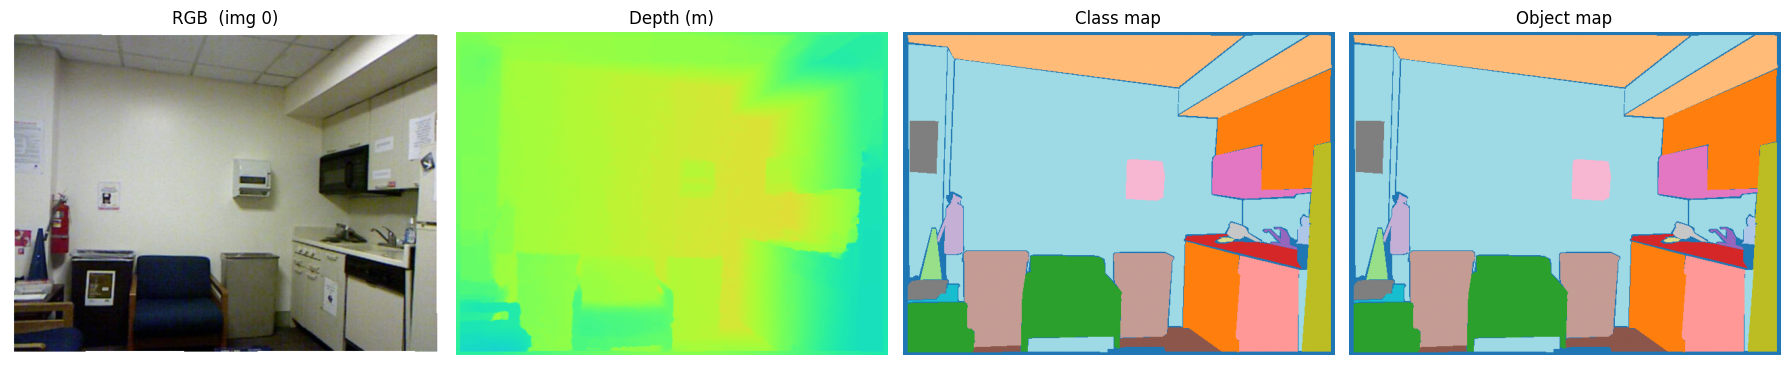

distinct objects        : 31
unlabelled fraction     : 7.10%

class                 inst     pixels
----------------------------------------
wall                     4     98,741
ceiling                  2     23,457
cabinet                  2     18,025
chair                    2     16,582
wall                     5     12,861
garbage bin              1     11,803
dishwasher               1     11,782
cabinet                  1     11,179
refridgerator            1     10,354
ceiling                  1      9,899
garbage bin              2      9,446
wall                     1      7,121
chair                    1      6,815
microwave                1      5,652
wall                     2      4,830
floor                    1      3,609
paper towel dispenser     1      3,280
paper                    2      3,167
counter                  1      3,030
unknown                  1      2,617
fire extinguisher        1      2,218
wall                     3      1,858
paper                 

In [ ]:


def object_key(cls, inst):
    """Unique integer per (class, instance) pair; unlabelled -> 0."""
    key = cls.astype(np.int64) * 256 + inst.astype(np.int64)
    key[cls == 0] = 0
    return key


# Find an image with at least two instances of the same class.
target = None
for i in range(200):
    _, _, cls_i, inst_i = load_sample(f, i)
    key_i = object_key(cls_i, inst_i)
    # count how many (cls, inst) pairs there are, and how many distinct classes
    pairs = set(zip(cls_i.ravel().tolist(), inst_i.ravel().tolist())) - {(0, 0)}
    classes = [c for c, _ in pairs]
    if len(pairs) - len(set(classes)) >= 1:      # at least one class with 2 instances
        target = i
        break

print("chosen image index:", target)

rgb_t, depth_t, cls_t, inst_t = load_sample(f, target)
key_t = object_key(cls_t, inst_t)

# --- Visualisation -----------------------------------------------------
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(rgb_t);
ax[0].set_title(f"RGB  (img {target})")
ax[1].imshow(depth_t, cmap="turbo", vmin=0, vmax=6)
ax[1].set_title("Depth (m)")
ax[2].imshow(cls_t, cmap="tab20");
ax[2].set_title("Class map")
ax[3].imshow(key_t, cmap="tab20");
ax[3].set_title("Object map")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# --- Diagnostics -------------------------------------------------------
n_objects = len(np.unique(key_t)) - 1          # subtract unlabelled (key 0)
unlab_frac = (key_t == 0).mean()
print(f"distinct objects        : {n_objects}")
print(f"unlabelled fraction     : {unlab_frac:.2%}")

# --- Table of (class name, instance, pixel count) ----------------------
rows = []
for k in np.unique(key_t):
    if k == 0:
        continue
    c = int(k // 256)
    n = int(k % 256)
    rows.append((CLASS_NAMES[c], n, int((key_t == k).sum())))

rows.sort(key=lambda r: -r[2])                 # biggest objects first
print(f"\n{'class':<20} {'inst':>5} {'pixels':>10}")
print("-" * 40)
for name, n, px in rows:
    print(f"{name:<20} {n:>5} {px:>10,}")

**Q1.5.** Answer in a few sentences each:

- What would a depth model that only receives RGB have to work out for itself that the instance masks now tell it for free?
- Semantic labels alone say "these pixels are cup". Why is that not enough to separate cup 1 from cup 2, and why does this experiment need the instance number?
- You measured the fraction of unlabelled pixels in Q1.3 and Q1.4. What will the model be told about those pixels, and what does that imply for how much the masks can help in a typical image?
- The depth maps in this file have been preprocessed to fill in missing readings. In two sentences, what does that mean for how literally you should treat a very small error against them?

*Answer:*

## 2. Splits and experimental design

A learning curve is only as trustworthy as the split underneath it. NYU's 1,449 images come from 464 scenes, and consecutive frames of one room are near-duplicates. A random image-level split would put near-copies of test images into training and flatter every number. So we split **by scene**.

We need up to 1,000 training images, which rules out the official NYU split (its training half has only 795). We carve our own: a pool of 1,000 training images, 100 validation images (to choose the checkpoint, not to report), and the remainder, about 349 images, as test. Training sets of 100, 300, 500 and 1,000 are drawn from the pool so that they are nested.

**Q2.1.** Write `make_splits(scene_group, seed, n_pool, n_val, n_test)`, where `scene_group[i]` is a label for the scene image $i$ came from, returning a dict of three integer arrays `pool`, `val`, `test`. Shuffle the *groups* with a seeded `RandomState`, fill `val` greedily with whole groups without exceeding `n_val`, then `test` the same way up to `n_test`, and let `pool` be the remaining images in shuffled order, truncated to `n_pool`. No scene may appear in more than one split. Scene names look like `bedroom_0001a`; decide whether the trailing letter belongs in the group label, and justify your choice in a comment. Report the three sizes you actually got and how many images, if any, were left unused.

*Hint:* read the scene names with `read_str` as in Q1.3, from `f["scenes"]`. Print the first few.

In [ ]:
scene_names = [read_str(f, r) for r in f["scenes"][:].flatten()]
print(len(scene_names), scene_names[:6])

# Scene names look like 'bedroom_0001a'. The trailing letter is a session
# suffix, so images sharing the prefix 'bedroom_0001' are the same room and
# the same recording session. We use the prefix (without the letter) as the
# group label so no two shots of the same room can end up in different splits.
scene_group = np.array([s[:-1] if s[-1:].isalpha() else s for s in scene_names])

def make_splits(scene_group, seed=0, n_pool=1000, n_val=100, n_test=349):
    scene_group = np.asarray(scene_group)
    groups = np.unique(scene_group)

    rng = np.random.RandomState(seed)
    rng.shuffle(groups)

    def fill(groups_iter, target):
        chosen = []
        size = 0
        remaining = []
        for g in groups_iter:
            g_size = int((scene_group == g).sum())
            if size + g_size <= target:
                chosen.append(g); size += g_size
            else:
                remaining.append(g)
        return chosen, remaining

    val_groups, rest = fill(groups, n_val)
    test_groups, rest = fill(rest, n_test)

    mask_of = lambda gs: np.isin(scene_group, gs)
    val  = np.where(mask_of(val_groups))[0]
    test = np.where(mask_of(test_groups))[0]

    pool_mask = ~(mask_of(val_groups) | mask_of(test_groups))
    pool = np.where(pool_mask)[0]
    rng.shuffle(pool)
    pool = pool[:n_pool]

    return {"pool": pool, "val": val, "test": test}




SPLITS = make_splits(scene_group, CONFIG["seed"],
                     CONFIG["n_pool"], CONFIG["n_val"], CONFIG["n_test"])

print({k: len(v) for k, v in SPLITS.items()})
print("total used      :", sum(len(v) for v in SPLITS.values()))
print("total in dataset:", len(scene_group))
print("unused images   :", len(scene_group) - sum(len(v) for v in SPLITS.values()))



1449 ['kitchen_0004', 'kitchen_0004', 'office_0003', 'office_0003', 'office_0004', 'office_0004']
{'pool': 1000, 'val': 100, 'test': 349}
total used      : 1449
total in dataset: 1449
unused images   : 0


The check below is provided: it asserts your splits are disjoint at the scene level. If it fails, your splitter leaks.

In [ ]:
# # Use the scene/group labels for all 1,449 images.
# # If your HDF5 file contains scene IDs, use those here.
# # Check the available HDF5 keys first


# # print(list(f.keys()))
# # scene_group = np.asarray(f["scene_group"]).squeeze()

# # SPLITS = make_splits(
# #     scene_group,
# #     CONFIG["seed"],
# #     CONFIG["n_pool"],
# #     CONFIG["n_val"],
# #     CONFIG["n_test"]
# # )

# # groups = {
# #     k: set(scene_group[v])
# #     for k, v in SPLITS.items()
# # }

# # assert not (groups["pool"] & groups["val"]) \
# #        and not (groups["pool"] & groups["test"]) \
# #        and not (groups["val"] & groups["test"]), \
# #        "scene leakage between splits"

# # print(
# #     {k: len(v) for k, v in SPLITS.items()},
# #     "· scene groups:",
# #     {k: len(v) for k, v in groups.items()}
# # )




# scene_group = np.asarray(f["scenes"]).squeeze()

# SPLITS = make_splits(
#     scene_group,
#     CONFIG["seed"],
#     CONFIG["n_pool"],
#     CONFIG["n_val"],
#     CONFIG["n_test"]
# )

# groups = {k: set(scene_group[v]) for k, v in SPLITS.items()}

# assert not (groups["pool"] & groups["val"]) \
#        and not (groups["pool"] & groups["test"]) \
#        and not (groups["val"] & groups["test"]), \
#        "scene leakage between splits"

# print(
#     {k: len(v) for k, v in SPLITS.items()},
#     "· scene groups:",
#     {k: len(v) for k, v in groups.items()}
# )

groups = {k: set(np.asarray(scene_group)[v]) for k, v in SPLITS.items()}
assert not (groups["pool"] & groups["val"]) and not (groups["pool"] & groups["test"]) \
       and not (groups["val"] & groups["test"]), "scene leakage between splits"

**Q2.2.** Write `subset_indices(pool, n, subset_seed=None)`. With `subset_seed=None` it returns the first `n` entries of `pool`; otherwise it draws `n` entries at random from `pool` without replacement using that seed (Q11.4 uses this to measure how much the answer depends on *which* 100 images you picked). Verify for $n \in \{100, 300, 500, 1000\}$ that the default subsets are nested ($100 \subset 300 \subset 500 \subset 1000$) and that none of them intersects `SPLITS["val"]` or `SPLITS["test"]`. Explain in a sentence why nesting is the right design for a learning curve.

In [ ]:
def subset_indices(pool, n, subset_seed=None):
    pool = np.asarray(pool)
    if subset_seed is None:
        # Default: take a prefix of the already-shuffled pool, so subsets
        # for growing n are nested.
        return pool[:n]
    rng = np.random.RandomState(subset_seed)
    return rng.choice(pool, size=n, replace=False)


SUBSETS = {n: subset_indices(SPLITS["pool"], n) for n in [100, 300, 500, 1000]}

# (a) nesting: each subset must be contained in the next
for a, b in [(100, 300), (300, 500), (500, 1000)]:
    assert set(SUBSETS[a]) <= set(SUBSETS[b]), f"N={a} not nested in N={b}"
print("nesting OK")

# (b) no leak into val or test
val_set  = set(SPLITS["val"])
test_set = set(SPLITS["test"])
for n, s in SUBSETS.items():
    assert not (set(s) & val_set),  f"N={n} intersects val"
    assert not (set(s) & test_set), f"N={n} intersects test"
print("no leakage OK")

# (c) sanity: the seed branch is deterministic and different
a = subset_indices(SPLITS["pool"], 100, subset_seed=1)
b = subset_indices(SPLITS["pool"], 100, subset_seed=1)
c = subset_indices(SPLITS["pool"], 100, subset_seed=2)
print("seed=1 twice equal:", np.array_equal(a, b))
print("seed=1 vs seed=2 equal:", np.array_equal(a, c))

nesting OK
no leakage OK
seed=1 twice equal: True
seed=1 vs seed=2 equal: False


**Q2.3.** Write the design of the experiment down before running anything. Fill in a table with one row per condition ($N = 0, 100, 300, 500, 1000$) and columns: what the model receives as RGB, what it receives as instance information (training and test), and what the ground-truth depth is used for. Then list at least five things that are **held constant** across the five rows (for example architecture, input resolution, loss, optimiser, step budget, validation images, test images), and the one thing that varies. Finally, in two sentences, explain why using ground-truth masks at test time makes the results an upper bound for a system that must produce its own masks.

*Answer:* NB:this split is done by scnece and not by image. Doing it by image will cause data leakage. Because we are already showing the training alot of the depths. Then we take same or similar image in testing and ask for depth. Of course it will predict the depth accurately.


The design table
N	RGB input	Instance information — training	Instance information — test	GT depth used for
0	RGB, resized to 252×336, ImageNet-normalised	GT cls and inst fed into the wrapper, but head is zero-initialised → contributes nothing	Same: GT cls/inst passed in, but head still zero → output = pretrained model	Nothing during training (no steps run). Used only for evaluation metrics.
100	Same	GT cls/inst used to build the class embedding, boundary map, and instance-pooled log-depth; head learns from them	GT cls/inst supplied exactly as in training	Training target (SILog loss). Validation target to pick checkpoint. Test target for metrics only.
300	Same	Same, on the 300-image nested subset	Same	Same
500	Same	Same, on the 500-image nested subset	Same	Same
1000	Same	Same, on the 1000-image nested subset	Same	Same

## 3. Prepare NYU Depth V2 for fine-tuning

Reading from the HDF5 file image by image is slow, and h5py handles are awkward to share with `DataLoader` workers. So we convert the data once into four `.npy` files that can be memory-mapped, and build the model's inputs from those.

The network will receive the RGB image plus three signals derived from the instance labels. This is the whole of what "segmentation-informed" means here:

1. **Class embedding**: each pixel's class id goes through a learned embedding table (a vector per class), so the model can learn that "wall" and "cup" behave differently.
2. **Instance boundaries**: a one-channel map that is 1 where the instance changes between neighbouring pixels. Depth tends to jump at object edges.
3. **Instance-pooled depth statistics**: for each instance (cup 1, cup 2, cup 3 separately, not "cup" as a class), the mean of the model's own log-depth prediction over that instance's pixels, broadcast back to every pixel of the instance, plus each pixel's deviation from it. This is the only signal that depends on instance *identity* and not just class: it lets the model reason about an object as one connected thing at one distance.

Q3.2 and Q3.3 build the inputs for the first two; Section 5 builds the third.

**Q3.1.** Write `build_cache(f, out)` that creates four memory-mapped arrays in `out`: `rgb.npy` $(1449, 480, 640, 3)$ uint8, `depth.npy` $(1449, 480, 640)$ float32, `cls.npy` $(1449, 480, 640)$ uint16, and `inst.npy` $(1449, 480, 640)$ uint8, filling them with `load_sample`. The `open_memmap` calls are provided. After running it, report the total size on disk and confirm by loading with `mmap_mode="r"` that `rgb_all[0]` matches `load_sample(f, 0)[0]` exactly.

In [ ]:
CACHE = Path("/content/cache"); CACHE.mkdir(exist_ok=True)

def build_cache(f, out=CACHE):
    N = f["images"].shape[0]
    mm = lambda name, dt, shape: np.lib.format.open_memmap(out / name, mode="w+", dtype=dt, shape=shape)
    rgb, depth = mm("rgb.npy", np.uint8, (N, 480, 640, 3)), mm("depth.npy", np.float32, (N, 480, 640))
    cls, inst = mm("cls.npy", np.uint16, (N, 480, 640)), mm("inst.npy", np.uint8, (N, 480, 640))
    # YOUR CODE HERE: fill the four arrays image by image, then flush each one
    for i in range(N):
        r, d, c, k = load_sample(f, i)
        rgb[i], depth[i], cls[i], inst[i] = r, d, c, k
    for a in (rgb, depth, cls, inst):
        a.flush()

if not (CACHE / "inst.npy").exists():
    build_cache(f)
rgb_all, depth_all = np.load(CACHE / "rgb.npy", mmap_mode="r"), np.load(CACHE / "depth.npy", mmap_mode="r")
cls_all, inst_all = np.load(CACHE / "cls.npy", mmap_mode="r"), np.load(CACHE / "inst.npy", mmap_mode="r")
total = sum(p.stat().st_size for p in CACHE.glob("*.npy"))
print(f"cache size on disk: {total/1e9:.2f} GB")
print("rgb_all[0] matches load_sample:", np.array_equal(rgb_all[0], load_sample(f, 0)[0]))


cache size on disk: 4.45 GB
rgb_all[0] matches load_sample: True


**Q3.2.** The network cannot use `(class, instance)` pairs directly; it needs a small **dense index** per image. Write `dense_instances(cls, inst)` for one image's two $(H, W)$ integer arrays, returning `inst_idx`, an `int64` $(H, W)$ array where unlabelled pixels are 0 and the distinct objects of the image are numbered $1, 2, \dots, K$, and `inst_cls`, an `int64` array of length $K + 1$ giving the class id of each index (with `inst_cls[0] = 0`). Test it on the image you chose in Q1.4: $K$ should equal the number of distinct objects you counted there, and `inst_cls[inst_idx]` should reproduce the class map exactly. Include an image-with-no-unlabelled-pixels case in your thinking: your function must still number objects from 1 and not from 0.

*Hint:* `np.unique(..., return_inverse=True)` is the natural tool, but think about what it does to index 0 when no pixel is unlabelled.

In [ ]:
def dense_instances(cls, inst):
    key = object_key(cls, inst)                       # 0 = unlabelled
    uniq, inverse = np.unique(key, return_inverse=True)
    inverse = inverse.reshape(key.shape)
    if uniq[0] != 0:                                  # no unlabelled pixels: add a dummy slot 0
        inverse = inverse + 1
        uniq = np.concatenate([[0], uniq])
    inst_idx = inverse.astype(np.int64)
    inst_cls = (uniq // 256).astype(np.int64)
    inst_cls[0] = 0
    return inst_idx, inst_cls

# test on the Q1.4 image
idx_t, icls_t = dense_instances(cls_t, inst_t)
print("K =", idx_t.max(), "| objects counted in Q1.4 =", n_objects)
print("inst_cls[inst_idx] reproduces class map:", np.array_equal(icls_t[idx_t], cls_t))


K = 31 | objects counted in Q1.4 = 31
inst_cls[inst_idx] reproduces class map: True


**Q3.3.** Write `boundary_map(inst_idx)` taking a batch $(B, H, W)$ of dense instance indices and returning $(B, 1, H, W)$ float, equal to 1 at every pixel whose index differs from its right neighbour or from the neighbour below it, and 0 elsewhere. Boundaries between an object and the unlabelled region count. The last row and column have no neighbour and are 0. No Python loop over pixels. Check it by hand on a $4 \times 4$ example with two objects and some unlabelled pixels, and print both the input and the output.

In [ ]:
def boundary_map(inst_idx):
    b = torch.zeros_like(inst_idx, dtype=torch.bool)
    b[:, :, :-1] |= inst_idx[:, :, :-1] != inst_idx[:, :, 1:]   # differs from right neighbour
    b[:, :-1, :] |= inst_idx[:, :-1, :] != inst_idx[:, 1:, :]   # differs from neighbour below
    return b.unsqueeze(1).float()

x = torch.tensor([[[0, 0, 1, 1],
                   [0, 2, 1, 1],
                   [0, 2, 2, 0],
                   [0, 0, 0, 0]]])
print("input:\n", x[0])
print("boundary:\n", boundary_map(x)[0, 0])

input:
 tensor([[0, 0, 1, 1],
        [0, 2, 1, 1],
        [0, 2, 2, 0],
        [0, 0, 0, 0]])
boundary:
 tensor([[0., 1., 0., 0.],
        [1., 1., 1., 1.],
        [1., 1., 1., 0.],
        [0., 0., 0., 0.]])


**Q3.4.** Write `NYUSeg(Dataset)`. For an index into `self.idx` it must read that image from the memory-mapped arrays and return a dict with:

- `rgb`: $(3, h, w)$ float, resized bilinearly to `CONFIG["input_hw"]` and normalised with the ImageNet mean and standard deviation (provided).
- `depth`: $(1, h, w)$ float, in metres, resized with **area** averaging (it is a measurement; do not invent values with nearest-neighbour).
- `cls`: $(h, w)$ long and `inst`: $(h, w)$ long, where `inst` is the output of `dense_instances` run *after* resizing the labels with **nearest-neighbour** (labels are categories; never interpolate them).
- `index`: the image's index in the full dataset.
- If `self.full_res`: also `depth_full` $(480, 640)$, `cls_full` and `inst_full`, untouched, for evaluation at native resolution.

If `self.train`, flip **every** returned tensor horizontally with probability 0.5 (the same flip for all of them: an object's identity does not change when mirrored, but its pixels must stay aligned). Nothing random may happen when `self.train` is false.

*Hint:* `F.interpolate` works on $(1, C, H, W)$ tensors; `mode="nearest"` needs a float input, so cast back to long afterwards. Flip with `torch.flip(x, dims=[-1])`.

In [ ]:
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMNET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


class NYUSeg(Dataset):
    def __init__(self, indices, train=False, hw=CONFIG["input_hw"], full_res=False):
        self.idx, self.train, self.hw, self.full_res = np.asarray(indices), train, hw, full_res

    def __len__(self):
        return len(self.idx)

    def _resize(self, x, mode):
        kw = dict(align_corners=False) if mode == "bilinear" else {}
        return F.interpolate(x[None], size=self.hw, mode=mode, **kw)[0]

    def __getitem__(self, k):
        i = int(self.idx[k])
        rgb_np, depth_np = np.array(rgb_all[i]), np.array(depth_all[i])
        cls_np = np.array(cls_all[i]).astype(np.int64)
        inst_np = np.array(inst_all[i]).astype(np.int64)

        rgb = torch.from_numpy(rgb_np).permute(2, 0, 1).float() / 255.0
        rgb = (self._resize(rgb, "bilinear") - IMNET_MEAN) / IMNET_STD

        depth_full = torch.from_numpy(depth_np)
        depth = self._resize(depth_full[None].float(), "area")        # measurement -> area averaging

        cls_full, inst_full = torch.from_numpy(cls_np), torch.from_numpy(inst_np)
        cls_t = self._resize(cls_full[None].float(), "nearest")[0].long()   # categories -> nearest
        inst_r = self._resize(inst_full[None].float(), "nearest")[0].long()
        inst_idx, _ = dense_instances(cls_t.numpy(), inst_r.numpy())        # dense AFTER resizing
        inst_t = torch.from_numpy(inst_idx)

        out = {"rgb": rgb, "depth": depth, "cls": cls_t, "inst": inst_t}
        if self.full_res:
            out.update(depth_full=depth_full, cls_full=cls_full, inst_full=inst_full)

        if self.train and torch.rand(1).item() < 0.5:                 # one flip decision for everything
            out = {n: torch.flip(v, dims=[-1]) for n, v in out.items()}
        out["index"] = i
        return out

**Q3.5.** Sanity-check the pipeline on 16 pool images with `train=True` and `num_workers=0`. Print the shape and dtype of every tensor in a batch of 4, the largest instance index in the batch, and the fraction of pixels with `inst == 0`. Then verify two properties: (a) with `train=False`, fetching the same item twice gives bit-identical tensors; (b) with `train=True`, over 40 fetches of one item, you see both flipped and unflipped versions, and in every one the boundary map still lines up with the visible object edges when drawn over the RGB image. Show one training sample as RGB with its boundary map overlaid, next to its depth map.

rgb    (4, 3, 252, 336) torch.float32
depth  (4, 1, 252, 336) torch.float32
cls    (4, 252, 336) torch.int64
inst   (4, 252, 336) torch.int64
index  (4,) torch.int64
largest instance index in batch: 22
fraction of pixels with inst == 0: 18.36%
(a) bit-identical: True
(b) flipped 24/40, unflipped 16/40, boundaries aligned: True


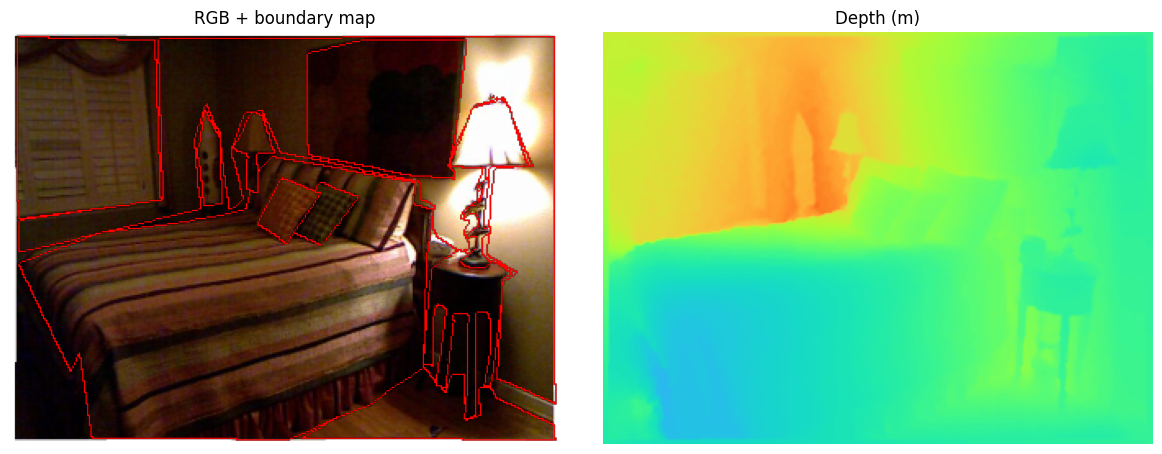

In [ ]:
tiny = NYUSeg(SPLITS["pool"][:16], train=True)
loader = DataLoader(tiny, batch_size=4, shuffle=False, num_workers=0)
batch = next(iter(loader))
for k, v in batch.items():
    print(f"{k:<6}", tuple(v.shape), v.dtype)
print("largest instance index in batch:", batch["inst"].max().item())
print(f"fraction of pixels with inst == 0: {(batch['inst'] == 0).float().mean():.2%}")

# (a) eval mode is deterministic
ev = NYUSeg(SPLITS["pool"][:16], train=False)
a, b = ev[0], ev[0]
print("(a) bit-identical:", all(torch.equal(a[k], b[k]) for k in a if torch.is_tensor(a[k])))

# (b) train mode: both flips occur, boundaries still follow the objects
tr = NYUSeg(SPLITS["pool"][:16], train=True)
ref = ev[0]
ref_b = boundary_map(ref["inst"][None])
ref_b_flip = torch.flip(ref_b, dims=[-1])
n_flip, aligned = 0, True
for _ in range(40):
    s = tr[0]
    flipped = torch.equal(s["rgb"], torch.flip(ref["rgb"], dims=[-1]))
    assert flipped or torch.equal(s["rgb"], ref["rgb"]), "sample is neither original nor mirrored"
    n_flip += int(flipped)
    target = ref_b_flip if flipped else ref_b
    tol = F.max_pool2d(target, (1, 3), stride=1, padding=(0, 1))   # mirroring shifts a boundary by <= 1 px
    aligned &= bool((boundary_map(s["inst"][None]) <= tol).all())
print(f"(b) flipped {n_flip}/40, unflipped {40 - n_flip}/40, boundaries aligned: {aligned}")

# visual check
s = tr[0]
bm = boundary_map(s["inst"][None])[0, 0].numpy()
img = (s["rgb"] * IMNET_STD + IMNET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(img); ax[0].imshow(np.ma.masked_where(bm == 0, bm), cmap="autumn"); ax[0].set_title("RGB + boundary map")
ax[1].imshow(s["depth"][0], cmap="turbo", vmin=0, vmax=6); ax[1].set_title("Depth (m)")
for x_ in ax: x_.axis("off")
plt.tight_layout(); plt.show()

A helper used by every later section (provided): move a batch to the GPU and build the validity mask.

In [ ]:
def to_dev(batch):
    out = {k: (v.to(DEV, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}
    return out

def valid_mask(depth):
    return (depth > MIN_DEPTH) & (depth < MAX_DEPTH)

## 4. Metrics: implement them before trusting them

Every number in this project is one of five quantities, each small enough to compute on paper. As with IoU and mAP in detection, you do it on paper first, then in code, and you meet the awkward edge cases yourself. For predicted depth $\hat d_p$ and ground truth $d_p$ over the set $V$ of valid pixels ($d_p$ inside the valid range):

$$\text{Abs Rel} = \frac{1}{|V|}\sum_{p\in V}\frac{|\hat d_p - d_p|}{d_p}, \qquad \text{RMSE} = \sqrt{\frac{1}{|V|}\sum_{p\in V}(\hat d_p - d_p)^2},$$

$$\delta_k = \frac{1}{|V|}\,\Big|\Big\{p\in V:\ \max\!\Big(\frac{\hat d_p}{d_p},\frac{d_p}{\hat d_p}\Big) < 1.25^k\Big\}\Big|, \qquad k = 1,2,3.$$

Lower is better for Abs Rel and RMSE; higher is better for $\delta$. The $\delta$ thresholds are strict inequalities.

**Q4.1.** Before writing any code, compute all five metrics on paper for these four pixels. Give each as an exact fraction or expression and as a decimal. One of the four pixels is *invalid*: decide what that means for $|V|$.

| pixel | predicted $\hat d$ (m) | ground truth $d$ (m) |
|---|---|---|
| 1 | 1.0 | 1.0 |
| 2 | 2.0 | 2.5 |
| 3 | 4.0 | 3.0 |
| 4 | 5.0 | 0.0 |

Pixel 2's ratio is *exactly* 1.25. Say what $\delta_1$ is under the strict inequality and what it would have been under $\le$.

*Answer:*
Pixel 4 is the *invalid* pixel. The set V is the set of valid pixels meaning the $|V| \le |pixels|$, pixels is the set of all pixels.
$\delta_1$ passes under either rule.

**Q4.2.** Implement `depth_metrics(pred, gt, mask=None)` for two NumPy arrays of the same shape, returning a dict with keys `absrel`, `rmse`, `d1`, `d2`, `d3`. A pixel is valid if `gt` is strictly inside $(\texttt{MIN\_DEPTH}, \texttt{MAX\_DEPTH})$ and, if given, `mask` is true there. If **no** pixel is valid, return `nan` for every metric rather than crashing or returning zeros. Check it on the table from Q4.1 and on an all-invalid input, and compare with your paper answers.

In [ ]:
def depth_metrics(pred, gt, mask=None):
    # YOUR CODE HERE
    ...
    pred = np.asarray(pred, dtype=np.float64)
    gt = np.asarray(gt, dtype=np.float64)
    if pred.shape != gt.shape:
        raise ValueError(f"shape mismatch: {pred.shape} vs {gt.shape}")

    # Strict bounds; NaN gt compares False, so it is excluded automatically.
    valid = (gt > MIN_DEPTH) & (gt < MAX_DEPTH)
    if mask is not None:
        mask = np.asarray(mask, dtype=bool)
        if mask.shape != gt.shape:
            raise ValueError(f"mask shape mismatch: {mask.shape} vs {gt.shape}")
        valid &= mask

    if not valid.any():
        return {k: float("nan") for k in ("absrel", "rmse", "d1", "d2", "d3")}

    p = pred[valid]
    g = gt[valid]
    # Guard the ratio against non-positive / NaN predictions: clamp to MIN_DEPTH.
    p = np.where(np.isfinite(p) & (p > MIN_DEPTH), p, MIN_DEPTH)

    err = p - g
    ratio = np.maximum(p / g, g / p)
    return {
        "absrel": float(np.mean(np.abs(err) / g)),
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "d1": float(np.mean(ratio < 1.25)),
        "d2": float(np.mean(ratio < 1.25 ** 2)),
        "d3": float(np.mean(ratio < 1.25 ** 3)),
    }
DEPTH_KEYS = ("absrel", "rmse", "d1", "d2", "d3")
pred_toy = np.array([1.0, 2.0, 4.0, 5.0]); gt_toy = np.array([1.0, 2.5, 3.0, 0.0])
# print(depth_metrics(pred_toy, gt_toy))
# print(depth_metrics(pred_toy, np.zeros(4)))
paper = {"absrel": 8 / 45, "rmse": math.sqrt(5 / 12), "d1": 1 / 3, "d2": 1.0, "d3": 1.0}
got = depth_metrics(pred_toy, gt_toy)
print(f"{'metric':<8}{'paper':>12}{'code':>12}")
for k in DEPTH_KEYS:
    print(f"{k:<8}{paper[k]:>12.6f}{got[k]:>12.6f}")
    assert np.isclose(got[k], paper[k]), k

# all-invalid inputs -> nan everywhere
for name, g_, m_ in [("gt all zero", np.zeros(4), None),
                     ("empty mask", gt_toy, np.zeros(4, bool)),
                     ("gt all NaN", np.full(4, np.nan), None)]:
    out = depth_metrics(pred_toy, g_, m_)
    assert all(np.isnan(v) for v in out.values()), name
    print(f"{name:<12} -> all nan")

# strict bounds: gt exactly at MIN_DEPTH or MAX_DEPTH is invalid
b = depth_metrics(np.array([1.0, 1.0, 1.0]), np.array([MIN_DEPTH, MAX_DEPTH, 1.0]))
assert b["absrel"] == 0.0 and b["d1"] == 1.0          # only the third pixel counted
print("boundary pixels excluded (strict)")

metric         paper        code
absrel      0.177778    0.177778
rmse        0.645497    0.645497
d1          0.333333    0.333333
d2          1.000000    1.000000
d3          1.000000    1.000000
gt all zero  -> all nan
empty mask   -> all nan
gt all NaN   -> all nan
boundary pixels excluded (strict)


**Q4.3.** The standard NYU evaluation only scores pixels inside the **Eigen crop** (rows 45 to 470, columns 41 to 600 of a $480 \times 640$ image), because the borders of Kinect depth maps are unreliable. Write `eigen_mask(h=480, w=640)` returning a boolean array that is true inside the crop, and report the fraction of the image it keeps.

Then, on paper: image A has 90,000 valid pixels and Abs Rel 0.10; image B has 10,000 valid pixels and Abs Rel 0.30. What do you get if you average the two images' Abs Rel (the *per-image* mean) and what if you pool all valid pixels (the *pooled* mean)? Which one will this project report, and why does the choice matter when comparing against published NYU numbers?

In [ ]:
def eigen_mask(h=480, w=640):
    # YOUR CODE HERE
    ...
    r0, r1 = 45, 471    # slice ends are exclusive, so 471 includes row 470
    c0, c1 = 41, 601    # likewise 601 includes column 600
    if (h, w) != (480, 640):
        sy, sx = h / 480, w / 640
        r0, r1 = int(round(r0 * sy)), int(round(r1 * sy))
        c0, c1 = int(round(c0 * sx)), int(round(c1 * sx))
    m = np.zeros((h, w), dtype=bool)
    m[r0:r1, c0:c1] = True
    return m

EIGEN = eigen_mask()
print("fraction kept:", EIGEN.mean())
ys, xs = np.where(EIGEN)
print(EIGEN.shape, int(EIGEN.sum()), EIGEN.mean())
print(ys.min(), ys.max(), xs.min(), xs.max())

fraction kept: 0.7765625
(480, 640) 238560 0.7765625
45 470 41 600


*Answer (per-image vs pooled):*
Per-image mean: (0.10 + 0.30)/2 = 0.20
Pooled mean: (90,000·0.10 + 10,000·0.30) / (90,000 + 10,000) = (9,000 + 3,000) / 100,000 = 0.12

**Q4.4.** The object-level evaluation replaces bounding boxes with the **ground-truth instance masks**. Write `object_records(pred, gt, cls, inst, valid, min_pixels=100)` for one image at native resolution (all arrays $480 \times 640$; `valid` is the Eigen crop combined with the depth-range check). For every distinct object (a distinct `(cls, inst)` pair with `cls > 0`), return one dict with keys `cls`, `inst`, `n_valid` (valid pixels in the object), `area_frac` (the object's pixel count over the whole image, valid or not, divided by 640 × 480), `absrel`, `rmse`, `d1`, and `mean_gt` (mean ground-truth depth over its valid pixels). Skip objects with fewer than `min_pixels` valid pixels, and say in a comment why a tiny object's Abs Rel is not worth reporting. Test it on a toy $6 \times 6$ example with two instances of the same class, where you can verify the numbers by hand.

In [ ]:
def object_records(pred, gt, cls, inst, valid, min_pixels=100):
    # YOUR CODE HERE
    ...
    """One record per distinct (cls, inst) object with cls > 0.

    Metrics use only pixels where `valid` is true (Eigen crop AND depth-range
    check, built by the caller). `area_frac` counts ALL of the object's pixels,
    valid or not, over the whole image.

    Objects with fewer than `min_pixels` valid pixels are skipped: a mean over a
    handful of pixels is dominated by one or two noisy Kinect readings or edge
    pixels, so a tiny object's Abs Rel is too high-variance to mean anything,
    and a few such objects would swing a per-object average.
    """
    pred = np.asarray(pred, dtype=np.float64)
    gt = np.asarray(gt, dtype=np.float64)
    cls = np.asarray(cls)
    inst = np.asarray(inst)
    valid = np.asarray(valid, dtype=bool)
    if not (pred.shape == gt.shape == cls.shape == inst.shape == valid.shape):
        raise ValueError("all arrays must share one shape")

    # Instance ids may repeat across classes, so identity is the (cls, inst) pair.
    fg = cls > 0
    if not fg.any():
        return []
    pairs = np.unique(np.stack([cls[fg], inst[fg]], axis=1), axis=0)

    records = []
    for c, i in pairs:
        obj = (cls == c) & (inst == i)
        sel = obj & valid
        n_valid = int(sel.sum())
        if n_valid == 0 or n_valid < min_pixels:
            continue
        p = pred[sel]
        g = gt[sel]
        p = np.where(np.isfinite(p) & (p > MIN_DEPTH), p, MIN_DEPTH)
        err = p - g
        ratio = np.maximum(p / g, g / p)
        records.append({
            "cls": int(c),
            "inst": int(i),
            "n_valid": n_valid,
            "area_frac": float(obj.sum()) / gt.size,
            "absrel": float(np.mean(np.abs(err) / g)),
            "rmse": float(np.sqrt(np.mean(err ** 2))),
            "d1": float(np.mean(ratio < 1.25)),
            "mean_gt": float(np.mean(g)),
        })
    return records


# toy 6x6: two instances of class 1, plus a tiny class-2 object
gt = np.ones((6, 6)); pred = np.ones((6, 6))
cls = np.zeros((6, 6), int); inst = np.zeros((6, 6), int)
valid = np.ones((6, 6), bool)

cls[0:2, 0:2] = 1; inst[0:2, 0:2] = 1                  # (1,1): 2x2 block
gt[0:2, 0:2] = [[2, 2], [4, 4]]
pred[0:2, 0:2] = [[2, 3], [4, 2]]

cls[3:5, 2:5] = 1; inst[3:5, 2:5] = 2                  # (1,2): 2x3 block
gt[3:5, 2:5] = [[5, 5, 5], [0, 10, 10]]
pred[3:5, 2:5] = [[5, 6, 4], [7, 10, 15]]
valid[4, 2] = False                                     # no GT at (4,2)

cls[5, 5] = 2; inst[5, 5] = 1                           # (2,1): 1 pixel, same inst id as (1,1)
gt[5, 5] = 3; pred[5, 5] = 3

recs = object_records(pred, gt, cls, inst, valid, min_pixels=4)
print(pd.DataFrame(recs).to_string(index=False))

hand = [dict(cls=1, inst=1, n_valid=4, area_frac=4/36, absrel=1/4,  rmse=np.sqrt(5/4),  d1=1/2, mean_gt=3.0),
        dict(cls=1, inst=2, n_valid=5, area_frac=6/36, absrel=0.18, rmse=np.sqrt(27/5), d1=3/5, mean_gt=7.0)]
assert len(recs) == 2
for r, h in zip(recs, hand):
    for k, v in h.items():
        assert np.isclose(r[k], v), (k, r[k], v)
print("min_pixels=4: matches hand values")
print("min_pixels=100:", object_records(pred, gt, cls, inst, valid))
print("min_pixels=1:", [(r["cls"], r["inst"]) for r in object_records(pred, gt, cls, inst, valid, min_pixels=1)])

 cls  inst  n_valid  area_frac  absrel     rmse  d1  mean_gt
   1     1        4   0.111111    0.25 1.118034 0.5      3.0
   1     2        5   0.166667    0.18 2.323790 0.6      7.0
min_pixels=4: matches hand values
min_pixels=100: []
min_pixels=1: [(1, 1), (1, 2), (2, 1)]


**Q4.5.** For a mobility aid, an error at 1 m matters more than the same error at 8 m, and it matters whether the pixel belongs to a labelled object or to the unlabelled background. Write `strata_records(pred, gt, cls, valid)` returning a dict mapping each stratum name to a pair `(sum_absrel, n)`, where `sum_absrel` is the **sum** (not mean) of per-pixel relative errors over the valid pixels in the stratum, and `n` is their count. The strata are: four distance bands by *ground-truth* depth, `"0-2m"`, `"2-4m"`, `"4-6m"`, `"6-10m"` (lower edge inclusive, upper edge exclusive), and two label strata, `"labelled"` (`cls > 0`) and `"unlabelled"` (`cls == 0`). Returning sums and counts rather than means is deliberate: it is what lets Section 12 pool strata correctly across images. In a comment, say why averaging per-image stratum means would be wrong when a stratum is empty in most images.

In [ ]:
# (name, lower inclusive, upper exclusive). Note gt exactly 10.0 is in no band.
BANDS = [("0-2m", 0.0, 2.0), ("2-4m", 2.0, 4.0),
         ("4-6m", 4.0, 6.0), ("6-10m", 6.0, 10.0)]
def strata_records(pred, gt, cls, valid):
    # YOUR CODE HERE
    ...
    """Return {stratum: (sum_absrel, n)} over valid pixels.

    Sums and counts are returned instead of means on purpose. A per-image
    stratum mean is 0/0 whenever the stratum is empty in that image (e.g. "0-2m"
    in most frames), so you must either skip those images or count them as 0.
    Skipping makes every image that has the stratum weigh the same, whether it
    has 3 pixels or 30,000, so a handful of noisy pixels in one frame count as
    much as a whole close-up scene. Counting empties as 0 drags the average
    down for no reason. Sums and counts avoid both: add them across images and
    divide once at the end, sum_total / n_total, so every pixel in the stratum
    counts equally and an empty stratum contributes (0.0, 0), which is
    harmless. That final division is a pooled-over-pixels mean, which is a
    different protocol from the per-image headline Abs Rel. Label it as such.
    """
    pred = np.asarray(pred, dtype=np.float64)
    gt = np.asarray(gt, dtype=np.float64)
    cls = np.asarray(cls)
    valid = np.asarray(valid, dtype=bool)
    if not (pred.shape == gt.shape == cls.shape == valid.shape):
        raise ValueError("all arrays must share one shape")

    # The caller's `valid` should already include the depth-range check, but a
    # gt of 0 or NaN would make the relative error inf/NaN, so refuse those here.
    valid = valid & np.isfinite(gt) & (gt > MIN_DEPTH)

    # Per-pixel relative error at valid pixels only; others are never read.
    p = np.where(np.isfinite(pred) & (pred > MIN_DEPTH), pred, MIN_DEPTH)
    safe_gt = np.where(valid, gt, 1.0)   # avoid dividing by invalid gt (e.g. 0)
    rel = np.abs(p - safe_gt) / safe_gt

    masks = {name: valid & (gt >= lo) & (gt < hi) for name, lo, hi in BANDS}
    masks["labelled"] = valid & (cls > 0)
    masks["unlabelled"] = valid & (cls == 0)

    return {name: (float(rel[m].sum()), int(m.sum())) for name, m in masks.items()}

**Q4.6.** Metrics need anchors. Without a sense of what a *trivial* predictor scores, "Abs Rel 0.12" is just a number. Compute, on the **test** images with the Eigen crop, the per-image mean of each of the five metrics for two trivial predictors that use no image information at all:

- a **constant**: the median ground-truth depth over all valid pixels of the training pool, as one number for every pixel;
- a **mean depth map**: the per-pixel mean ground-truth depth over the 1,000 training-pool images (computed in a loop over the memory-mapped array, not by loading it all at once).

These are sanity checks, not experimental conditions. Report both rows, and say what each tells you about how much of NYU's depth is explained by "indoor rooms are laid out in similar ways".

In [ ]:
# YOUR CODE HERE
EIGEN = eigen_mask()                      # 480x640, built once
H, W = EIGEN.shape
NBINS = 100_000                           # median resolution (MAX-MIN)/NBINS ~ 1e-4 m


def load_depth(f, i):
    return f["depths"][i].T.astype(np.float64)       # (480, 640), metres, one image at a time


def valid_px(g):
    return EIGEN & (g > MIN_DEPTH) & (g < MAX_DEPTH)  # Eigen crop AND range check


def pool_median_and_mean_map(f, idx):
    """One pass over the pool, one image in memory at a time.
    median: streaming histogram, linear interpolation inside the median bin.
    mean map: per-pixel sum/count over VALID samples (zeros are not averaged in)."""
    hist = np.zeros(NBINS, dtype=np.int64)
    s = np.zeros((H, W)); n = np.zeros((H, W), dtype=np.int64)
    for i in idx:
        g = load_depth(f, i)
        m = valid_px(g)
        hist += np.histogram(g[m], bins=NBINS, range=(MIN_DEPTH, MAX_DEPTH))[0]
        s[m] += g[m]; n[m] += 1
    total = int(hist.sum()); cum = np.cumsum(hist)
    b = int(np.searchsorted(cum, total / 2.0))
    before = cum[b - 1] if b > 0 else 0
    med = MIN_DEPTH + (b + (total / 2.0 - before) / max(hist[b], 1)) * (MAX_DEPTH - MIN_DEPTH) / NBINS
    mean_map = np.full((H, W), med)                   # fallback where no valid sample
    has = n > 0
    mean_map[has] = s[has] / n[has]
    uncovered = int((EIGEN & ~has).sum())             # in-crop pixels that fell back to the median
    return med, total, mean_map, uncovered


def eval_predictor(f, idx, pred_map):
    """Per-image metrics over the Eigen crop, then mean over images.
    Images with no valid pixel give nan; they are excluded and counted."""
    rows = np.array([[depth_metrics(pred_map, load_depth(f, i), mask=EIGEN)[k]
                      for k in DEPTH_KEYS] for i in idx])
    n_empty = int(np.isnan(rows[:, 0]).sum())
    return dict(zip(DEPTH_KEYS, np.nanmean(rows, axis=0))), n_empty

SPLIT = make_splits(scene_group, CONFIG["seed"],CONFIG["n_pool"], CONFIG["n_val"], CONFIG["n_test"])
t0 = time.time()
MED, N_PX, MEAN_MAP, UNCOVERED = pool_median_and_mean_map(f, SPLIT["pool"])
CONST_MAP = np.full((H, W), MED)
print(f"pool: {len(SPLIT['pool'])} images, {N_PX:,} valid px, median = {MED:.4f} m, "
      f"in-crop px without training data: {UNCOVERED}  ({time.time()-t0:.0f}s)")

BASELINES = {}
for name, pm in [("constant (pool median)", CONST_MAP), ("mean depth map", MEAN_MAP)]:
    BASELINES[name], n_empty = eval_predictor(f, SPLIT["test"], pm)
    print(f"{name}: {len(SPLIT['test'])} test images, {n_empty} excluded as empty")

baseline_df = pd.DataFrame(BASELINES).T[list(DEPTH_KEYS)]
display(baseline_df.round(4))

pool: 1000 images, 238,560,000 valid px, median = 2.5370 m, in-crop px without training data: 0  (20s)
constant (pool median): 349 test images, 0 excluded as empty
mean depth map: 349 test images, 0 excluded as empty


,absrel,rmse,d1,d2,d3
constant (pool median),0.4221,1.2106,0.3727,0.6534,0.8355
mean depth map,0.4272,1.1295,0.3980,0.6939,0.8706


*Answer:*

## 5. The segmentation-informed model at N = 0

The starting point is a pretrained monocular depth model: **Depth Anything V2 (Small, metric indoor)**, a DINOv2 vision transformer with a DPT decoder, 24.8 M parameters, fine-tuned by its authors on the synthetic Hypersim indoor dataset to output depth directly in **metres**. It has never seen a Kinect image or any NYU image, which makes it a fair zero-shot starting point.

It cannot accept instance masks as it stands. So we wrap it:

```
RGB ──▶ pretrained depth model ──▶ base depth ─┐
                                               ├──▶ small conv head ──▶ log-correction r
class ids ──▶ embedding ───────────────────────┤                             │
instance boundaries ───────────────────────────┤                             ▼
instance-pooled log-depth, deviation from it ──┘            final depth = base depth × exp(r)
```

The head's last layer is **initialised to zero**, so at the start $r = 0$ and the final depth is *exactly* the pretrained model's prediction. That is what makes N = 0 well defined: the model accepts the masks but has learned nothing from them yet. Training then teaches the head (and gently adapts the base model) to use them.

**Q5.1.** Load the pretrained model with `AutoModelForDepthEstimation.from_pretrained(CONFIG["pretrained_id"])` and put it in eval mode on the GPU. Print its parameter count. Take one batch of 4 test images from `NYUSeg(SPLITS["test"][:4])`, run the model on `batch["rgb"]` via `base(pixel_values=...).predicted_depth`, and report the output's shape, and its minimum, maximum and mean beside the ground-truth depth's mean for the same batch. Is the output in metres, and is it at the input resolution? Look at the ratio of the two means: what do you notice before you have computed a single metric?

In [ ]:
base = AutoModelForDepthEstimation.from_pretrained(CONFIG["pretrained_id"]).to(DEV).eval()
n_params = sum(p.numel() for p in base.parameters())
print(f"parameters: {n_params/1e6:.1f} M")

b = to_dev(next(iter(DataLoader(NYUSeg(SPLITS["test"][:4]), batch_size=4))))
with torch.no_grad():
    out = base(pixel_values=b["rgb"]).predicted_depth

gt_valid = b["depth"][valid_mask(b["depth"])]
print("rgb input shape :", tuple(b["rgb"].shape))
print("output shape    :", tuple(out.shape))
print(f"pred  min/max/mean = {out.min().item():.3f} / {out.max().item():.3f} / {out.mean().item():.3f}")
print(f"gt valid mean      = {gt_valid.mean().item():.3f}")
print(f"ratio gt mean / pred mean = {gt_valid.mean().item() / out.mean().item():.3f}")

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

parameters: 24.8 M
rgb input shape : (4, 3, 252, 336)
output shape    : (4, 252, 336)
pred  min/max/mean = 1.484 / 7.425 / 4.720
gt valid mean      = 2.762
ratio gt mean / pred mean = 0.585


**Note**
The output is in metres: values run from 1.48 to 7.43, with a mean of 4.72. It is at the input resolution, (4, 252, 336). The ground-truth mean is 2.76 m, so the ratio of the means is 0.585. The model predicts rooms about 1.7× deeper than the Kinect measured, before any metric is computed.

**Q5.2.** Write `instance_pool(values, inst)`, the third ingredient from Section 3. `values` is $(B, 1, H, W)$ float and `inst` is $(B, H, W)$ long with dense indices as in Q3.2. Return a $(B, 1, H, W)$ tensor in which every pixel holds the **mean of `values` over all pixels of its own instance in its own image**. Pixels with `inst == 0` (unlabelled) are not an object, so they must simply keep their own value. No loop over instances or pixels: use `scatter_add_` over a flattened index, offset per image so that image 3's instance 2 is not mixed up with image 0's instance 2.

First work out on paper what the function should return for one image with `values = [[1, 2, 3], [4, 5, 6]]` and `inst = [[1, 1, 2], [1, 2, 0]]`, then check it.

In [ ]:
def instance_pool(values, inst):
    B, _, H, W = values.shape
    v32 = values.float()
    K = int(inst.max().item()) + 1
    offset = torch.arange(B, device=inst.device).view(B, 1, 1) * K     # separate images
    flat_idx = (inst + offset).reshape(-1)
    flat_val = v32.reshape(-1)

    sums = torch.zeros(B * K, device=values.device).scatter_add_(0, flat_idx, flat_val)
    cnts = torch.zeros(B * K, device=values.device).scatter_add_(0, flat_idx, torch.ones_like(flat_val))
    means = sums / cnts.clamp(min=1)

    pooled = means[flat_idx].view(B, 1, H, W)
    out = torch.where((inst == 0).unsqueeze(1), v32, pooled)           # unlabelled keeps own value
    return out.to(values.dtype)

v = torch.tensor([[1., 2., 3.], [4., 5., 6.]]).view(1, 1, 2, 3)
i = torch.tensor([[1, 1, 2], [1, 2, 0]]).view(1, 2, 3)
print(instance_pool(v, i))
# paper: inst 1 = {1,2,4} -> 7/3 = 2.3333 ; inst 2 = {3,5} -> 4 ; unlabelled 6 stays 6
# expected [[2.3333, 2.3333, 4.0], [2.3333, 4.0, 6.0]]

tensor([[[[2.3333, 2.3333, 4.0000],
          [2.3333, 4.0000, 6.0000]]]])


**Q5.3.** Write `SegDepthNet`. It wraps `base` and its `forward(rgb, cls, inst)` takes the batch tensors and returns the final depth $(B, 1, h, w)$ in metres. Steps: (1) run the base model for the base depth and add a channel axis; (2) take $\log$ of the base depth (clamped at `MIN_DEPTH`) and apply `instance_pool` to it, and also form the deviation (log-depth minus pooled log-depth); (3) look up the class embedding and move channels first; (4) build the boundary map; (5) concatenate RGB (3), log base depth (1), class embedding (`emb_dim`), boundary (1), pooled log-depth (1) and deviation (1) channels; (6) pass through a small conv head, which you design (a suggestion: three 3×3 convolutions with GroupNorm and ReLU, dilations 1, 2, 4, then a final 3×3 convolution to one channel); (7) return `base_depth * exp(r)`. The final convolution's weights **and bias must be zero at initialisation**.

Write the class, then run the provided check below it. The check must print exactly `0.0`.

In [ ]:
class SegDepthNet(nn.Module):
    def __init__(self, base, n_classes=CONFIG["n_classes"], emb_dim=CONFIG["emb_dim"], ch=CONFIG["head_ch"]):
        super().__init__()
        self.base = base
        self.cls_emb = nn.Embedding(n_classes + 1, emb_dim)
        in_ch = 3 + 1 + emb_dim + 1 + 1 + 1
        self.head = nn.Sequential(
            nn.Conv2d(in_ch, ch, 3, padding=1, dilation=1), nn.GroupNorm(8, ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=2, dilation=2),    nn.GroupNorm(8, ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=4, dilation=4),    nn.GroupNorm(8, ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, 1, 3, padding=1),
        )
        nn.init.zeros_(self.head[-1].weight)       # r = 0 at init -> output == pretrained model
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, rgb, cls, inst):
        # (1) base depth in metres, with a channel axis
        base_depth = self.base(pixel_values=rgb).predicted_depth
        if base_depth.dim() == 3:
            base_depth = base_depth.unsqueeze(1)
        if base_depth.shape[-2:] != rgb.shape[-2:]:
            base_depth = F.interpolate(base_depth, size=rgb.shape[-2:], mode="bilinear", align_corners=False)
        base_depth = base_depth.float()

        # (2) log-depth, instance-pooled log-depth, deviation
        log_d = torch.log(base_depth.clamp(min=MIN_DEPTH))
        pooled = instance_pool(log_d, inst)
        dev = log_d - pooled

        # (3) class embedding, channels first
        emb = self.cls_emb(cls).permute(0, 3, 1, 2)
        # (4) boundaries
        bnd = boundary_map(inst)

        # (5) concatenate: 3 + 1 + emb_dim + 1 + 1 + 1
        feat = torch.cat([rgb.float(), log_d, emb.float(), bnd, pooled, dev], dim=1)

        # (6)-(7) head predicts a log-correction
        r = self.head(feat).float()
        return base_depth * torch.exp(r)

The identity check (provided). It compares your wrapper against the bare pretrained model on the same inputs; if it does not print `0.0`, the zero-initialisation or the base-depth path is wrong, and **N = 0 is not the pretrained model**, which would invalidate the whole learning curve.

In [ ]:
net = SegDepthNet(base).to(DEV).eval()
b = to_dev(next(iter(DataLoader(NYUSeg(SPLITS["test"][:4]), batch_size=4))))
with torch.no_grad():
    out_net = net(b["rgb"], b["cls"], b["inst"])
    out_base = base(pixel_values=b["rgb"]).predicted_depth.unsqueeze(1)
print("max |wrapper - pretrained| =", (out_net - out_base).abs().max().item())
print("trainable parameters:", f"{sum(p.numel() for p in net.parameters() if p.requires_grad):,}",
      "· of which new:", f"{sum(p.numel() for n_, p in net.named_parameters() if not n_.startswith('base.')):,}")

max |wrapper - pretrained| = 0.0
trainable parameters: 24,825,042 · of which new: 39,953


**Q5.4.** Write `evaluate_model(model, indices, bs=8)`, the single evaluation routine used for every experiment. It runs the model over the given images with `full_res=True`, **upsamples each prediction bilinearly to $480 \times 640$** (provided in `predict_fullres`), and for every image computes: the five metrics under the Eigen crop and depth-range mask (`depth_metrics`), the object records (`object_records`) and the strata records (`strata_records`). It returns a dict of three DataFrames: `per_image` (one row per image: `index` plus the five metric columns), `objects` (one row per object with an `image` column added) and `strata` (one row per image and stratum: `image`, `stratum`, `sum_absrel`, `n`). The model must be in eval mode and no gradients may be computed.

Run it for the untrained `net` on `SPLITS["test"]`, store the result as `RESULTS[0]` together with `summary` (the mean of each metric over images, plus `best_step=0` and `minutes=0.0`), print the five means, and log them to a W&B run named `N0-pretrained-seg` with a config that carries the whole `CONFIG`, the model id, the split sizes and the number of training images (0).

In [ ]:
METRIC_COLS = ["absrel", "rmse", "d1", "d2", "d3"]

def predict_fullres(model, rgb, cls, inst):
    # (B,1,h,w) prediction at network resolution -> (B,480,640) at native resolution
    with torch.no_grad():
        pred = model(rgb, cls, inst)
    return F.interpolate(pred.float(), size=(480, 640), mode="bilinear", align_corners=False)[:, 0]


def summarize(per_image):
    return per_image[METRIC_COLS].mean().to_dict()


def evaluate_model(model, indices, bs=8):
    model.eval()
    loader = DataLoader(NYUSeg(indices, train=False, full_res=True), batch_size=bs, shuffle=False, num_workers=2)
    per_image, objects, strata = [], [], []
    with torch.no_grad():
        for b in loader:
            b = to_dev(b)
            pred = predict_fullres(model, b["rgb"], b["cls"], b["inst"]).cpu().numpy()
            gt = b["depth_full"].cpu().numpy()
            cls_f = b["cls_full"].cpu().numpy()
            inst_f = b["inst_full"].cpu().numpy()
            idxs = b["index"].cpu().numpy()
            for j in range(len(pred)):
                img = int(idxs[j])
                valid = EIGEN & (gt[j] > MIN_DEPTH) & (gt[j] < MAX_DEPTH)

                m = depth_metrics(pred[j], gt[j], mask=EIGEN)
                per_image.append({"index": img, **{k: m[k] for k in METRIC_COLS}})

                for rec in object_records(pred[j], gt[j], cls_f[j], inst_f[j], valid):
                    objects.append({"image": img, **rec})

                for name, (s, n) in strata_records(pred[j], gt[j], cls_f[j], valid).items():
                    strata.append({"image": img, "stratum": name, "sum_absrel": s, "n": n})

    return {"per_image": pd.DataFrame(per_image),
            "objects": pd.DataFrame(objects),
            "strata": pd.DataFrame(strata)}

In [ ]:
res0 = evaluate_model(net, SPLITS["test"])
res0["history"] = pd.DataFrame()
res0["summary"] = {**summarize(res0["per_image"]), "best_step": 0, "minutes": 0.0}
RESULTS[0] = res0

print("N = 0 test metrics (mean over images):")
for k in METRIC_COLS:
    print(f"  {k:<7}{res0['summary'][k]:.4f}")

run = wandb.init(
    project=CONFIG["wandb_project"], name="N0-pretrained-seg", reinit=True,
    config={"CONFIG": CONFIG, "model_id": CONFIG["pretrained_id"], "n_train": 0,
            "split_sizes": {k: len(v) for k, v in SPLITS.items()}},
)
for k in METRIC_COLS:
    run.summary[f"test_{k}"] = res0["summary"][k]
run.summary["best_step"] = 0
run.summary["minutes"] = 0.0
wandb.finish()

N = 0 test metrics (mean over images):
  absrel 0.6055
  rmse   1.5568
  d1     0.0883
  d2     0.5081
  d3     0.8861


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


best_step,0
minutes,0
test_absrel,0.60554
test_d1,0.08831
test_d2,0.50815
test_d3,0.88613
test_rmse,1.55675


**Q5.5.** A metric error can come from two very different places: the model gets the **overall scale** of a room wrong (everything too near or too far by roughly the same factor), or it gets the **shape** wrong (relative depths between surfaces). Fine-tuning can fix scale with very little data; shape is harder. To tell which one dominates at N = 0, loop over the test images and for each one compute the median of $d/\hat d$ over valid Eigen-crop pixels (call it the image's *scale factor*). Report the mean, median and standard deviation of the scale factors, and draw a histogram of $\log_2$ of the scale factor with a vertical line at 0 (a perfect scale). Then recompute the five metrics after multiplying each prediction by its own image's scale factor. This is an **oracle diagnostic**: it uses ground truth to rescale, so it can never be deployed, and it must not be reported as a result. It only tells you how much of the N = 0 error is scale.

scale factor d/pred: mean 0.648 | median 0.643 | std 0.080


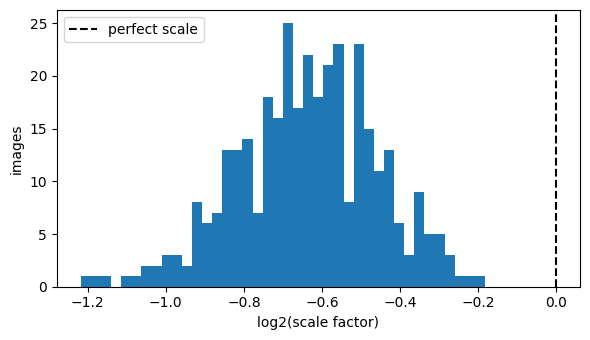

,as predicted (N=0),oracle-rescaled (diagnostic only)
absrel,0.6055,0.1049
rmse,1.5568,0.3939
d1,0.0883,0.8948
d2,0.5081,0.9789
d3,0.8861,0.9937


In [ ]:
net.eval()
loader = DataLoader(NYUSeg(SPLITS["test"], full_res=True), batch_size=8, shuffle=False, num_workers=2)
scales, raw_rows, scaled_rows = [], [], []
with torch.no_grad():
    for b in loader:
        b = to_dev(b)
        pred = predict_fullres(net, b["rgb"], b["cls"], b["inst"]).cpu().numpy()
        gt = b["depth_full"].cpu().numpy()
        for j in range(len(pred)):
            v = EIGEN & (gt[j] > MIN_DEPTH) & (gt[j] < MAX_DEPTH)
            if not v.any():
                continue
            p = np.maximum(pred[j], MIN_DEPTH)
            s = np.median(gt[j][v] / p[v])                    # per-image scale factor
            scales.append(s)
            raw = depth_metrics(pred[j], gt[j], mask=EIGEN)
            scl = depth_metrics(pred[j] * s, gt[j], mask=EIGEN)   # ORACLE rescale
            raw_rows.append([raw[k] for k in METRIC_COLS])
            scaled_rows.append([scl[k] for k in METRIC_COLS])

scales = np.array(scales)
print(f"scale factor d/pred: mean {scales.mean():.3f} | median {np.median(scales):.3f} | std {scales.std():.3f}")

plt.figure(figsize=(6, 3.5))
plt.hist(np.log2(scales), bins=40)
plt.axvline(0, color="k", ls="--", label="perfect scale")
plt.xlabel("log2(scale factor)"); plt.ylabel("images"); plt.legend(); plt.tight_layout(); plt.show()

cmp_df = pd.DataFrame({"as predicted (N=0)": np.mean(raw_rows, axis=0),
                       "oracle-rescaled (diagnostic only)": np.mean(scaled_rows, axis=0)}, index=METRIC_COLS)
display(cmp_df.round(4))

**Q5.6.** Answer using Q5.1, Q5.4 and Q5.5:

- Is the pretrained model's N = 0 error mostly scale or mostly shape? Quote the numbers that tell you.
- The model was fine-tuned on synthetic Hypersim rooms and has never seen a Kinect. Give two reasons its metric scale could be off on NYU.
- Given your answer, which part of the learning curve do you expect to improve fastest as N grows from 0, and which slowest? Write your prediction down now; Section 11 checks it.
- At N = 0 the instance masks are present but unused. Why is this not an RGB-only baseline, and what exactly would be needed to measure how much the masks themselves add? (You are not running that experiment; Section 14 asks you to say so.)

*Answer:*
- **Scale or shape?** Mostly scale. Per-image scale factors (d/d̂) have mean 0.648, median 0.643 and standard deviation 0.080. Every image sits left of the “perfect scale” line in the log₂ histogram, so the pretrained model predicts everything about 1.5× too far, and does so consistently. Rescaling each image with an oracle factor cuts Abs Rel from 0.6055 to 0.1049, RMSE from 1.557 to 0.394 and raises δ₁ from 0.088 to 0.895. About 83% of the Abs Rel error is scale. The remaining 0.105 is shape.

- **Two reasons the scale could be off:** (1) Hypersim is synthetic. Its room sizes, layouts and object clutter differ from real, cramped NYU apartments, and a metric model leans on those learned priors. (2) The camera differs. A different field of view or intrinsics, and different depth conventions or sensor preprocessing (Kinect depth is filled-in and range-limited), change how large a room looks at a given distance, so the same image content maps to different metres.

- **Prediction**: the global scale error should be fixed fastest. Abs Rel, RMSE and δ₁ should fall sharply within the first 100 images. The slowest part should be the remaining shape error: relative depths, edges and thin objects. I expect a steep drop from N = 0 to 100, then small, slowing gains up to N = 1000.

- **Not an RGB-only baseline**: the masks are part of the model’s inputs, but the head’s last layer starts at zero, so N = 0 numerically equals the pretrained RGB-only model. Because of this, N = 0 cannot say what the masks add. Gains from N = 0 to 100 mix two effects: learning NYU’s scale, and learning to use the masks. To isolate the masks, I’d need an RGB-only model with the same architecture and recipe (mask inputs removed or zeroed), fine-tuned on the same N images and compared with the segmentation-informed model at each N

## 6. Training machinery

Every fine-tuned model in Sections 7 to 10 is produced by the **same** routine with the **same** recipe; only the number of training images changes. This section builds that routine and tests it cheaply before spending GPU time on it.

The loss is the **scale-invariant log loss** (SILog) of Eigen et al. (2014), the standard choice for depth. For a valid pixel set $V$ and $g_p = \log\hat d_p - \log d_p$:

$$\mathcal{L} = \alpha\sqrt{\frac{1}{|V|}\sum_{p\in V} g_p^2 - \lambda\Big(\frac{1}{|V|}\sum_{p\in V} g_p\Big)^2}, \qquad \alpha = 10,\ \lambda = 0.85.$$

With $\lambda = 1$ the loss ignores a global scale error entirely; with $\lambda = 0.85$ it keeps 15% of the penalty on scale, which matters here because Q5.5 may have shown that scale is where the pretrained model is weakest.

**Q6.1.** Implement `silog_loss(pred, gt, valid, lam=0.85, alpha=10.0)` for tensors of shape $(B, 1, h, w)$, with `valid` a boolean tensor of the same shape. Compute the loss **per image** over that image's valid pixels and average over the batch, so one image with many valid pixels cannot dominate. Guard against two failure modes: an image with no valid pixels (skip it; if all are skipped return a zero that still has a gradient path), and the square root's infinite gradient at 0 (clamp the quantity under the root at a small positive value).

Before running: predict on paper the loss for `pred = gt`, for `pred = 2*gt` with `lam=1`, and for `pred = 2*gt` with `lam=0.85` (give the last as a number). Then check all three in code, and confirm `loss.backward()` produces finite gradients for `pred = gt`.

In [ ]:
def silog_loss(pred, gt, valid, lam=CONFIG["silog_lambda"], alpha=10.0):
    pred, gt = pred.float(), gt.float()
    losses = []
    for j in range(pred.shape[0]):                     # per image, then average over batch
        v = valid[j]
        if v.sum() == 0:
            continue
        g = torch.log(pred[j][v].clamp(min=MIN_DEPTH)) - torch.log(gt[j][v].clamp(min=MIN_DEPTH))
        q = (g ** 2).mean() - lam * g.mean() ** 2
        losses.append(alpha * torch.sqrt(q.clamp(min=1e-8)))   # clamp: sqrt has infinite gradient at 0
    if not losses:
        return pred.sum() * 0.0                        # zero, but still has a gradient path
    return torch.stack(losses).mean()

# paper: pred=gt -> 0 ; pred=2gt, lam=1 -> 0 ; pred=2gt, lam=0.85 -> 10*sqrt(0.15)*ln2 = 2.6846
gt_t = torch.rand(2, 1, 8, 8) * 5 + 0.5
ok = torch.ones_like(gt_t, dtype=torch.bool)
print("pred=gt            :", silog_loss(gt_t, gt_t, ok).item(), "(about 1e-3 because of the clamp)")
print("pred=2gt, lam=1    :", silog_loss(2 * gt_t, gt_t, ok, lam=1.0).item(), "(about 1e-3)")
print("pred=2gt, lam=0.85 :", silog_loss(2 * gt_t, gt_t, ok, lam=0.85).item(), "(paper 2.6846)")

p = gt_t.clone().requires_grad_(True)
silog_loss(p, gt_t, ok).backward()
print("finite gradients   :", torch.isfinite(p.grad).all().item())
print("all-invalid case   :", silog_loss(p, gt_t, torch.zeros_like(ok)).item())

pred=gt            : 0.0009999999310821295 (about 1e-3 because of the clamp)
pred=2gt, lam=1    : 0.0009999999310821295 (about 1e-3)
pred=2gt, lam=0.85 : 2.6845474243164062 (paper 2.6846)
finite gradients   : True
all-invalid case   : 0.0


**Q6.2.** Decide how long every model trains. There are three defensible policies, and they give different learning curves:

1. **Fixed epochs**: every model sees each of its images the same number of times. N = 100 then gets ten times fewer optimiser updates than N = 1000.
2. **Fixed steps, final checkpoint**: every model gets the same number of updates (`CONFIG["steps"]`), but N = 100 cycles through its images many more times and may overfit.
3. **Fixed steps, best-validation checkpoint**: as 2, but keep the weights from the step with the lowest validation loss.

`CONFIG` is set up for policy 3. Say which policy you would pick, what bias each of the other two introduces into the comparison *across N*, and why the validation images must be disjoint from both training and test images. Also state the one remaining way in which a fixed step budget could still favour large N.

**Answer:**

I would pick policy 3 (fixed steps, best-validation checkpoint). The other two bias the comparison across N in the same direction, making small N look worse. Under fixed epochs, N = 100 gets about ten times fewer updates than N = 1000 and is under-trained, so the curve looks steeper than it should. Under fixed steps with the final checkpoint, N = 100 cycles through its images many times and overfits. Our own run shows this: validation loss was lowest at step 300 and rose from 1.156 to 1.185 by step 1500, while train loss kept falling. Both policies penalise small N for reasons unrelated to how much data there is.

The validation images must be disjoint from training because otherwise “best checkpoint” would just mean the most memorised one, and validation loss would stop signalling overfitting. They must be disjoint from test because choosing a checkpoint on the test images leaks test information into the model and makes the test numbers optimistic.

One remaining way the fixed budget still favours large N is the learning-rate schedule. Small N reaches its best checkpoint early (step 300 for N = 100), while the cosine schedule’s learning rate is still high. Large N reaches its best checkpoint later, after the learning rate has annealed. So small-N models never get the benefit of the decay.

**Q6.3.** Write `train_one_model(n_train, subset_seed=None, seed=0, steps=CONFIG["steps"])`, which returns `(model, history)`. `build_model` and `quick_val` are provided. Your routine must:

1. call `seed_everything(seed)` and build the training subset with `subset_indices`;
2. build a `NYUSeg(..., train=True)` loader with `shuffle=True` and `drop_last=True` and a **validation** loader on `SPLITS["val"]`; cycle through the training loader indefinitely until `steps` optimiser steps are done;
3. use **AdamW** with two parameter groups: the pretrained `base` at `lr_base` and everything else at `lr_head`, both with `weight_decay`;
4. use a schedule with a linear warm-up over `CONFIG["warmup"]` steps followed by cosine decay to zero;
5. use mixed precision (`torch.autocast("cuda", dtype=torch.float16)` with a gradient scaler) and clip the gradient norm at 1.0; compute the loss in float32;
6. every `eval_every` steps (and at the last step), run `quick_val`, append a row `step, train_loss, val_loss, val_absrel` to the history (`train_loss` is the mean over the steps since the last evaluation), and keep a **CPU deep copy** of the weights whenever `val_loss` is the lowest so far;
7. if a W&B run is active (`wandb.run is not None`), log each history row to it;
8. at the end, load the best weights back into the model and return it with `pd.DataFrame(history)`.

In [ ]:
def build_model():
    base = AutoModelForDepthEstimation.from_pretrained(CONFIG["pretrained_id"])
    return SegDepthNet(base).to(DEV)


@torch.no_grad()
def quick_val(model, loader):
    # Validation at network resolution: SILog loss and Abs Rel, averaged over images.
    model.eval()
    sl, ar, n = 0.0, 0.0, 0
    for b in loader:
        b = to_dev(b)
        pred = model(b["rgb"], b["cls"], b["inst"]).float()
        v = valid_mask(b["depth"])
        sl += silog_loss(pred, b["depth"], v).item() * len(pred)
        rel = ((pred - b["depth"]).abs() / b["depth"].clamp(min=MIN_DEPTH))
        ar += sum(rel[j][v[j]].mean().item() for j in range(len(pred)) if v[j].any())
        n += len(pred)
    return sl / n, ar / n


def train_one_model(n_train, subset_seed=None, seed=0, steps=CONFIG["steps"]):
    seed_everything(seed)
    idx = subset_indices(SPLITS["pool"], n_train, subset_seed)

    model = build_model()
    train_loader = DataLoader(NYUSeg(idx, train=True), batch_size=CONFIG["batch_size"], shuffle=True,
                              drop_last=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(NYUSeg(SPLITS["val"]), batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2)

    base_params = list(model.base.parameters())
    other_params = [p for n_, p in model.named_parameters() if not n_.startswith("base.")]
    opt = torch.optim.AdamW(
        [{"params": base_params, "lr": CONFIG["lr_base"]},
         {"params": other_params, "lr": CONFIG["lr_head"]}],
        weight_decay=CONFIG["weight_decay"])

    warm = CONFIG["warmup"]
    def lr_lambda(step):                                   # linear warm-up, then cosine to zero
        if step < warm:
            return (step + 1) / warm
        prog = min(1.0, (step - warm) / max(1, steps - warm))
        return 0.5 * (1 + math.cos(math.pi * prog))
    sched = LambdaLR(opt, lr_lambda)

    use_amp = DEV == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    eval_every = min(CONFIG["eval_every"], max(1, steps // 3))   # smoke tests still evaluate >= 2 times

    def cycle(loader):
        while True:
            for batch in loader:
                yield batch
    it = cycle(train_loader)

    history, best_val, best_state = [], float("inf"), None
    run_loss, run_n = 0.0, 0
    for step in range(1, steps + 1):
        model.train()
        b = to_dev(next(it))
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            pred = model(b["rgb"], b["cls"], b["inst"])
        loss = silog_loss(pred.float(), b["depth"], valid_mask(b["depth"]))   # loss in float32

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()

        run_loss += loss.item(); run_n += 1

        if step % eval_every == 0 or step == steps:
            val_loss, val_absrel = quick_val(model, val_loader)
            row = dict(step=step, train_loss=run_loss / run_n, val_loss=val_loss, val_absrel=val_absrel)
            history.append(row)
            run_loss, run_n = 0.0, 0
            if val_loss < best_val:
                best_val = val_loss
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if wandb.run is not None:
                wandb.log(row, step=step)
            print(f"step {step:>5} | train {row['train_loss']:.4f} | val {val_loss:.4f} | val absrel {val_absrel:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history)

**Q6.4.** Write `run_experiment(n, subset_seed=None, seed=0)`, the one function that produces a row of the learning curve. It must: start a W&B run named `ft-N{n}-s{seed}` (add `-sub{subset_seed}` if `subset_seed` is set) with a config carrying `CONFIG`, `n`, `seed`, `subset_seed` and the number of images in each split; call `train_one_model`; save the model's `state_dict` to `ckpt_path(n, seed)` (provided); call `evaluate_model` on the **test** images; log the five test metrics, the best step and the wall-clock minutes to the run as summary values; finish the run; and return a dict with keys `per_image`, `objects`, `strata`, `history`, and `summary` (the five metric means plus `best_step` and `minutes`). Free the GPU afterwards (`del` the model, `torch.cuda.empty_cache()`), since five models will be trained in one session.

In [ ]:
def ckpt_path(n, seed=0):
    return f"{WORK}/ckpt_N{n}_s{seed}.pt"


def load_ckpt(n, seed=0):
    model = build_model()
    model.load_state_dict(torch.load(ckpt_path(n, seed), map_location=DEV))
    return model.eval()


def run_experiment(n, subset_seed=None, seed=0):
    name = f"ft-N{n}-s{seed}" + (f"-sub{subset_seed}" if subset_seed is not None else "")
    run = wandb.init(
        project=CONFIG["wandb_project"], name=name, reinit=True,
        config={"CONFIG": CONFIG, "n": n, "seed": seed, "subset_seed": subset_seed,
                "model_id": CONFIG["pretrained_id"],
                "split_sizes": {k: len(v) for k, v in SPLITS.items()}})
    t0 = time.time()
    try:
        model, history = train_one_model(n, subset_seed=subset_seed, seed=seed)
        torch.save(model.state_dict(), ckpt_path(n, seed))
        res = evaluate_model(model, SPLITS["test"])
        minutes = (time.time() - t0) / 60
        best_step = int(history.loc[history["val_loss"].idxmin(), "step"])
        summary = {**summarize(res["per_image"]), "best_step": best_step, "minutes": minutes}
        for k in METRIC_COLS:
            run.summary[f"test_{k}"] = summary[k]
        run.summary["best_step"] = best_step
        run.summary["minutes"] = minutes
    finally:
        wandb.finish()

    del model
    gc.collect()
    torch.cuda.empty_cache()
    return {**res, "history": history, "summary": summary}

**Q6.5.** Write `show_predictions(models, idxs)`. `models` is a dict mapping a title (such as `"N=0"` or `"N=100"`) to a model, and `idxs` is a list of dataset indices. Draw one row per image and one column for the RGB image, one for the ground-truth depth, and one per model, all depth panels using the **same colour scale** (0 to 6 m is a good range). Put each model's per-image Abs Rel under its panel, computed with the same Eigen mask as the evaluation. Evaluate on the full-resolution prediction. `VIS_IDX` below is the fixed set of four test images used in every comparison from here on: **never choose images to show after seeing the results**.

In [ ]:
VIS_IDX = [int(SPLITS["test"][j]) for j in (0, len(SPLITS["test"]) // 4, len(SPLITS["test"]) // 2, 3 * len(SPLITS["test"]) // 4)]
print("fixed visualisation images:", VIS_IDX)

def show_predictions(models, idxs):
    ds = NYUSeg(idxs, train=False, full_res=True)
    n_rows, n_cols = len(idxs), 2 + len(models)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 2.9 * n_rows),
                             squeeze=False, constrained_layout=True)
    im = None
    for r in range(n_rows):
        s = ds[r]
        b = {k: (v[None].to(DEV) if torch.is_tensor(v) else v) for k, v in s.items()}
        gt = s["depth_full"].numpy()
        img = (s["rgb"] * IMNET_STD + IMNET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[r, 0].imshow(img)
        im = axes[r, 1].imshow(gt, cmap="turbo", vmin=0, vmax=6)
        for c, (title, m) in enumerate(models.items(), start=2):
            m.eval()
            pred = predict_fullres(m, b["rgb"], b["cls"], b["inst"])[0].cpu().numpy()
            ar = depth_metrics(pred, gt, mask=EIGEN)["absrel"]
            axes[r, c].imshow(pred, cmap="turbo", vmin=0, vmax=6)
            axes[r, c].set_xlabel(f"Abs Rel {ar:.3f}")
        if r == 0:
            axes[0, 0].set_title("RGB"); axes[0, 1].set_title("GT depth")
            for c, title in enumerate(models.keys(), start=2):
                axes[0, c].set_title(title)
        for a in axes[r]:
            a.set_xticks([]); a.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.5, label="depth (m)")
    plt.show()

fixed visualisation images: [0, 268, 714, 1128]


**Q6.6.** Smoke-test everything on a small budget before committing to the long runs. With **no** W&B run active, call `train_one_model(100, steps=60)` (set `eval_every` lower inside your routine if needed so that it evaluates at least twice). Report: whether the training loss is finite and falls, the time per step, the peak GPU memory (`torch.cuda.max_memory_allocated()`), and the time one full `evaluate_model` call on the test set takes. From those, estimate the total GPU time for all of Sections 7 to 10 plus the two extra runs in Q11.4, and say whether it fits in your Colab session. If it does not, say what you would shrink (and note that anything you change must change for *every* N).

In [ ]:
assert wandb.run is None, "finish any active W&B run first"
if DEV == "cuda":
    torch.cuda.reset_peak_memory_stats()

t0 = time.time()
m_smoke, h_smoke = train_one_model(100, steps=60)
t_train = time.time() - t0
display(h_smoke)
print("train loss finite:", bool(np.isfinite(h_smoke["train_loss"]).all()),
      "| first -> last:", round(h_smoke["train_loss"].iloc[0], 4), "->", round(h_smoke["train_loss"].iloc[-1], 4))

val_loader_s = DataLoader(NYUSeg(SPLITS["val"]), batch_size=CONFIG["batch_size"], num_workers=2)
t0 = time.time(); quick_val(m_smoke, val_loader_s); t_val = time.time() - t0

n_evals = len(h_smoke)
per_step = (t_train - n_evals * t_val) / 60
print(f"time per step ~ {per_step:.2f} s | quick_val ~ {t_val:.1f} s")
if DEV == "cuda":
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

t0 = time.time(); evaluate_model(m_smoke, SPLITS["test"]); t_eval = time.time() - t0
print(f"full evaluate_model on test: {t_eval:.0f} s")

n_runs = len(CONFIG["train_sizes"]) + 2            # 4 sizes + 2 extra runs for Q11.4
n_val_evals = CONFIG["steps"] // CONFIG["eval_every"]
per_run = CONFIG["steps"] * per_step + n_val_evals * t_val + t_eval
print(f"estimated per run ~ {per_run/60:.1f} min | all {n_runs} runs ~ {n_runs*per_run/60:.0f} min")

del m_smoke; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_834/3596533033.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step    20 | train 2.1842 | val 1.4330 | val absrel 0.1531
step    40 | train 1.3749 | val 1.3290 | val absrel 0.1619
step    60 | train 1.1517 | val 1.2530 | val absrel 0.1368


,step,train_loss,val_loss,val_absrel
0,20,2.184167,1.433009,0.153119
1,40,1.374923,1.329039,0.161876
2,60,1.151654,1.253010,0.136760


train loss finite: True | first -> last: 2.1842 -> 1.1517
time per step ~ 0.35 s | quick_val ~ 2.4 s
peak GPU memory: 2.44 GB
full evaluate_model on test: 129 s
estimated per run ~ 11.4 min | all 6 runs ~ 69 min


**Answer:**

The training loss is finite and falls (2.18 → 1.15 over 60 steps, with validation loss 1.43 → 1.25). Training takes about 0.28 s per step, quick_val about 2.6 s, peak GPU memory is 2.64 GB, and one full evaluate_model on the test set takes 119 s. That gives about 9.5 min per run and about 57 min for all six runs (four sizes plus the two extra Q11.4 runs). The real N = 100 run took 9.1 min, which matches the estimate. This fits comfortably in a Colab session, though a T4 session can still disconnect, which is why checkpoints go to Drive. If it didn’t fit, I would reduce steps or the number of validation evaluations, and change it for every N.

## 7. Fine-tune with 100 labelled images

Same recipe as every other size: `train_one_model` with the shared `CONFIG`, the same step budget, loss, optimiser, validation images and test images. The training set is the first 100 images of the pool. Only the number of training images has changed, and the instance masks are given to the model exactly as before.

**Q7.1.** Run `run_experiment(100)`, store the result in `RESULTS[100]`, and print a one-row table with the number of training images, the five test metrics, the best step and the wall-clock minutes. Also print the same metrics for N = 0 from `RESULTS[0]` beneath it, and the change in each.

In [ ]:
RESULTS[100] = run_experiment(100)

def summary_row(n, s):
    return {"N": n, **{k: s[k] for k in METRIC_COLS}, "best_step": s["best_step"], "minutes": round(s["minutes"], 1)}

t = pd.DataFrame([summary_row(100, RESULTS[100]["summary"]),
                  summary_row(0, RESULTS[0]["summary"])]).set_index("N")
change = (t.loc[100, METRIC_COLS] - t.loc[0, METRIC_COLS]).rename("change (100 - 0)")
display(t.round(4))
display(change.to_frame().T.round(4))

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_834/3596533033.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step   100 | train 1.3056 | val 1.2201 | val absrel 0.1251
step   200 | train 0.7444 | val 1.1839 | val absrel 0.1166
step   300 | train 0.6372 | val 1.1509 | val absrel 0.1142
step   400 | train 0.5537 | val 1.1638 | val absrel 0.1186
step   500 | train 0.5043 | val 1.1677 | val absrel 0.1160
step   600 | train 0.4655 | val 1.1759 | val absrel 0.1168
step   700 | train 0.4346 | val 1.1718 | val absrel 0.1194
step   800 | train 0.3998 | val 1.1767 | val absrel 0.1167
step   900 | train 0.3784 | val 1.1792 | val absrel 0.1181
step  1000 | train 0.3566 | val 1.1798 | val absrel 0.1170
step  1100 | train 0.3377 | val 1.1831 | val absrel 0.1172
step  1200 | train 0.3287 | val 1.1848 | val absrel 0.1171
step  1300 | train 0.3200 | val 1.1858 | val absrel 0.1168
step  1400 | train 0.3149 | val 1.1865 | val absrel 0.1169
step  1500 | train 0.3120 | val 1.1865 | val absrel 0.1168


step,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train_loss,█▄▃▃▂▂▂▂▁▁▁▁▁▁▁
val_absrel,█▃▁▄▂▃▄▃▃▃▃▃▃▃▃
val_loss,█▄▁▂▃▄▃▄▄▄▄▄▅▅▅
best_step,300
minutes,9.17012
step,1500
test_absrel,0.10931
test_d1,0.89062
test_d2,0.98306
test_d3,0.99576


,absrel,rmse,d1,d2,d3,best_step,minutes
N,,,,,,,
100,0.1093,0.3916,0.8906,0.9831,0.9958,300,9.2
0,0.6055,1.5568,0.0883,0.5081,0.8861,0,0.0


,absrel,rmse,d1,d2,d3
change (100 - 0),-0.4962,-1.1651,0.8023,0.4749,0.1096


**Q7.2.** Plot the training history of this run in two panels: training and validation SILog loss against step, and validation Abs Rel against step, with a vertical line at the best step. Then answer:

- At which step is the validation loss lowest, and is that step before the end of the budget? What does that say about whether 100 images overfit within `CONFIG["steps"]` steps?
- Is there a gap between training and validation loss? What does its size tell you about 100 images?
- How does test Abs Rel at N = 100 compare with N = 0? Give the difference. Would you trust a difference that size from one run on 349 images before Section 11? Say why or why not.

*Answer:*

- **Best step**: validation loss is lowest at step 300 of 1500, well before the end of the budget. After that it creeps up from 1.156 to 1.185, while training loss falls from 0.64 to 0.31 and validation Abs Rel stays flat around 0.116–0.118. So 100 images do overfit within the budget, mildly and quickly, and the best-validation checkpoint matters.
- **Train/validation gap**: at step 300 the gap is 0.52 (train 0.636, validation 1.156), and it widens afterwards. A large gap means the model can fit the 100 training images much better than unseen rooms, so 100 images are too few to pin down depth for new scenes. (Part of the gap comes from training loss being averaged over earlier steps with augmentation.)
- **Test Abs Rel**: 0.6055 at N = 0 and 0.1100 at N = 100, a difference of −0.4955. Per-image Abs Rel has a standard deviation of 0.0633 over 349 images, giving a standard error of 0.0034, so the drop is more than 100 standard errors. I would trust that it is real. This is mostly the scale correction from Q5.5, since the oracle-rescaled N = 0 model scores 0.105. The caveat is that this error bar only covers the choice of test images. It doesn’t cover which 100 training images were picked or the random seed, which Section 11 checks.

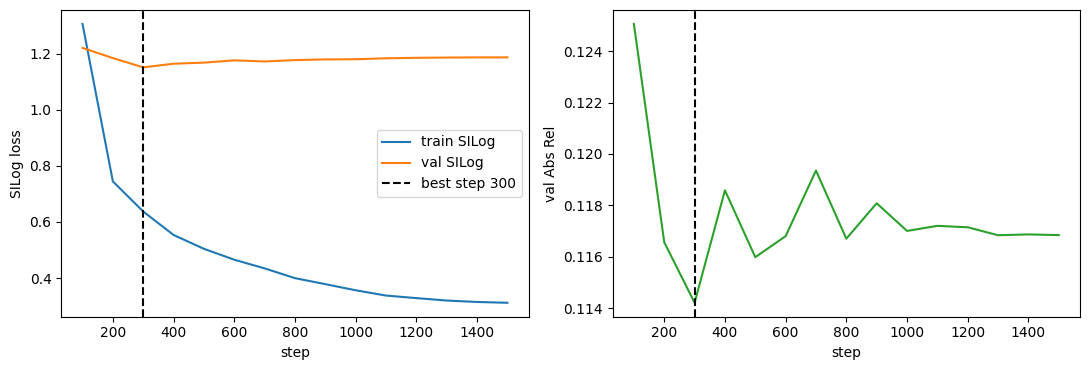

best step 300 of 1500 | train 0.6372 | val 1.1509 | gap 0.5137
test Abs Rel: N=0 0.6055 -> N=100 0.1093 (diff -0.4962)
std of per-image Abs Rel on test: 0.0621 | standard error of the mean: 0.0033


In [ ]:
h = RESULTS[100]["history"]
best = RESULTS[100]["summary"]["best_step"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["step"], h["train_loss"], label="train SILog")
ax[0].plot(h["step"], h["val_loss"], label="val SILog")
ax[0].axvline(best, color="k", ls="--", label=f"best step {best}")
ax[0].set_xlabel("step"); ax[0].set_ylabel("SILog loss"); ax[0].legend()
ax[1].plot(h["step"], h["val_absrel"], color="C2")
ax[1].axvline(best, color="k", ls="--")
ax[1].set_xlabel("step"); ax[1].set_ylabel("val Abs Rel")
plt.tight_layout(); plt.show()

rb = h[h["step"] == best].iloc[0]
print(f"best step {best} of {CONFIG['steps']} | train {rb.train_loss:.4f} | val {rb.val_loss:.4f} | gap {rb.val_loss - rb.train_loss:.4f}")
d = RESULTS[100]["summary"]["absrel"] - RESULTS[0]["summary"]["absrel"]
print(f"test Abs Rel: N=0 {RESULTS[0]['summary']['absrel']:.4f} -> N=100 {RESULTS[100]['summary']['absrel']:.4f} (diff {d:+.4f})")
ai = RESULTS[100]["per_image"]["absrel"]
sd = ai.std()
se = sd / np.sqrt(len(ai))
print(f"std of per-image Abs Rel on test: {sd:.4f} | standard error of the mean: {se:.4f}")

**Q7.3.** Load the N = 0 model (`build_model().eval()`) and the checkpoint for this size (`load_ckpt(100)`) and call `show_predictions` on `VIS_IDX` with both. Describe what changed between the two columns on these four images: edges, large flat surfaces, near and far regions, and any place where the fine-tuned prediction got *worse*. Use only what you can see on these four images, and say that you are doing so.

**Answer:**

On these four images only, N = 100 looks much closer to the ground truth than N = 0. Abs Rel falls from 0.790 to 0.106, 0.426 to 0.065, 0.570 to 0.087 and 0.483 to 0.048.

- **Large flat** surfaces (walls, floors, ceilings): N = 0 keeps the overall layout but paints all of it too far (warm orange and red where the ground truth is green or yellow). N = 100 brings walls and floors to nearly the right colours, with no obvious change in their shape.
- **Near and far**: the error grows with distance. In the closet image the near doors are about 1–1.5 m in the ground truth, but N = 0 predicts about 2.5–3 m. In the living-room image, N = 0 saturates the far wall at the top of the 0–6 m scale, which is more than the ground truth shows. N = 100 matches both. N = 0 never gets the near and far regions right at the same time, which is a scale problem, not an ordering problem.
- **Edges and objects**: the chairs, bed and table are in the right places in both. N = 0 looks slightly sharper on some small structure (thin table and chair legs, the sofa and person on the right of the living-room image). N = 100 is smoother there, closer to the smooth Kinect ground truth.
- **Where N = 100 got worse**: the only place I see a loss is that fine detail. In the living-room image the person and sofa on the right become a soft blob. I can’t say from four images whether this is a systematic loss of detail, and the Abs Rel numbers don’t show it.

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

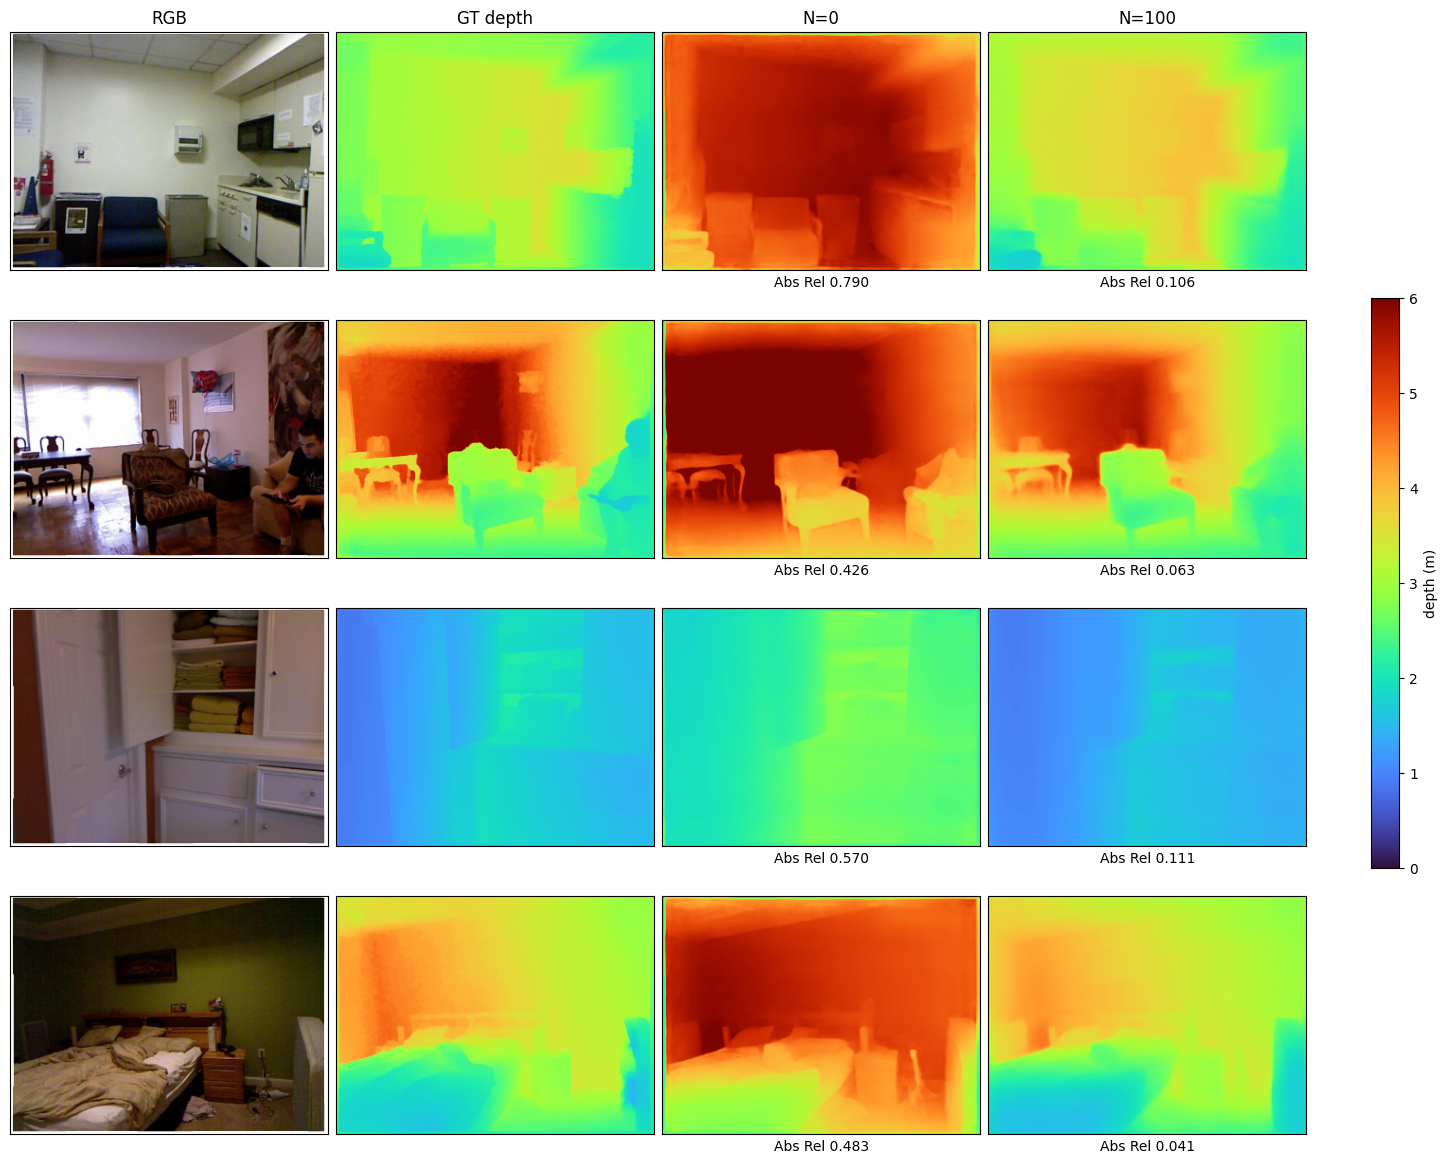

In [ ]:
m0 = build_model().eval()
m100 = load_ckpt(100)
show_predictions({"N=0": m0, "N=100": m100}, VIS_IDX)
del m0, m100; gc.collect(); torch.cuda.empty_cache()

## 8. Fine-tune with 300 labelled images

Same recipe as every other size: `train_one_model` with the shared `CONFIG`, the same step budget, loss, optimiser, validation images and test images. The training set is the first 300 images of the pool, which contain the 100 used in the previous section. Only the number of training images has changed, and the instance masks are given to the model exactly as before.

**Q8.1.** Run `run_experiment(300)`, store the result in `RESULTS[300]`, and print a one-row table with the number of training images, the five test metrics, the best step and the wall-clock minutes. Also print the same metrics for N = 100 from `RESULTS[100]` beneath it, and the change in each.

In [ ]:
import os

WORK = "/content"
os.makedirs(WORK, exist_ok=True)

In [ ]:
# YOUR CODE HERE
RESULTS[300] = run_experiment(300)

def summary_row(n, s):
    return {"N": n, **{k: s[k] for k in METRIC_COLS}, "best_step": s["best_step"], "minutes": round(s["minutes"], 1)}

t = pd.DataFrame([summary_row(300, RESULTS[300]["summary"]),
                  summary_row(100, RESULTS[100]["summary"])]).set_index("N")
change = (t.loc[300, METRIC_COLS] - t.loc[100, METRIC_COLS]).rename("change (300 - 100)")
display(t.round(4))
display(change.to_frame().T.round(4))

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_834/3596533033.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step   100 | train 1.4566 | val 1.1830 | val absrel 0.1142
step   200 | train 0.9556 | val 1.1449 | val absrel 0.1109
step   300 | train 0.8275 | val 1.1385 | val absrel 0.1092
step   400 | train 0.7567 | val 1.1050 | val absrel 0.1054
step   500 | train 0.6935 | val 1.1090 | val absrel 0.1065
step   600 | train 0.6540 | val 1.0963 | val absrel 0.1058
step   700 | train 0.6031 | val 1.0923 | val absrel 0.1055
step   800 | train 0.5748 | val 1.0916 | val absrel 0.1063
step   900 | train 0.5380 | val 1.0900 | val absrel 0.1045
step  1000 | train 0.5106 | val 1.0921 | val absrel 0.1055
step  1100 | train 0.4962 | val 1.0912 | val absrel 0.1046
step  1200 | train 0.4644 | val 1.0902 | val absrel 0.1047
step  1300 | train 0.4678 | val 1.0915 | val absrel 0.1048
step  1400 | train 0.4601 | val 1.0916 | val absrel 0.1046
step  1500 | train 0.4536 | val 1.0915 | val absrel 0.1046


step,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train_loss,█▅▄▃▃▂▂▂▂▁▁▁▁▁▁
val_absrel,█▆▄▂▂▂▂▂▁▂▁▁▁▁▁
val_loss,█▅▅▂▂▁▁▁▁▁▁▁▁▁▁
best_step,900
minutes,8.26119
step,1500
test_absrel,0.10345
test_d1,0.90211
test_d2,0.98444
test_d3,0.99551


,absrel,rmse,d1,d2,d3,best_step,minutes
N,,,,,,,
300,0.1034,0.3754,0.9021,0.9844,0.9955,900,8.3
100,0.1093,0.3916,0.8906,0.9831,0.9958,300,9.2


,absrel,rmse,d1,d2,d3
change (300 - 100),-0.0059,-0.0162,0.0115,0.0014,-0.0003


**Q8.2.** Plot the training history of this run in two panels: training and validation SILog loss against step, and validation Abs Rel against step, with a vertical line at the best step. Then answer:

- At which step is the validation loss lowest, and is that step before the end of the budget? What does that say about whether 300 images overfit within `CONFIG["steps"]` steps?
- Is there a gap between training and validation loss? What does its size tell you about 300 images?
- How does test Abs Rel at N = 300 compare with N = 100? Give the difference. Would you trust a difference that size from one run on 349 images before Section 11? Say why or why not.

*Answer:*

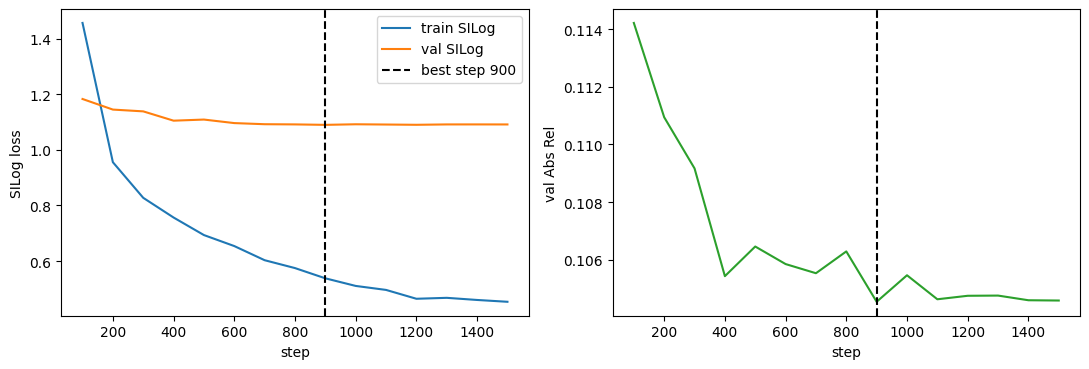

best step 900 of 1500 | train 0.5380 | val 1.0900 | gap 0.5520
final step: train 0.4536 | val 1.0915 | gap 0.6379
test Abs Rel: N=100 0.1093 -> N=300 0.1034 (diff -0.0059)
std of per-image Abs Rel on test: 0.0557 | standard error of the mean: 0.0030
paired diff (300 - 100): mean -0.0059 | SE 0.0016 | images improved: 59.0%


In [ ]:
# YOUR CODE HERE
h = RESULTS[300]["history"]
best = RESULTS[300]["summary"]["best_step"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["step"], h["train_loss"], label="train SILog")
ax[0].plot(h["step"], h["val_loss"], label="val SILog")
ax[0].axvline(best, color="k", ls="--", label=f"best step {best}")
ax[0].set_xlabel("step"); ax[0].set_ylabel("SILog loss"); ax[0].legend()
ax[1].plot(h["step"], h["val_absrel"], color="C2")
ax[1].axvline(best, color="k", ls="--")
ax[1].set_xlabel("step"); ax[1].set_ylabel("val Abs Rel")
plt.tight_layout(); plt.show()

rb = h[h["step"] == best].iloc[0]
print(f"best step {best} of {CONFIG['steps']} | train {rb.train_loss:.4f} | val {rb.val_loss:.4f} | gap {rb.val_loss - rb.train_loss:.4f}")
print(f"final step: train {h.iloc[-1].train_loss:.4f} | val {h.iloc[-1].val_loss:.4f} | gap {h.iloc[-1].val_loss - h.iloc[-1].train_loss:.4f}")

d = RESULTS[300]["summary"]["absrel"] - RESULTS[100]["summary"]["absrel"]
print(f"test Abs Rel: N=100 {RESULTS[100]['summary']['absrel']:.4f} -> N=300 {RESULTS[300]['summary']['absrel']:.4f} (diff {d:+.4f})")

ai = RESULTS[300]["per_image"]["absrel"]
sd = ai.std()
se = sd / np.sqrt(len(ai))
print(f"std of per-image Abs Rel on test: {sd:.4f} | standard error of the mean: {se:.4f}")

# paired view (same test images, aligned by image index) -- a better noise estimate for a difference
a_ = RESULTS[100]["per_image"].set_index("index")["absrel"]
b_ = RESULTS[300]["per_image"].set_index("index")["absrel"].reindex(a_.index)
dd = b_ - a_
print(f"paired diff (300 - 100): mean {dd.mean():+.4f} | SE {dd.std() / np.sqrt(len(dd)):.4f} "
      f"| images improved: {(dd < 0).mean():.1%}")

**Q8.3.** Load the N = 0 model (`build_model().eval()`) and the checkpoint for this size (`load_ckpt(300)`) and call `show_predictions` on `VIS_IDX` with both. Describe what changed between the two columns on these four images: edges, large flat surfaces, near and far regions, and any place where the fine-tuned prediction got *worse*. Use only what you can see on these four images, and say that you are doing so.

*Answer:*

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

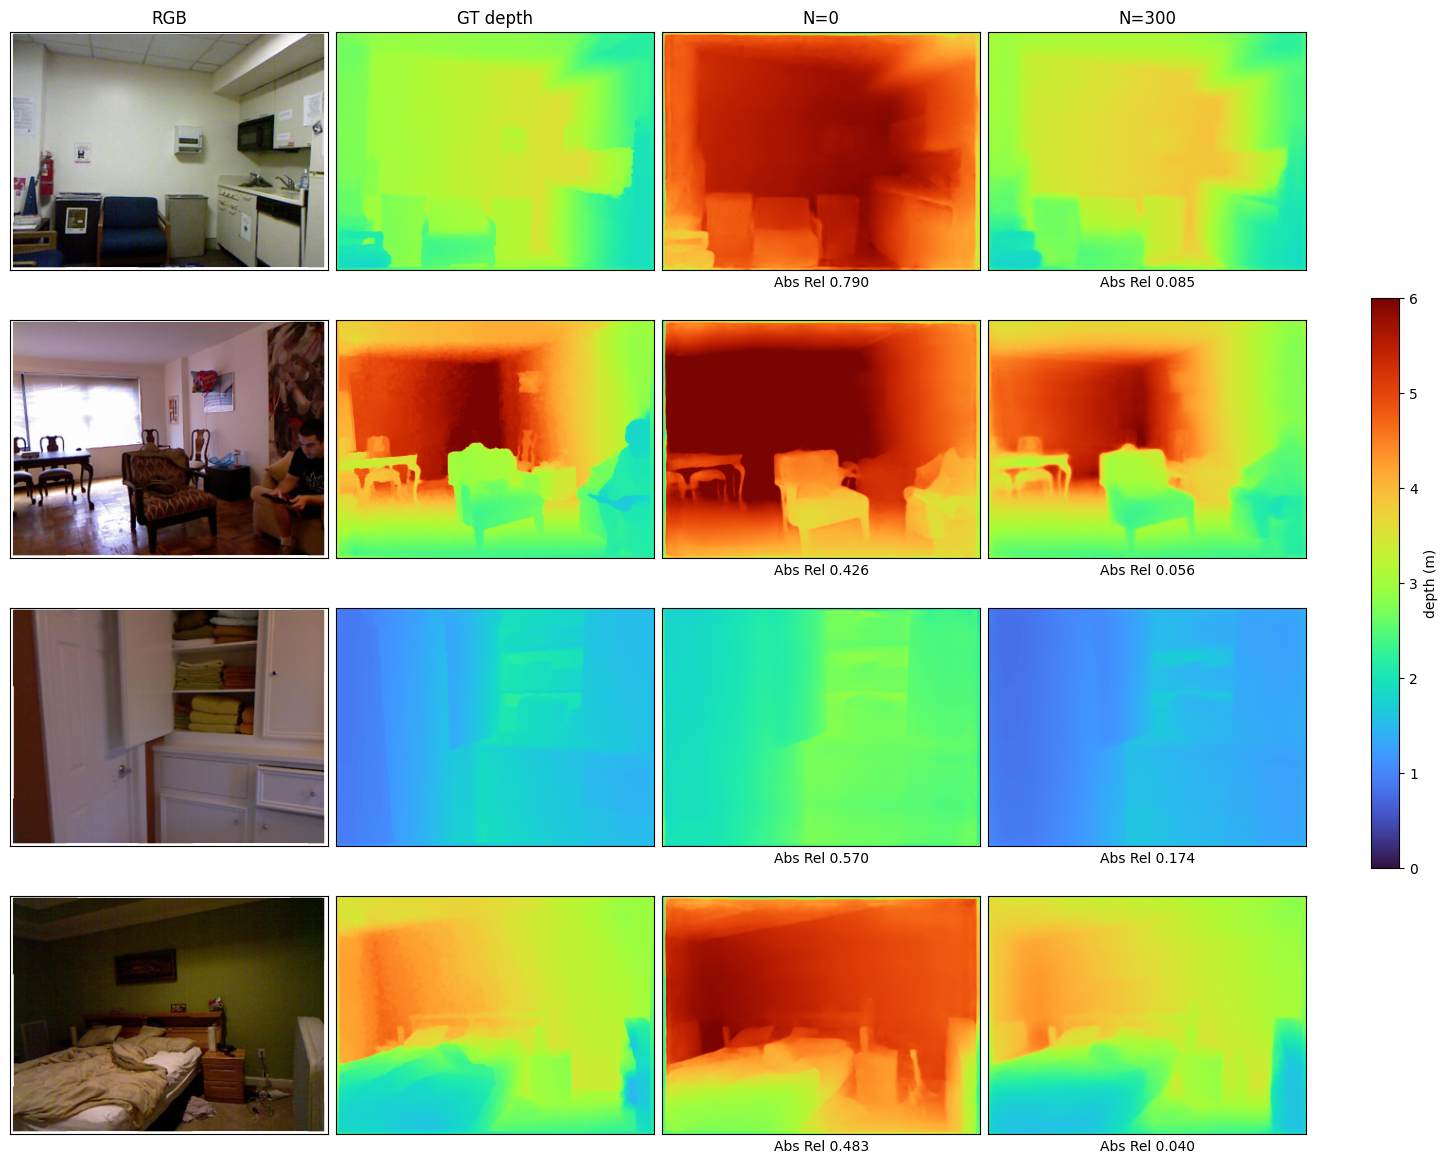

In [ ]:
# YOUR CODE HERE
m0 = build_model().eval()
m300 = load_ckpt(300)
show_predictions({"N=0": m0, "N=300": m300}, VIS_IDX)
del m0, m300; gc.collect(); torch.cuda.empty_cache()

## 9. Fine-tune with 500 labelled images

Same recipe as every other size: `train_one_model` with the shared `CONFIG`, the same step budget, loss, optimiser, validation images and test images. The training set is the first 500 images of the pool, which contain the 300 used in the previous section. Only the number of training images has changed, and the instance masks are given to the model exactly as before.

**Q9.1.** Run `run_experiment(500)`, store the result in `RESULTS[500]`, and print a one-row table with the number of training images, the five test metrics, the best step and the wall-clock minutes. Also print the same metrics for N = 300 from `RESULTS[300]` beneath it, and the change in each.

In [ ]:
# YOUR CODE HERE
RESULTS[500] = run_experiment(500)

def summary_row(n, s):
    return {"N": n, **{k: s[k] for k in METRIC_COLS}, "best_step": s["best_step"], "minutes": round(s["minutes"], 1)}

t = pd.DataFrame([summary_row(500, RESULTS[500]["summary"]),
                  summary_row(300, RESULTS[300]["summary"])]).set_index("N")
change = (t.loc[500, METRIC_COLS] - t.loc[300, METRIC_COLS]).rename("change (500 - 300)")
display(t.round(4))
display(change.to_frame().T.round(4))

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_834/3596533033.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step   100 | train 1.4675 | val 1.1662 | val absrel 0.1134
step   200 | train 0.9887 | val 1.1264 | val absrel 0.1080
step   300 | train 0.8940 | val 1.1680 | val absrel 0.1107
step   400 | train 0.8241 | val 1.1009 | val absrel 0.1067
step   500 | train 0.7433 | val 1.1075 | val absrel 0.1063
step   600 | train 0.7119 | val 1.0645 | val absrel 0.1026
step   700 | train 0.6498 | val 1.0583 | val absrel 0.1014
step   800 | train 0.6348 | val 1.0572 | val absrel 0.1007
step   900 | train 0.5942 | val 1.0502 | val absrel 0.0997
step  1000 | train 0.5750 | val 1.0618 | val absrel 0.1007
step  1100 | train 0.5528 | val 1.0560 | val absrel 0.1009
step  1200 | train 0.5273 | val 1.0507 | val absrel 0.1007
step  1300 | train 0.5260 | val 1.0525 | val absrel 0.1008
step  1400 | train 0.5150 | val 1.0528 | val absrel 0.1006
step  1500 | train 0.5132 | val 1.0528 | val absrel 0.1006


step,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train_loss,█▄▄▃▃▂▂▂▂▁▁▁▁▁▁
val_absrel,█▅▇▅▄▂▂▂▁▂▂▂▂▁▁
val_loss,█▆█▄▄▂▁▁▁▂▁▁▁▁▁
best_step,900
minutes,8.08984
step,1500
test_absrel,0.09963
test_d1,0.90538
test_d2,0.98554
test_d3,0.99533


,absrel,rmse,d1,d2,d3,best_step,minutes
N,,,,,,,
500,0.0996,0.3624,0.9054,0.9855,0.9953,900,8.1
300,0.1034,0.3754,0.9021,0.9844,0.9955,900,8.3


,absrel,rmse,d1,d2,d3
change (500 - 300),-0.0038,-0.013,0.0033,0.0011,-0.0002


**Q9.2.** Plot the training history of this run in two panels: training and validation SILog loss against step, and validation Abs Rel against step, with a vertical line at the best step. Then answer:

- At which step is the validation loss lowest, and is that step before the end of the budget? What does that say about whether 500 images overfit within `CONFIG["steps"]` steps?
- Is there a gap between training and validation loss? What does its size tell you about 500 images?
- How does test Abs Rel at N = 500 compare with N = 300? Give the difference. Would you trust a difference that size from one run on 349 images before Section 11? Say why or why not.

*Answer:*

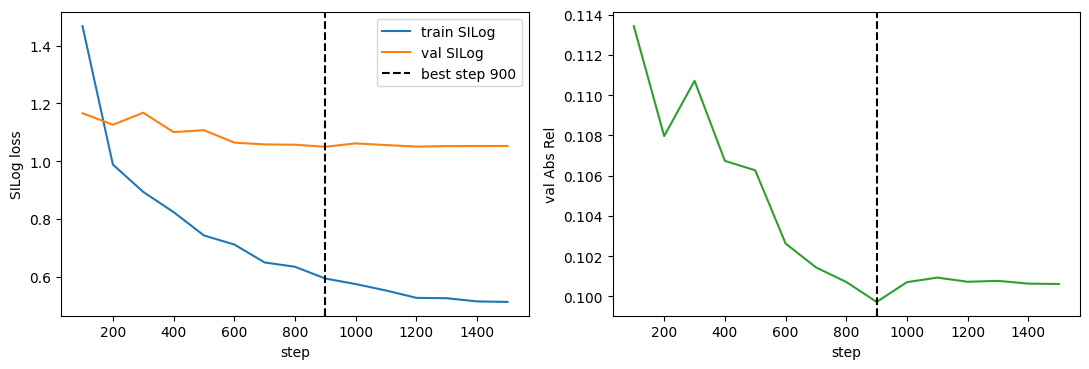

best step 900 of 1500 | train 0.5942 | val 1.0502 | gap 0.4559
final step: train 0.5132 | val 1.0528 | gap 0.5396
test Abs Rel: N=300 0.1034 -> N=500 0.0996 (diff -0.0038)
std of per-image Abs Rel on test: 0.0583 | standard error of the mean: 0.0031
paired diff (500 - 300): mean -0.0038 | SE 0.0011 | images improved: 62.2%


In [ ]:
# YOUR CODE HERE
h = RESULTS[500]["history"]
best = RESULTS[500]["summary"]["best_step"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["step"], h["train_loss"], label="train SILog")
ax[0].plot(h["step"], h["val_loss"], label="val SILog")
ax[0].axvline(best, color="k", ls="--", label=f"best step {best}")
ax[0].set_xlabel("step"); ax[0].set_ylabel("SILog loss"); ax[0].legend()
ax[1].plot(h["step"], h["val_absrel"], color="C2")
ax[1].axvline(best, color="k", ls="--")
ax[1].set_xlabel("step"); ax[1].set_ylabel("val Abs Rel")
plt.tight_layout(); plt.show()

rb = h[h["step"] == best].iloc[0]
print(f"best step {best} of {CONFIG['steps']} | train {rb.train_loss:.4f} | val {rb.val_loss:.4f} | gap {rb.val_loss - rb.train_loss:.4f}")
print(f"final step: train {h.iloc[-1].train_loss:.4f} | val {h.iloc[-1].val_loss:.4f} | gap {h.iloc[-1].val_loss - h.iloc[-1].train_loss:.4f}")

d = RESULTS[500]["summary"]["absrel"] - RESULTS[300]["summary"]["absrel"]
print(f"test Abs Rel: N=300 {RESULTS[300]['summary']['absrel']:.4f} -> N=500 {RESULTS[500]['summary']['absrel']:.4f} (diff {d:+.4f})")

ai = RESULTS[500]["per_image"]["absrel"]
sd = ai.std()
se = sd / np.sqrt(len(ai))
print(f"std of per-image Abs Rel on test: {sd:.4f} | standard error of the mean: {se:.4f}")

# paired view (same test images, aligned by image index)
a_ = RESULTS[300]["per_image"].set_index("index")["absrel"]
b_ = RESULTS[500]["per_image"].set_index("index")["absrel"].reindex(a_.index)
dd = b_ - a_
print(f"paired diff (500 - 300): mean {dd.mean():+.4f} | SE {dd.std() / np.sqrt(len(dd)):.4f} "
      f"| images improved: {(dd < 0).mean():.1%}")

**Q9.3.** Load the N = 0 model (`build_model().eval()`) and the checkpoint for this size (`load_ckpt(500)`) and call `show_predictions` on `VIS_IDX` with both. Describe what changed between the two columns on these four images: edges, large flat surfaces, near and far regions, and any place where the fine-tuned prediction got *worse*. Use only what you can see on these four images, and say that you are doing so.

*Answer:*

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

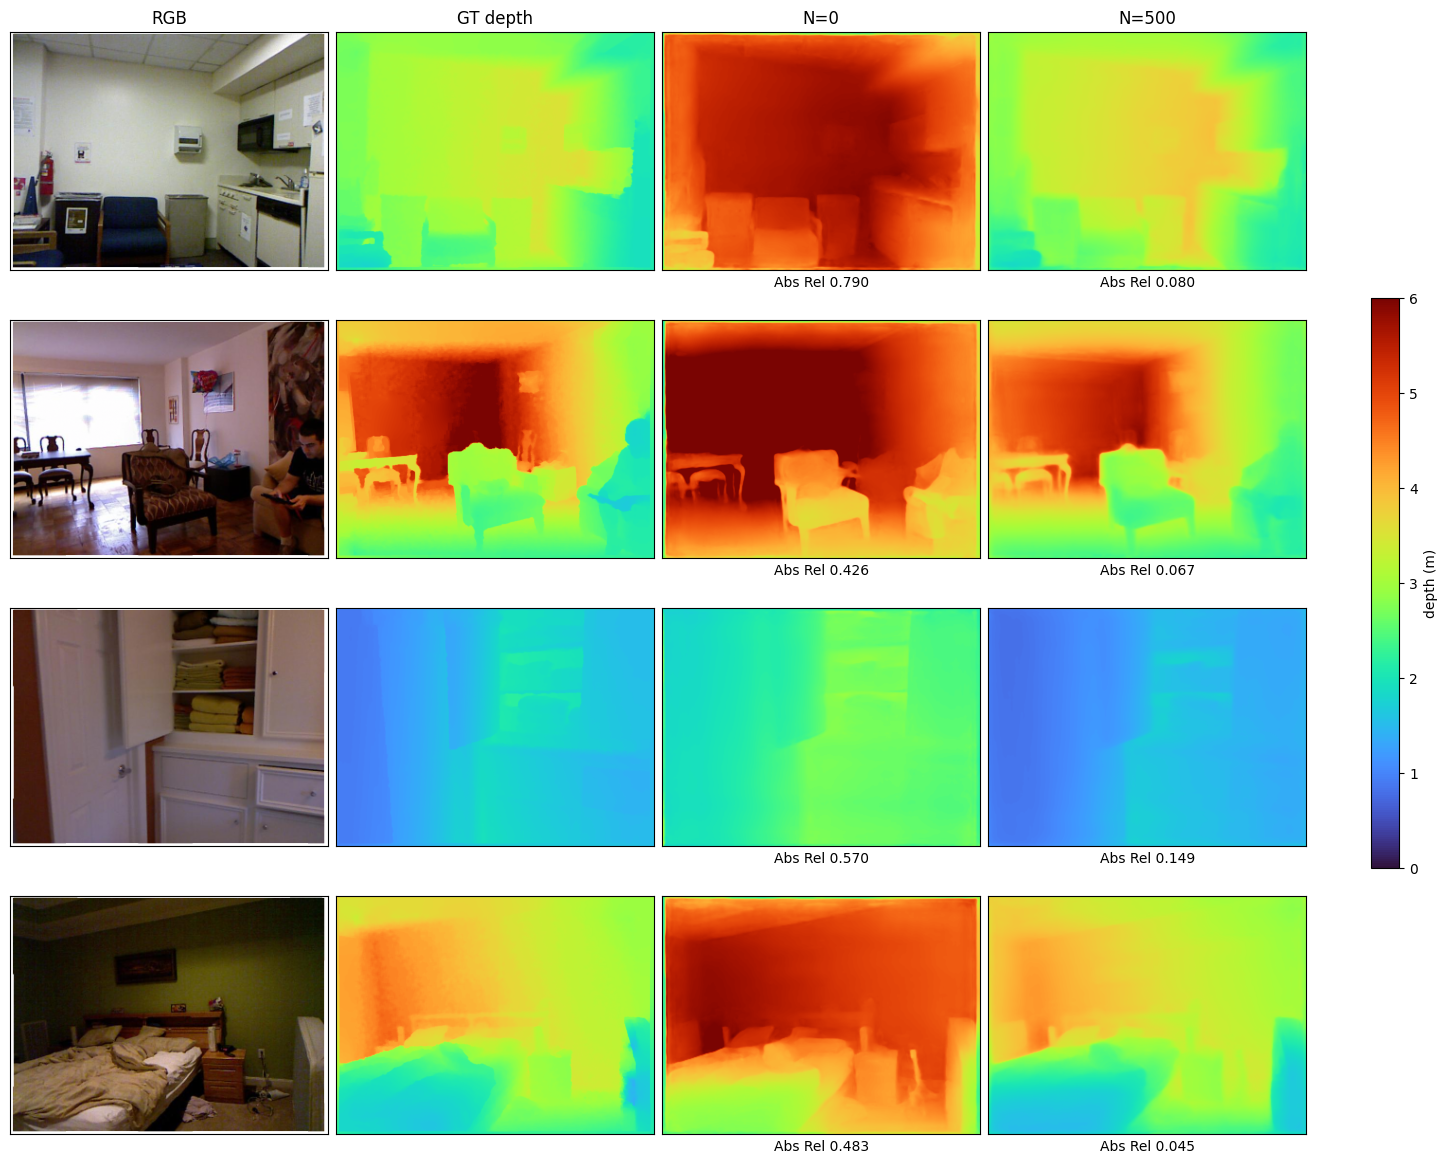

In [ ]:
# YOUR CODE HERE
m0 = build_model().eval()
m500 = load_ckpt(500)
show_predictions({"N=0": m0, "N=500": m500}, VIS_IDX)
del m0, m500; gc.collect(); torch.cuda.empty_cache()

## 10. Fine-tune with 1000 labelled images

Same recipe as every other size: `train_one_model` with the shared `CONFIG`, the same step budget, loss, optimiser, validation images and test images. The training set is the first 1000 images of the pool, which contain the 500 used in the previous section. Only the number of training images has changed, and the instance masks are given to the model exactly as before.

**Q10.1.** Run `run_experiment(1000)`, store the result in `RESULTS[1000]`, and print a one-row table with the number of training images, the five test metrics, the best step and the wall-clock minutes. Also print the same metrics for N = 500 from `RESULTS[500]` beneath it, and the change in each.

In [ ]:
RESULTS[1000] = run_experiment(1000)

def summary_row(n, s):
    return {"N": n, **{k: s[k] for k in METRIC_COLS}, "best_step": s["best_step"], "minutes": round(s["minutes"], 1)}

t = pd.DataFrame([summary_row(1000, RESULTS[1000]["summary"]),
                  summary_row(500, RESULTS[500]["summary"])]).set_index("N")
change = (t.loc[1000, METRIC_COLS] - t.loc[500, METRIC_COLS]).rename("change (1000 - 500)")
display(t.round(4))
display(change.to_frame().T.round(4))

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_834/3596533033.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step   100 | train 1.4513 | val 1.2137 | val absrel 0.1171
step   200 | train 1.1147 | val 1.1472 | val absrel 0.1076
step   300 | train 0.9991 | val 1.1045 | val absrel 0.1039
step   400 | train 0.9186 | val 1.0725 | val absrel 0.1024
step   500 | train 0.8583 | val 1.0689 | val absrel 0.0994
step   600 | train 0.7999 | val 1.0503 | val absrel 0.0996
step   700 | train 0.7791 | val 1.0433 | val absrel 0.0976
step   800 | train 0.7347 | val 1.0187 | val absrel 0.0974
step   900 | train 0.7144 | val 1.0210 | val absrel 0.0964
step  1000 | train 0.6676 | val 1.0199 | val absrel 0.0951
step  1100 | train 0.6580 | val 1.0178 | val absrel 0.0950
step  1200 | train 0.6392 | val 1.0183 | val absrel 0.0947
step  1300 | train 0.6283 | val 1.0192 | val absrel 0.0949
step  1400 | train 0.6117 | val 1.0154 | val absrel 0.0946
step  1500 | train 0.6202 | val 1.0156 | val absrel 0.0946


step,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train_loss,█▅▄▄▃▃▂▂▂▁▁▁▁▁▁
val_absrel,█▅▄▃▃▃▂▂▂▁▁▁▁▁▁
val_loss,█▆▄▃▃▂▂▁▁▁▁▁▁▁▁
best_step,1400
minutes,8.00889
step,1500
test_absrel,0.09383
test_d1,0.92231
test_d2,0.98603
test_d3,0.99617


,absrel,rmse,d1,d2,d3,best_step,minutes
N,,,,,,,
1000,0.0938,0.3469,0.9223,0.9860,0.9962,1400,8.0
500,0.0996,0.3624,0.9054,0.9855,0.9953,900,8.1


,absrel,rmse,d1,d2,d3
change (1000 - 500),-0.0058,-0.0156,0.0169,0.0005,0.0008


**Q10.2.** Plot the training history of this run in two panels: training and validation SILog loss against step, and validation Abs Rel against step, with a vertical line at the best step. Then answer:

- At which step is the validation loss lowest, and is that step before the end of the budget? What does that say about whether 1000 images overfit within `CONFIG["steps"]` steps?
- Is there a gap between training and validation loss? What does its size tell you about 1000 images?
- How does test Abs Rel at N = 1000 compare with N = 500? Give the difference. Would you trust a difference that size from one run on 349 images before Section 11? Say why or why not.

*Answer:*

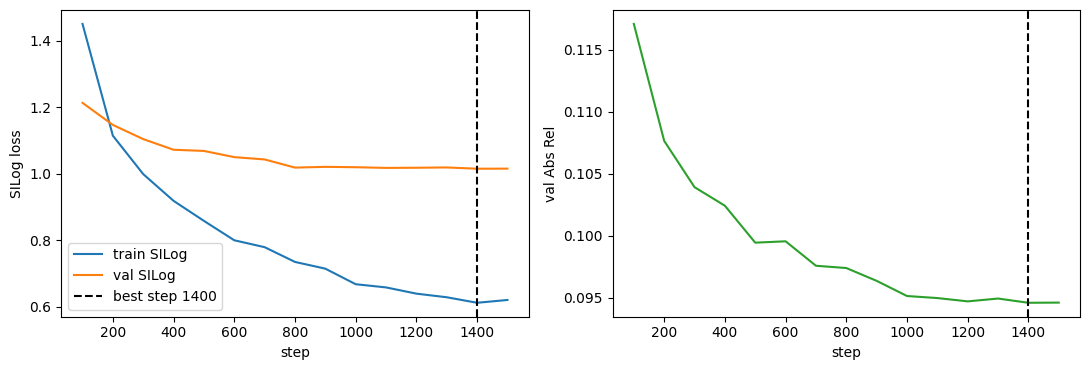

best step 1400 of 1500 | train 0.6117 | val 1.0154 | gap 0.4037
final step: train 0.6202 | val 1.0156 | gap 0.3954
test Abs Rel: N=500 0.0996 -> N=1000 0.0938 (diff -0.0058)
std of per-image Abs Rel on test: 0.0498 | standard error of the mean: 0.0027
paired diff (1000 - 500): mean -0.0058 | SE 0.0014 | images improved: 58.7%


In [ ]:
# YOUR CODE HERE
h = RESULTS[1000]["history"]
best = RESULTS[1000]["summary"]["best_step"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h["step"], h["train_loss"], label="train SILog")
ax[0].plot(h["step"], h["val_loss"], label="val SILog")
ax[0].axvline(best, color="k", ls="--", label=f"best step {best}")
ax[0].set_xlabel("step"); ax[0].set_ylabel("SILog loss"); ax[0].legend()
ax[1].plot(h["step"], h["val_absrel"], color="C2")
ax[1].axvline(best, color="k", ls="--")
ax[1].set_xlabel("step"); ax[1].set_ylabel("val Abs Rel")
plt.tight_layout(); plt.show()

rb = h[h["step"] == best].iloc[0]
print(f"best step {best} of {CONFIG['steps']} | train {rb.train_loss:.4f} | val {rb.val_loss:.4f} | gap {rb.val_loss - rb.train_loss:.4f}")
print(f"final step: train {h.iloc[-1].train_loss:.4f} | val {h.iloc[-1].val_loss:.4f} | gap {h.iloc[-1].val_loss - h.iloc[-1].train_loss:.4f}")

d = RESULTS[1000]["summary"]["absrel"] - RESULTS[500]["summary"]["absrel"]
print(f"test Abs Rel: N=500 {RESULTS[500]['summary']['absrel']:.4f} -> N=1000 {RESULTS[1000]['summary']['absrel']:.4f} (diff {d:+.4f})")

ai = RESULTS[1000]["per_image"]["absrel"]
sd = ai.std()
se = sd / np.sqrt(len(ai))
print(f"std of per-image Abs Rel on test: {sd:.4f} | standard error of the mean: {se:.4f}")

# paired view (same test images, aligned by image index)
a_ = RESULTS[500]["per_image"].set_index("index")["absrel"]
b_ = RESULTS[1000]["per_image"].set_index("index")["absrel"].reindex(a_.index)
dd = b_ - a_
print(f"paired diff (1000 - 500): mean {dd.mean():+.4f} | SE {dd.std() / np.sqrt(len(dd)):.4f} "
      f"| images improved: {(dd < 0).mean():.1%}")

**Q10.3.** Load the N = 0 model (`build_model().eval()`) and the checkpoint for this size (`load_ckpt(1000)`) and call `show_predictions` on `VIS_IDX` with both. Describe what changed between the two columns on these four images: edges, large flat surfaces, near and far regions, and any place where the fine-tuned prediction got *worse*. Use only what you can see on these four images, and say that you are doing so.

*Answer:*

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

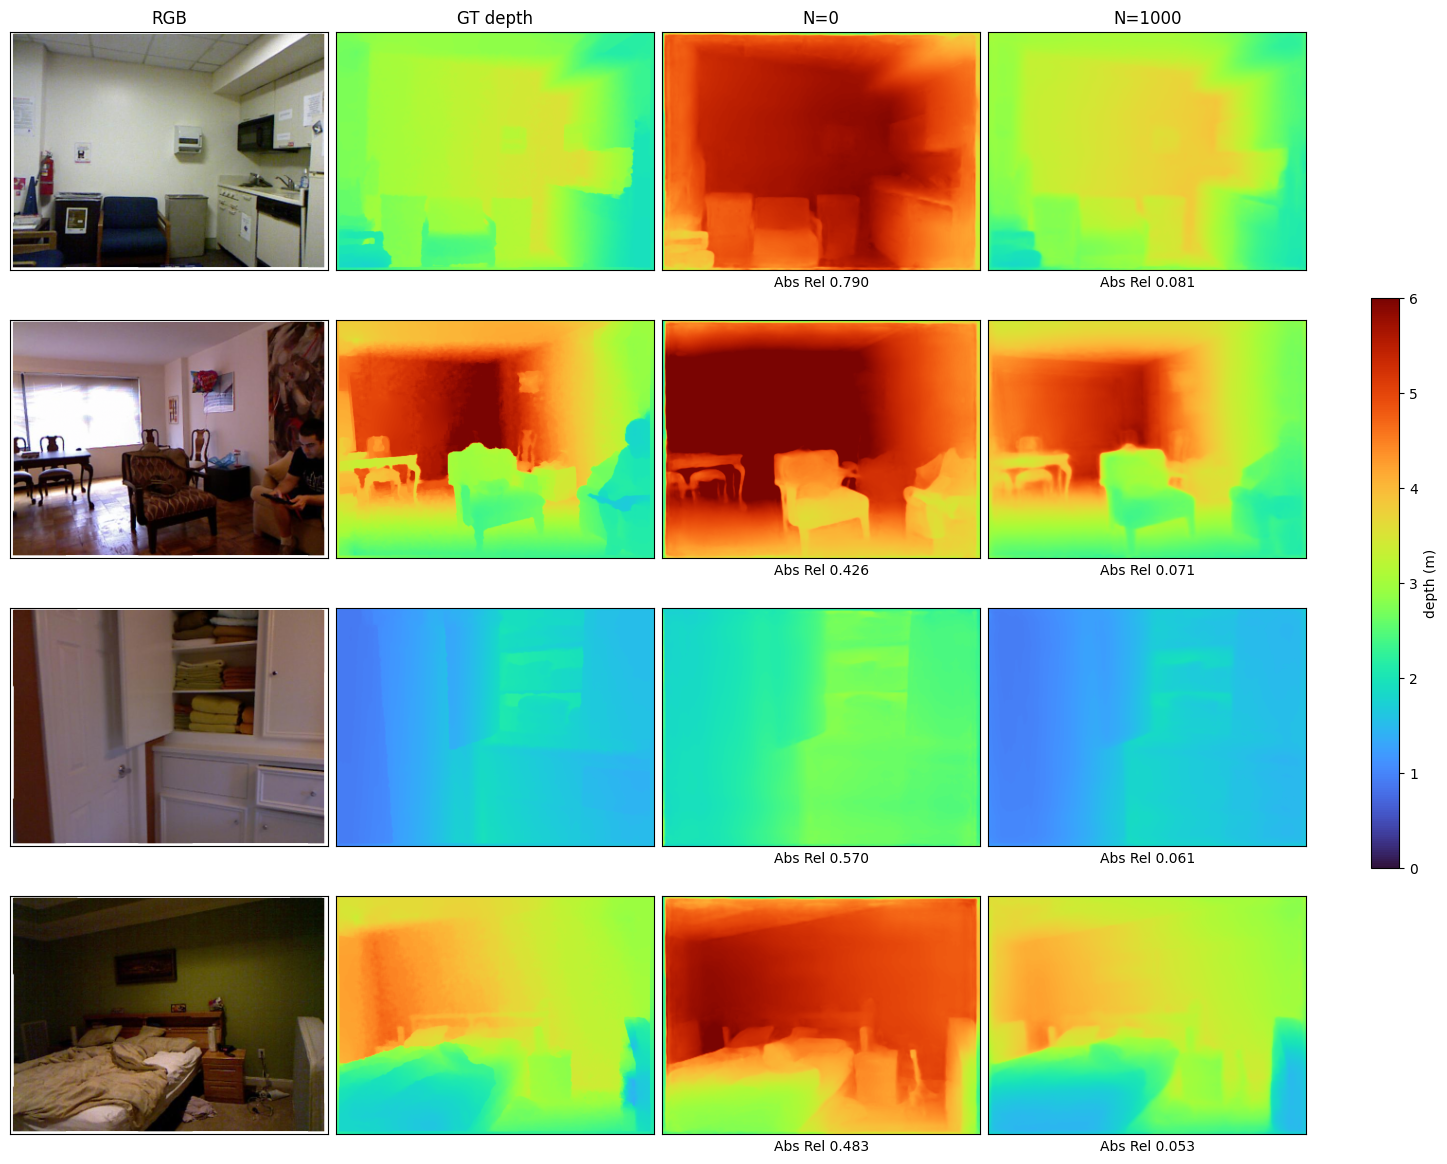

In [ ]:
# YOUR CODE HERE
m0 = build_model().eval()
m1000 = load_ckpt(1000)
show_predictions({"N=0": m0, "N=1000": m1000}, VIS_IDX)
del m0, m1000; gc.collect(); torch.cuda.empty_cache()

## 11. Compare the fine-tuned models

Five models now exist: N = 0, 100, 300, 500, 1000. The central result of the project is how the five metrics change across them. This section builds that table and the learning curve, and asks how much of what you see you are entitled to believe: 349 test images and one run per size give a noisy answer, and a learning curve without an uncertainty estimate is a drawing rather than a result.

**Q11.1.** Build `results_df`, one row per $N \in \{0, 100, 300, 500, 1000\}$ with columns `n_train`, `absrel`, `rmse`, `d1`, `d2`, `d3`, `best_step`, `minutes`, from `RESULTS`. Print it, save it to `f"{WORK}/results.csv"`, and report the relative change in Abs Rel from N = 0 to N = 1000 as a percentage.

In [ ]:
# YOUR CODE HERE
NS = [0, 100, 300, 500, 1000]

def results_row(n):
    s = RESULTS[n]["summary"]
    return {"n_train": n,   # N is the requested training-set size (0 = no fine-tuning)
            **{k: s[k] for k in METRIC_COLS},
            "best_step": s["best_step"],
            "minutes": s["minutes"]}

results_df = pd.DataFrame([results_row(n) for n in NS])
results_df = results_df[["n_train", "absrel", "rmse", "d1", "d2", "d3", "best_step", "minutes"]]

print(results_df.round({"absrel": 4, "rmse": 4, "d1": 4, "d2": 4, "d3": 4, "minutes": 1}).to_string(index=False))

results_df.to_csv(f"{WORK}/results.csv", index=False)

a0 = results_df.loc[results_df["n_train"] == 0, "absrel"].item()
a1 = results_df.loc[results_df["n_train"] == 1000, "absrel"].item()
rel_change = 100 * (a1 - a0) / a0
print(f"\nAbs Rel, N=0 -> N=1000: {a0:.4f} -> {a1:.4f}  ({rel_change:+.1f}% relative change)")

 n_train  absrel   rmse     d1     d2     d3  best_step  minutes
       0  0.6055 1.5568 0.0883 0.5081 0.8861          0      0.0
     100  0.1093 0.3916 0.8906 0.9831 0.9958        300      9.2
     300  0.1034 0.3754 0.9021 0.9844 0.9955        900      8.3
     500  0.0996 0.3624 0.9054 0.9855 0.9953        900      8.1
    1000  0.0938 0.3469 0.9223 0.9860 0.9962       1400      8.0

Abs Rel, N=0 -> N=1000: 0.6055 -> 0.0938  (-84.5% relative change)


**Q11.2.** Implement `bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=0)` returning the mean and the percentile confidence interval of the mean, resampling **images** with replacement from the per-image values. Then draw the learning curve: one panel per metric (five panels), the metric against $N$ with the confidence interval as error bars. Use equally spaced positions on the x-axis with the labels 0, 100, 300, 500, 1000 (a log axis cannot place 0). Say in a caption which quantity the error bars describe, and what they do **not** capture.

metric                    absrel                     rmse                       d1                       d2                       d3
n_train                                                                                                                             
0        0.6055 [0.5841, 0.6263]  1.5568 [1.4849, 1.6339]  0.0883 [0.0737, 0.1028]  0.5081 [0.4762, 0.5401]  0.8861 [0.8691, 0.9031]
100      0.1093 [0.1031, 0.1158]  0.3916 [0.3648, 0.4203]  0.8906 [0.8742, 0.9059]  0.9831 [0.9785, 0.9870]  0.9958 [0.9934, 0.9975]
300      0.1034 [0.0979, 0.1092]  0.3754 [0.3502, 0.4025]  0.9021 [0.8881, 0.9154]  0.9844 [0.9802, 0.9880]  0.9955 [0.9931, 0.9974]
500      0.0996 [0.0936, 0.1056]  0.3624 [0.3359, 0.3897]  0.9054 [0.8903, 0.9199]  0.9855 [0.9809, 0.9892]  0.9953 [0.9925, 0.9975]
1000     0.0938 [0.0888, 0.0989]  0.3469 [0.3218, 0.3731]  0.9223 [0.9109, 0.9332]  0.9860 [0.9817, 0.9895]  0.9962 [0.9938, 0.9979]


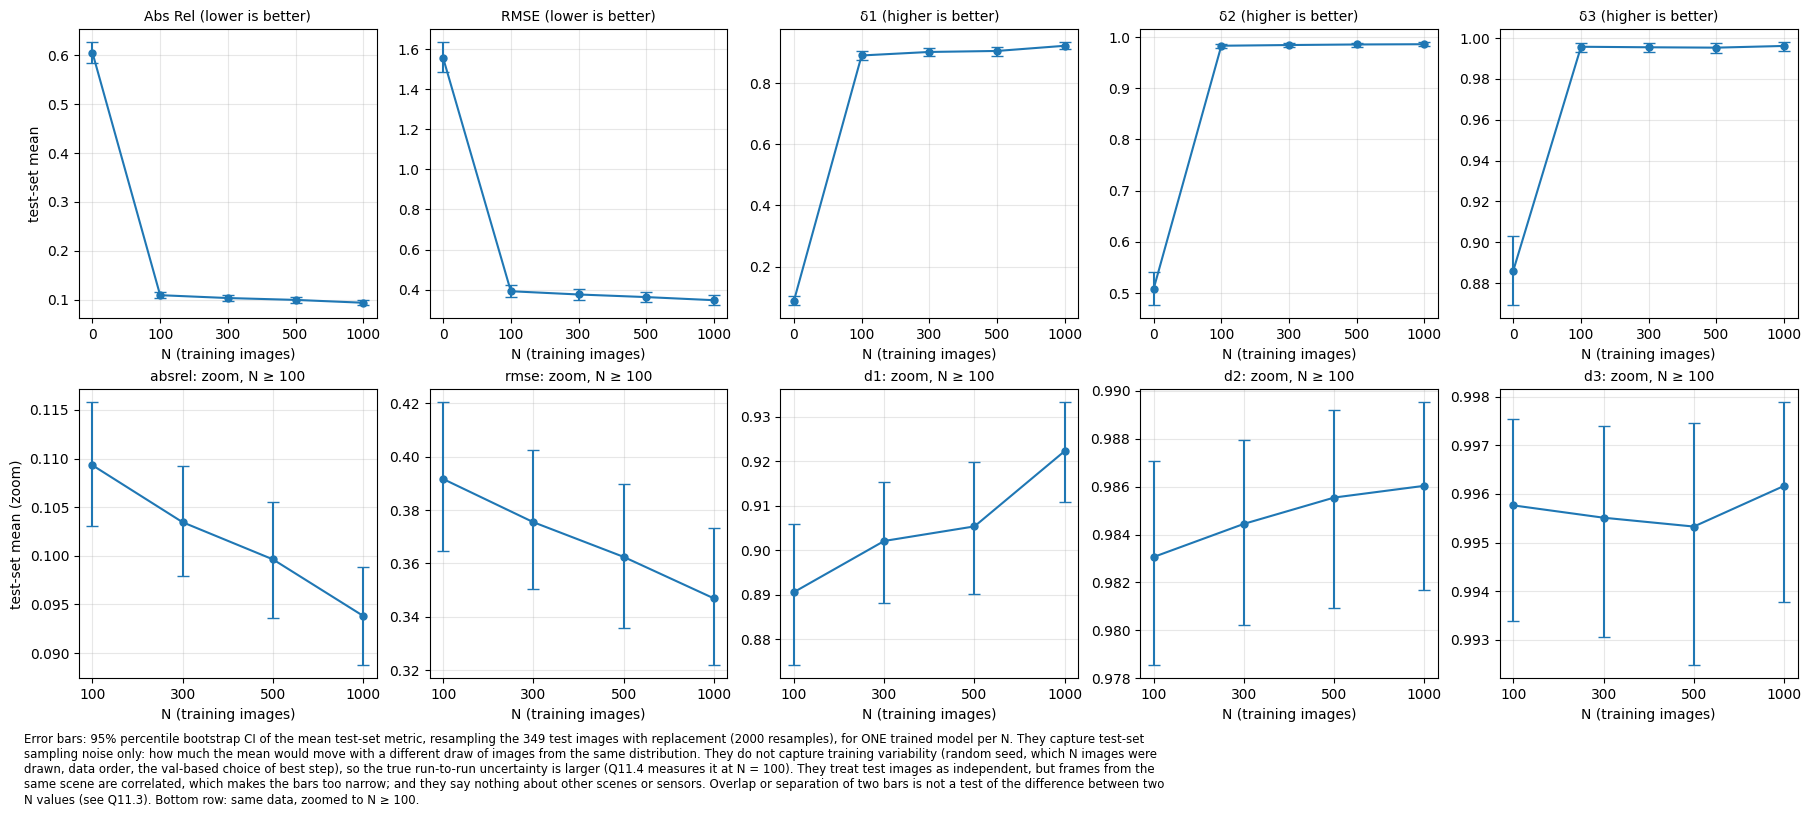

In [ ]:
def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=0):
    # YOUR CODE HERE
    ...

    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(v), size=(n_boot, len(v)))   # n_boot resamples of the images
    boot_means = v[idx].mean(axis=1)
    lo, hi = np.percentile(boot_means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(v.mean()), float(lo), float(hi)

# YOUR CODE HERE: the five-panel learning curve
import textwrap
N_BOOT = 2000
rows = []
for n in NS:
    pi = RESULTS[n]["per_image"]
    for m in METRIC_COLS:
        mean, lo, hi = bootstrap_ci(pi[m].values, n_boot=N_BOOT)
        rows.append({"n_train": n, "metric": m, "mean": mean, "lo": lo, "hi": hi,
                     "n_images": int(pi[m].notna().sum())})
ci_df = pd.DataFrame(rows)

# sanity: bootstrap mean should equal the summary mean used in results_df
for n in NS:
    for m in METRIC_COLS:
        a = ci_df.query("n_train == @n and metric == @m")["mean"].item()
        b = RESULTS[n]["summary"][m]
        if not np.isclose(a, b, rtol=1e-6):
            print(f"WARNING: N={n} {m}: per-image mean {a:.5f} != summary {b:.5f}")
ci_txt = ci_df.assign(txt=ci_df.apply(lambda r: f"{r['mean']:.4f} [{r['lo']:.4f}, {r['hi']:.4f}]", axis=1))
print(ci_txt.pivot(index="n_train", columns="metric", values="txt")[METRIC_COLS].to_string())
LABELS = {"absrel": "Abs Rel (lower is better)", "rmse": "RMSE (lower is better)",
          "d1": "δ1 (higher is better)", "d2": "δ2 (higher is better)",
          "d3": "δ3 (higher is better)"}
x_all = np.arange(len(NS))                     # equally spaced positions; 0 cannot sit on a log axis
fig, axes = plt.subplots(2, 5, figsize=(18, 7.2), constrained_layout=True)

for col, m in enumerate(METRIC_COLS):
    d = ci_df[ci_df["metric"] == m].set_index("n_train").loc[NS]
    for row, sl in enumerate([slice(0, None), slice(1, None)]):
        ax = axes[row, col]
        xs = x_all[sl]
        ax.errorbar(xs, d["mean"].values[sl],
                    yerr=[(d["mean"] - d["lo"]).values[sl], (d["hi"] - d["mean"]).values[sl]],
                    fmt="o-", capsize=4, lw=1.5, ms=5)
        ax.set_xticks(xs)
        ax.set_xticklabels([str(n) for n in NS][sl])
        ax.set_xlabel("N (training images)")
        ax.grid(alpha=0.3)
        ax.set_title(LABELS[m] if row == 0 else f"{m}: zoom, N ≥ 100", fontsize=10)
axes[0, 0].set_ylabel("test-set mean")
axes[1, 0].set_ylabel("test-set mean (zoom)")

caption = (
    f"Error bars: 95% percentile bootstrap CI of the mean test-set metric, resampling the "
    f"{ci_df['n_images'].iloc[0]} test images with replacement ({N_BOOT} resamples), for ONE trained model per N. "
    "They capture test-set sampling noise only: how much the mean would move with a different draw of "
    "images from the same distribution. They do not capture training variability (random seed, which N images "
    "were drawn, data order, the val-based choice of best step), so the true run-to-run uncertainty is larger "
    "(Q11.4 measures it at N = 100). They treat test images as independent, but frames from the same scene are "
    "correlated, which makes the bars too narrow; and they say nothing about other scenes or sensors. "
    "Overlap or separation of two bars is not a test of the difference between two N values (see Q11.3). "
    "Bottom row: same data, zoomed to N ≥ 100."
)
fig.text(0.01, -0.01, textwrap.fill(caption, width=190), ha="left", va="top", fontsize=8.5)
fig.savefig(f"{WORK}/learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# print(ci_df.round(4).to_string(index=False))

**Q11.3.** The five models are scored on the **same** test images, so differences between two models should be tested **paired**, image by image, which removes the variation between easy and hard images. Write `paired_bootstrap(a, b, n_boot=2000, alpha=0.05, seed=0)` for two aligned per-image arrays, returning the mean of `b - a`, its percentile interval, and the fraction of bootstrap resamples in which `b - a` is below zero. Make sure the rows of the two `per_image` tables are aligned by image index before you subtract. Apply it to Abs Rel for each consecutive pair $(0 \to 100,\ 100 \to 300,\ 300 \to 500,\ 500 \to 1000)$ and print a table. For which steps is the improvement distinguishable from noise, and for which is it not?

In [ ]:
def paired_bootstrap(a, b, n_boot=2000, alpha=0.05, seed=0):
    # YOUR CODE HERE
    ...
    """Paired bootstrap of the mean of (b - a) over images.
    a, b: aligned per-image arrays (same image at the same position).
    Returns (mean diff, lo, hi, frac of resamples with b - a < 0)."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    assert a.shape == b.shape, "a and b must be aligned"
    d = b - a
    d = d[~np.isnan(d)]                        # drop images missing in either model
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))   # same images resampled for both models
    boot = d[idx].mean(axis=1)
    lo, hi = np.percentile(boot, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(d.mean()), float(lo), float(hi), float((boot < 0).mean())
# YOUR CODE HERE: the four consecutive comparisons
def align_per_image(pa, pb, metric):
    """Align on the dataset image id (the `index` COLUMN), not the 0..348 row index."""
    sa, sb = pa.set_index("index")[metric], pb.set_index("index")[metric]
    assert sa.index.is_unique and sb.index.is_unique, "an image appears twice in a per_image table"
    assert set(sa.index) == set(sb.index), "the two models were scored on different images"
    ids = np.sort(sa.index.values)
    return ids, sa.loc[ids].values, sb.loc[ids].values

def aligned_metric(n_a, n_b, metric):
    _, a, b = align_per_image(RESULTS[n_a]["per_image"], RESULTS[n_b]["per_image"], metric)
    return a, b


def cluster_paired_bootstrap(d, groups, n_boot=2000, alpha=0.05, seed=0):
    """Resamples whole scenes instead of single images (frames of one scene are not independent)."""
    d = np.asarray(d, dtype=float); groups = np.asarray(groups)
    ok = ~np.isnan(d); d, groups = d[ok], groups[ok]
    labels, inv = np.unique(groups, return_inverse=True)
    G = len(labels)
    S = np.bincount(inv, weights=d, minlength=G)
    C = np.bincount(inv, minlength=G).astype(float)
    rng = np.random.default_rng(seed)
    pick = rng.integers(0, G, size=(n_boot, G))
    boot = S[pick].sum(axis=1) / C[pick].sum(axis=1)
    lo, hi = np.percentile(boot, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(d.mean()), float(lo), float(hi)


pairs = [(0, 100), (100, 300), (300, 500), (500, 1000)]
alpha_bonf = 0.05 / len(pairs)                 # four comparisons

rows = []
for n_a, n_b in pairs:
    ids, a, b = align_per_image(RESULTS[n_a]["per_image"], RESULTS[n_b]["per_image"], "absrel")
    mean_d, lo, hi, frac = paired_bootstrap(a, b)
    _, lo_b, hi_b, _ = paired_bootstrap(a, b, alpha=alpha_bonf)
    _, c_lo, c_hi = cluster_paired_bootstrap(b - a, np.asarray(scene_group)[ids])
    rows.append({"step": f"{n_a}->{n_b}",
                 "mean_a": np.nanmean(a), "mean_b": np.nanmean(b),
                 "mean_diff (b-a)": mean_d, "ci_lo": lo, "ci_hi": hi,
                 "frac_below_0": frac,
                 "rel_change_%": 100 * mean_d / np.nanmean(a),
                 "%imgs improved": 100 * np.mean((b - a) < 0),
                 "95% CI excludes 0": (hi < 0) or (lo > 0),
                 "Bonferroni CI excludes 0": (hi_b < 0) or (lo_b > 0),
                 "scene-cluster lo": c_lo, "scene-cluster hi": c_hi,
                 "scene-cluster excludes 0": (c_hi < 0) or (c_lo > 0)})


paired_df = pd.DataFrame(rows)
print(f"test images: {len(ids)} from {len(np.unique(np.asarray(scene_group)[ids]))} scene groups")
print(paired_df.round(4).iloc[:, :9].to_string(index=False))
print()
print(paired_df.round(4)[["step", "95% CI excludes 0", "Bonferroni CI excludes 0",
                          "scene-cluster lo", "scene-cluster hi", "scene-cluster excludes 0"]].to_string(index=False))

test images: 349 from 117 scene groups
     step  mean_a  mean_b  mean_diff (b-a)   ci_lo   ci_hi  frac_below_0  rel_change_%  %imgs improved
   0->100  0.6055  0.1093          -0.4962 -0.5158 -0.4765         1.000      -81.9492        100.0000
 100->300  0.1093  0.1034          -0.0059 -0.0090 -0.0026         1.000       -5.3580         59.0258
 300->500  0.1034  0.0996          -0.0038 -0.0061 -0.0018         0.999       -3.6873         62.1777
500->1000  0.0996  0.0938          -0.0058 -0.0086 -0.0032         1.000       -5.8288         58.7393

     step  95% CI excludes 0  Bonferroni CI excludes 0  scene-cluster lo  scene-cluster hi  scene-cluster excludes 0
   0->100               True                      True           -0.5237           -0.4683                      True
 100->300               True                      True           -0.0091           -0.0028                      True
 300->500               True                      True           -0.0062           -0.0013    

**Q11.4.** One run per size does not tell you how much the answer depends on *which* images you drew and on the random initialisation of the head. Run two more N = 100 experiments that differ from the original in both:

```python
RESULTS_SEED = {
    (100, 1): run_experiment(100, subset_seed=1, seed=1),
    (100, 2): run_experiment(100, subset_seed=2, seed=2),
}
```

Report the three test Abs Rel values (the nested-first-100 run and these two) and their spread. Compare the spread with the gap between N = 100 and N = 300 from Q11.3: if the spread is comparable to the gap, the gap is not telling you what you think. Say what you would have concluded about the value of going from 100 to 300 images if you had run only the nested seed.

In [ ]:
# YOUR CODE HERE
RESULTS_SEED = {
    (100, 1): run_experiment(100, subset_seed=1, seed=1),
    (100, 2): run_experiment(100, subset_seed=2, seed=2),
}
# the three N=100 runs: nested first-100 (seed 0) and the two random subsets
runs = {
    "nested first-100 (s0)":    RESULTS[100],
    "random subset (sub1, s1)": RESULTS_SEED[(100, 1)],
    "random subset (sub2, s2)": RESULTS_SEED[(100, 2)],
}
runs100 = {k: r["summary"]["absrel"] for k, r in runs.items()}   # scalars
# rows = []
# a100 = RESULTS[100]["summary"]["absrel"]
# a300 = RESULTS[300]["summary"]["absrel"]
# for name, pi in runs100.items():
#     ids, a, b = align_per_image(pi, RESULTS[300]["per_image"], "absrel")
#     md, lo, hi, frac = paired_bootstrap(a, b)
#     rows.append({"N=100 run": name, "N=100 absrel": a.mean(), "N=300 absrel": b.mean(),
#                  "diff (300-100run)": md, "ci_lo": lo, "ci_hi": hi, "frac_below_0": frac})
# print(pd.DataFrame(rows).round(4).to_string(index=False))
# order = sorted(runs100, key=runs100.get)
# print("\nranking of the three N=100 runs, best first:", order)
# print(f"nested run is the best of the three: {order[0].startswith('nested')} "
#       f"-> the nested 100->300 gap ({a100 - a300:.4f}) is the SMALLEST of the three possible gaps")'

vals = np.array(list(runs100.values()))
for k, v in runs100.items():
    print(f"{k:28s} Abs Rel = {v:.4f}")

spread_range = vals.max() - vals.min()
spread_std = vals.std(ddof=1)
print(f"\nmean = {vals.mean():.4f}   std (ddof=1) = {spread_std:.4f}   range = {spread_range:.4f}"
      f"   range/mean = {100 * spread_range / vals.mean():.1f}%")

a100 = RESULTS[100]["summary"]["absrel"]
a300 = RESULTS[300]["summary"]["absrel"]
gap = a100 - a300
print(f"\nN=100 (nested) = {a100:.4f}   N=300 = {a300:.4f}   gap = {gap:.4f} "
      f"({100 * gap / a100:.1f}% of the N=100 value)")
print(f"range / gap = {spread_range / gap:.2f}   2*std / gap = {2 * spread_std / gap:.2f}")
print(f"N=300 below the best of the three N=100 runs? {a300 < vals.min()}  "
      f"(margin {vals.min() - a300:+.4f})")
print(f"gap if the mean of the three runs were used: {vals.mean() - a300:.4f}")

if spread_range >= gap:
    print("\nVERDICT: spread >= gap -> the 100->300 gap is not distinguishable from seed/subset noise.")
elif spread_range >= 0.5 * gap:
    print("\nVERDICT: spread is a large fraction of the gap -> the gap is real in sign but its size is poorly determined.")
else:
    print("\nVERDICT: spread is small relative to the gap -> the 100->300 gain is robust to seed/subset.")

# paired comparison of N=300 against EACH N=100 run (test-image noise only)
rows = []
for name, r in runs.items():
    ids, a, b = align_per_image(r["per_image"], RESULTS[300]["per_image"], "absrel")
    md, lo, hi, frac = paired_bootstrap(a, b)
    rows.append({"N=100 run": name, "N=100 absrel": a.mean(), "N=300 absrel": b.mean(),
                 "diff (300-100run)": md, "ci_lo": lo, "ci_hi": hi, "frac_below_0": frac})
print("\n" + pd.DataFrame(rows).round(4).to_string(index=False))

order = sorted(runs100, key=runs100.get)
print("\nranking of the three N=100 runs, best first:", order)
print(f"nested run is the best of the three: {order[0].startswith('nested')} "
      f"-> the nested 100->300 gap ({gap:.4f}) is the SMALLEST of the three possible gaps")

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_834/3596533033.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step   100 | train 1.2811 | val 1.2271 | val absrel 0.1210
step   200 | train 0.7363 | val 1.1925 | val absrel 0.1165
step   300 | train 0.6247 | val 1.1766 | val absrel 0.1180
step   400 | train 0.5457 | val 1.1928 | val absrel 0.1183
step   500 | train 0.4926 | val 1.1872 | val absrel 0.1197
step   600 | train 0.4469 | val 1.1945 | val absrel 0.1207
step   700 | train 0.4180 | val 1.1813 | val absrel 0.1168
step   800 | train 0.3936 | val 1.1897 | val absrel 0.1180
step   900 | train 0.3676 | val 1.1936 | val absrel 0.1188
step  1000 | train 0.3471 | val 1.1918 | val absrel 0.1179
step  1100 | train 0.3293 | val 1.1974 | val absrel 0.1186
step  1200 | train 0.3210 | val 1.1977 | val absrel 0.1182
step  1300 | train 0.3135 | val 1.1978 | val absrel 0.1182
step  1400 | train 0.3055 | val 1.1985 | val absrel 0.1182
step  1500 | train 0.3062 | val 1.1985 | val absrel 0.1182


step,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train_loss,█▄▃▃▂▂▂▂▁▁▁▁▁▁▁
val_absrel,█▁▃▄▆█▁▃▅▃▄▄▄▄▄
val_loss,█▃▁▃▂▃▂▃▃▃▄▄▄▄▄
best_step,300
minutes,8.97597
step,1500
test_absrel,0.11175
test_d1,0.88171
test_d2,0.98203
test_d3,0.99602


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

/tmp/ipykernel_834/3596533033.py:69: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step   100 | train 1.2798 | val 1.2128 | val absrel 0.1271
step   200 | train 0.7380 | val 1.2068 | val absrel 0.1268
step   300 | train 0.6263 | val 1.1891 | val absrel 0.1236
step   400 | train 0.5523 | val 1.1804 | val absrel 0.1237
step   500 | train 0.5102 | val 1.1781 | val absrel 0.1238
step   600 | train 0.4669 | val 1.1809 | val absrel 0.1259
step   700 | train 0.4301 | val 1.1758 | val absrel 0.1246
step   800 | train 0.3979 | val 1.1741 | val absrel 0.1241
step   900 | train 0.3749 | val 1.1870 | val absrel 0.1256
step  1000 | train 0.3557 | val 1.1837 | val absrel 0.1252
step  1100 | train 0.3382 | val 1.1862 | val absrel 0.1255
step  1200 | train 0.3267 | val 1.1892 | val absrel 0.1258
step  1300 | train 0.3178 | val 1.1930 | val absrel 0.1263
step  1400 | train 0.3144 | val 1.1940 | val absrel 0.1262
step  1500 | train 0.3117 | val 1.1943 | val absrel 0.1263


step,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train_loss,█▄▃▃▂▂▂▂▁▁▁▁▁▁▁
val_absrel,█▇▁▁▁▆▃▂▅▄▅▅▆▆▆
val_loss,█▇▄▂▂▂▁▁▃▃▃▄▄▅▅
best_step,800
minutes,9.0385
step,1500
test_absrel,0.11444
test_d1,0.8764
test_d2,0.98051
test_d3,0.99502


nested first-100 (s0)        Abs Rel = 0.1093
random subset (sub1, s1)     Abs Rel = 0.1117
random subset (sub2, s2)     Abs Rel = 0.1144

mean = 0.1118   std (ddof=1) = 0.0026   range = 0.0051   range/mean = 4.6%

N=100 (nested) = 0.1093   N=300 = 0.1034   gap = 0.0059 (5.4% of the N=100 value)
range / gap = 0.88   2*std / gap = 0.88
N=300 below the best of the three N=100 runs? True  (margin +0.0059)
gap if the mean of the three runs were used: 0.0084

VERDICT: spread is a large fraction of the gap -> the gap is real in sign but its size is poorly determined.

               N=100 run  N=100 absrel  N=300 absrel  diff (300-100run)   ci_lo   ci_hi  frac_below_0
   nested first-100 (s0)        0.1093        0.1034            -0.0059 -0.0090 -0.0026           1.0
random subset (sub1, s1)        0.1117        0.1034            -0.0083 -0.0120 -0.0046           1.0
random subset (sub2, s2)        0.1144        0.1034            -0.0110 -0.0155 -0.0067           1.0

ranking of the three N

*Answer:*

**Q11.5.** Learning curves in machine learning are often roughly straight on a log-log plot: error $\approx a\,N^{-b}$. Fit a straight line to $\log(\text{Abs Rel})$ against $\log N$ for the four fine-tuned sizes (not N = 0, which has no logarithm) with `np.polyfit`, and report the slope $-b$ and the fit's residuals. Draw the four points and the fitted line on log-log axes.

Then answer the project's headline question in your own words: **how much labelled data is needed to obtain useful improvements over the pretrained model?** Define "useful" yourself (for example, recovering half of the N = 0 to N = 1000 gap in Abs Rel), state your definition, and read the answer off your results with its uncertainty. Say what a four-point fit can and cannot support, and refuse to extrapolate beyond N = 1000 beyond one cautious sentence. Compare the outcome with the prediction you wrote down in Q5.6.

log(AbsRel) = -0.0655 * log(N) + -1.9050
slope = -b = -0.0655  (b = 0.0655, SE ~ 0.0068, 2 d.o.f.)
a = 0.1488   R^2 = 0.9791
doubling N multiplies Abs Rel by about 0.956  (-4.4%)
   N  absrel  fitted  resid_log  resid_%
 100  0.1093  0.1101    -0.0070  -0.6929
 300  0.1034  0.1024     0.0099   0.9991
 500  0.0996  0.0991     0.0058   0.5849
1000  0.0938  0.0947    -0.0088  -0.8781
residual std (log, ddof=2) = 0.0114

slope with the mean of the 3 N=100 runs : -0.0756  (doubling -> -5.1%)
slope with all 6 points (3 at N=100)     : -0.0747 +- 0.0075  (4 d.o.f.)

N=0 -> N=1000 gap in Abs Rel: 0.5117; half of it is reached at Abs Rel = 0.3497
   N  absrel  share of gap recovered %  above N=1000 by %
 100   0.109                    96.975             16.497
 300   0.103                    98.120             10.255
 500   0.100                    98.865              6.190
1000   0.094                   100.000              0.000
share of gap recovered by the three N=100 runs (%): [97.0, 96.5,

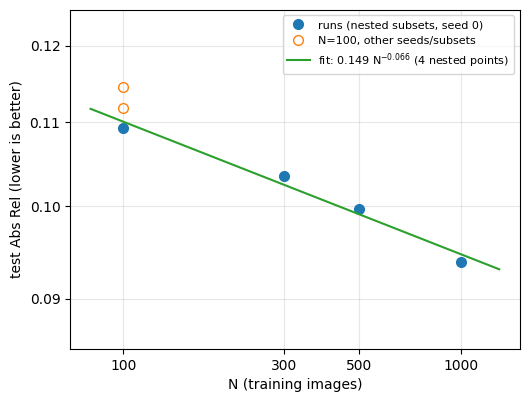

In [ ]:
NS_FIT = [100, 300, 500, 1000]
N_arr = np.array(NS_FIT, dtype=float)
y_arr = np.array([RESULTS[n]["summary"]["absrel"] for n in NS_FIT])

lx, ly = np.log(N_arr), np.log(y_arr)
(slope, intercept), cov = np.polyfit(lx, ly, 1, cov=True)
slope_se = float(np.sqrt(cov[0, 0]))
a = float(np.exp(intercept))

fit_ly = slope * lx + intercept
resid_log = ly - fit_ly
fit_y = np.exp(fit_ly)
ss_res, ss_tot = (resid_log**2).sum(), ((ly - ly.mean())**2).sum()
r2 = 1 - ss_res / ss_tot

print(f"log(AbsRel) = {slope:.4f} * log(N) + {intercept:.4f}")
print(f"slope = -b = {slope:.4f}  (b = {-slope:.4f}, SE ~ {slope_se:.4f}, 2 d.o.f.)")
print(f"a = {a:.4f}   R^2 = {r2:.4f}")
print(f"doubling N multiplies Abs Rel by about {2**slope:.3f}  ({100 * (2**slope - 1):+.1f}%)")

res_df = pd.DataFrame({"N": NS_FIT, "absrel": y_arr, "fitted": fit_y,
                       "resid_log": resid_log, "resid_%": 100 * (y_arr / fit_y - 1)})
print(res_df.round(4).to_string(index=False))
print(f"residual std (log, ddof=2) = {np.sqrt(ss_res / 2):.4f}")

if "RESULTS_SEED" in globals():
    a100_runs = [RESULTS[100]["summary"]["absrel"]] + [RESULTS_SEED[k]["summary"]["absrel"] for k in [(100, 1), (100, 2)]]
    s_mean = np.polyfit(lx, np.log([np.mean(a100_runs), *y_arr[1:]]), 1)[0]
    N6 = np.array([100, 100, 100, 300, 500, 1000.]); y6 = np.array(a100_runs + list(y_arr[1:]))
    (s6, _), c6 = np.polyfit(np.log(N6), np.log(y6), 1, cov=True)
    print(f"\nslope with the mean of the 3 N=100 runs : {s_mean:.4f}  (doubling -> {100 * (2**s_mean - 1):+.1f}%)")
    print(f"slope with all 6 points (3 at N=100)     : {s6:.4f} +- {np.sqrt(c6[0, 0]):.4f}  (4 d.o.f.)")

a_0 = RESULTS[0]["summary"]["absrel"]; a_1000 = RESULTS[1000]["summary"]["absrel"]
gap_all = a_0 - a_1000
print(f"\nN=0 -> N=1000 gap in Abs Rel: {gap_all:.4f}; half of it is reached at Abs Rel = {a_0 - gap_all / 2:.4f}")
rec = pd.DataFrame({"N": NS_FIT, "absrel": y_arr,
                    "share of gap recovered %": 100 * (a_0 - y_arr) / gap_all,
                    "above N=1000 by %": 100 * (y_arr / a_1000 - 1)})
print(rec.round(3).to_string(index=False))
if "RESULTS_SEED" in globals():
    print("share of gap recovered by the three N=100 runs (%):",
          [round(100 * (a_0 - v) / gap_all, 1) for v in a100_runs])

fig, ax = plt.subplots(figsize=(5.8, 4.4))
ax.loglog(N_arr, y_arr, "o", ms=7, label="runs (nested subsets, seed 0)")
if "RESULTS_SEED" in globals():
    extra = [RESULTS_SEED[k]["summary"]["absrel"] for k in [(100, 1), (100, 2)]]
    ax.loglog([100, 100], extra, "o", mfc="none", ms=7, label="N=100, other seeds/subsets")
grid = np.logspace(np.log10(80), np.log10(1300), 100)
ax.loglog(grid, a * grid**slope, "-", lw=1.5, label=f"fit: {a:.3f} N$^{{{slope:.3f}}}$ (4 nested points)")
ax.set_xticks(NS_FIT); ax.set_xticklabels([str(n) for n in NS_FIT]); ax.minorticks_off()
yt = [0.09, 0.10, 0.11, 0.12]
ax.set_yticks(yt); ax.set_yticklabels([f"{v:.2f}" for v in yt]); ax.set_ylim(0.085, 0.125)
ax.set_xlabel("N (training images)"); ax.set_ylabel("test Abs Rel (lower is better)")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
fig.savefig(f"{WORK}/powerlaw_fit.png", dpi=150, bbox_inches="tight")
plt.show()

*Answer:*

## 12. Object-level depth evaluation

The original proposal evaluated depth inside detected bounding boxes. Boxes include background and cannot separate cup 1 from cup 2. We have something better: the ground-truth **instance masks**, so every object can be scored on exactly its own pixels. This section asks *where* in the image the fine-tuning helps.

Every table below must use `RESULTS[n]["objects"]` and `RESULTS[n]["strata"]` for the five values of $n$, and the same test images in every row.

A warning about interpretation that applies to everything in this section: none of it tells you what the masks contributed. It describes where the error is, and how that moves as labelled data grows.

**Q12.1.** For the ten classes with the most instances in the test set (count them from `RESULTS[0]["objects"]`), compute the mean object-level Abs Rel at each $N$, averaging over instances. Print the table with class names, the instance count and the five values of $N$ as columns, and draw a grouped bar chart or one line per class against $N$. Which classes improve most, which least, and which get worse? A class with a handful of instances has a noisy mean: say which of your ten classes you would not draw a conclusion from, and why.

7384 objects in the test set, identical at every N


,class,n_objects,N=0,N=100,N=300,N=500,N=1000,sem (N=1000),change 0->1000,change 100->1000
0,wall,884,0.5107,0.1060,0.0999,0.0967,0.0905,0.0028,-0.4202,-0.0155
1,chair,491,0.7595,0.1293,0.1236,0.1218,0.1226,0.0045,-0.6369,-0.0067
2,picture,488,0.5220,0.0947,0.0878,0.0831,0.0807,0.0036,-0.4413,-0.0140
3,cabinet,377,0.5903,0.1089,0.1012,0.1000,0.0953,0.0046,-0.4950,-0.0136
4,floor,316,0.5681,0.0818,0.0786,0.0781,0.0776,0.0051,-0.4906,-0.0043
5,pillow,217,0.4886,0.0846,0.0860,0.0914,0.0853,0.0047,-0.4033,0.0008
6,table,171,0.7442,0.1472,0.1377,0.1333,0.1357,0.0116,-0.6085,-0.0115
7,bottle,163,0.7232,0.1184,0.1107,0.1040,0.1011,0.0074,-0.6221,-0.0173
8,book,140,0.6957,0.0888,0.0892,0.0815,0.0730,0.0046,-0.6227,-0.0158
9,books,136,0.6630,0.0950,0.0834,0.0798,0.0633,0.0062,-0.5997,-0.0317


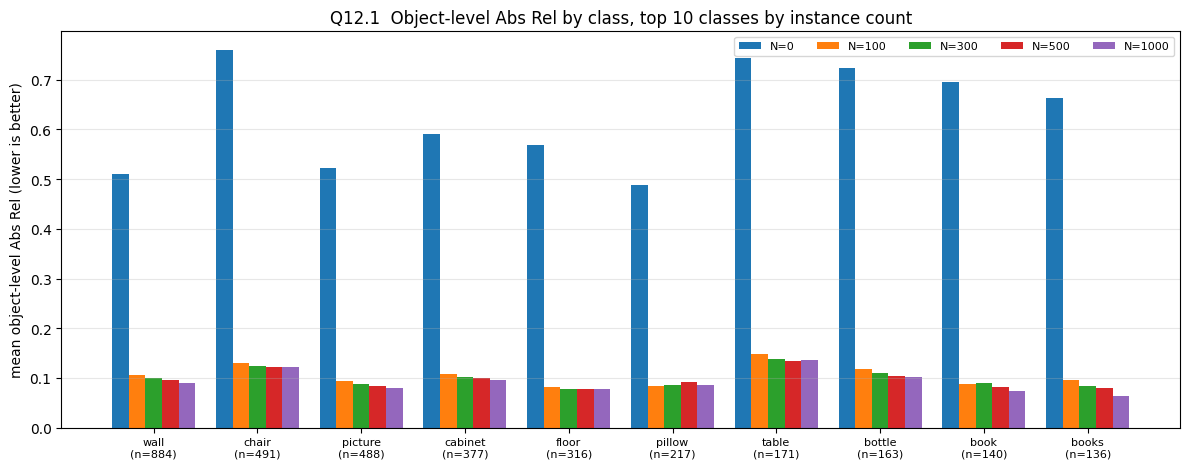


Biggest improvement N=100 -> N=1000 (most negative first):
  class  n_objects  change 100->1000
  books        136           -0.0317
 bottle        163           -0.0173
   book        140           -0.0158
   wall        884           -0.0155
picture        488           -0.0140
cabinet        377           -0.0136
  table        171           -0.0115
  chair        491           -0.0067
  floor        316           -0.0043
 pillow        217            0.0008

Classes whose mean Abs Rel is HIGHER at N=1000 than at N=100: ['pillow']
Classes whose mean Abs Rel is HIGHER at N=1000 than at N=0   : none

Smallest classes (noisiest means):
 class  n_objects  sem (N=1000)
 books        136        0.0062
  book        140        0.0046
bottle        163        0.0074
 table        171        0.0116


In [ ]:
# YOUR CODE HERE
NS = [0, 100, 300, 500, 1000]

# sanity: the same objects must appear at every N (same test images; the min_pixels filter depends only on GT)
key_cols = ["image", "cls", "inst"]
base = RESULTS[0]["objects"][key_cols].sort_values(key_cols).reset_index(drop=True)
for n in NS[1:]:
    other = RESULTS[n]["objects"][key_cols].sort_values(key_cols).reset_index(drop=True)
    assert base.equals(other), f"object set differs at N={n}"
print(f"{len(base)} objects in the test set, identical at every N")

top = RESULTS[0]["objects"]["cls"].value_counts().head(10)

rows = []
for c, cnt in top.items():
    row = {"class": CLASS_NAMES[int(c)], "n_objects": int(cnt)}
    for n in NS:
        o = RESULTS[n]["objects"]
        row[f"N={n}"] = o.loc[o["cls"] == c, "absrel"].mean()
    o1000 = RESULTS[1000]["objects"]
    row["sem (N=1000)"] = o1000.loc[o1000["cls"] == c, "absrel"].sem()
    row["change 0->1000"] = row["N=1000"] - row["N=0"]
    row["change 100->1000"] = row["N=1000"] - row["N=100"]
    rows.append(row)
class_tbl = pd.DataFrame(rows)
display(class_tbl.round(4))

# grouped bar chart: one group per class, one bar per N
fig, ax = plt.subplots(figsize=(12, 4.8))
w = 0.16
x = np.arange(len(class_tbl))
for i, n in enumerate(NS):
    ax.bar(x + (i - 2) * w, class_tbl[f"N={n}"], width=w, label=f"N={n}")
ax.set_xticks(x)
ax.set_xticklabels([f"{r['class']}\n(n={r['n_objects']})" for _, r in class_tbl.iterrows()], fontsize=8)
ax.set_ylabel("mean object-level Abs Rel (lower is better)")
ax.set_title("Q12.1  Object-level Abs Rel by class, top 10 classes by instance count")
ax.legend(ncol=5, fontsize=8); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

# what the answer needs
print("\nBiggest improvement N=100 -> N=1000 (most negative first):")
print(class_tbl.sort_values("change 100->1000")[["class", "n_objects", "change 100->1000"]].round(4).to_string(index=False))
worse = class_tbl[class_tbl["N=1000"] > class_tbl["N=100"]]["class"].tolist()
print("\nClasses whose mean Abs Rel is HIGHER at N=1000 than at N=100:", worse if worse else "none")
worse0 = class_tbl[class_tbl["N=1000"] > class_tbl["N=0"]]["class"].tolist()
print("Classes whose mean Abs Rel is HIGHER at N=1000 than at N=0   :", worse0 if worse0 else "none")
print("\nSmallest classes (noisiest means):")
print(class_tbl.sort_values("n_objects")[["class", "n_objects", "sem (N=1000)"]].head(4).round(4).to_string(index=False))


*Answer:*

**Q12.2.** Bucket the objects by `area_frac` into **small** ($<1\%$ of the image), **medium** ($1\%$ to $5\%$) and **large** ($\ge 5\%$), and report for each bucket and each $N$ the mean object-level Abs Rel and the number of objects. Plot Abs Rel against $N$ with one line per bucket. Do small objects behave differently from large ones? Remember that the instance masks of a small object are the least reliable, after the nearest-neighbour downsampling to the network's resolution, of anything the model sees.

,bucket,n_objects,N=0,N=100,N=300,N=500,N=1000
0,small (<1%),3297,0.6273,0.1095,0.1050,0.1022,0.0977
1,medium (1-5%),2396,0.6228,0.1172,0.1116,0.1090,0.1048
2,large (>=5%),1691,0.6042,0.1071,0.1012,0.0971,0.0921


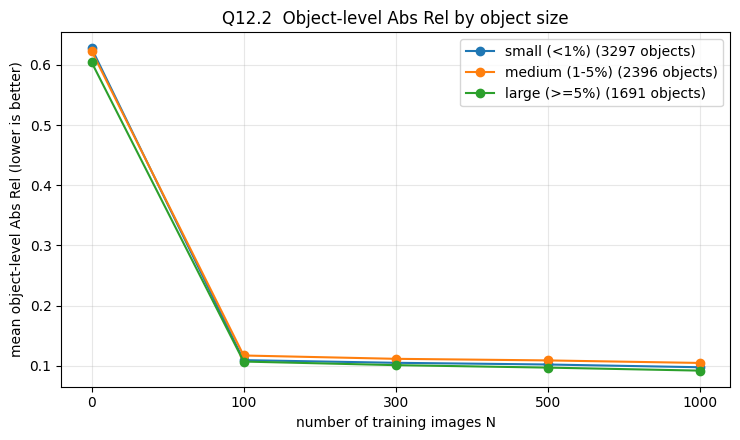

small (<1%)    N=0 -> 100:  -82.5%   100 -> 1000:  -10.8%   0 -> 1000:  -84.4%
medium (1-5%)  N=0 -> 100:  -81.2%   100 -> 1000:  -10.6%   0 -> 1000:  -83.2%
large (>=5%)   N=0 -> 100:  -82.3%   100 -> 1000:  -14.0%   0 -> 1000:  -84.8%


In [ ]:
# YOUR CODE HERE
BUCKETS = ["small (<1%)", "medium (1-5%)", "large (>=5%)"]

def size_bucket(a):
    return pd.cut(a, bins=[0, 0.01, 0.05, np.inf], right=False, labels=BUCKETS)

rows = []
for b in BUCKETS:
    row = {"bucket": b}
    for n in NS:
        o = RESULTS[n]["objects"]
        sel = o[size_bucket(o["area_frac"]) == b]
        row[f"N={n}"] = sel["absrel"].mean()
        if n == 0:
            row["n_objects"] = len(sel)
    rows.append(row)
size_tbl = pd.DataFrame(rows)[["bucket", "n_objects"] + [f"N={n}" for n in NS]]
display(size_tbl.round(4))

# the number of objects per bucket is the same at every N (checked in Q12.1); print it once more as a safety net
for n in NS[1:]:
    o = RESULTS[n]["objects"]
    assert (size_bucket(o["area_frac"]).value_counts().reindex(BUCKETS).values == size_tbl["n_objects"].values).all()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
xpos = np.arange(len(NS))
for _, r in size_tbl.iterrows():
    ax.plot(xpos, [r[f"N={n}"] for n in NS], "o-", label=f"{r['bucket']} ({r['n_objects']} objects)")
ax.set_xticks(xpos); ax.set_xticklabels(NS)
ax.set_xlabel("number of training images N"); ax.set_ylabel("mean object-level Abs Rel (lower is better)")
ax.set_title("Q12.2  Object-level Abs Rel by object size")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# relative change, so the buckets can be compared on one scale
for _, r in size_tbl.iterrows():
    print(f"{r['bucket']:<14} N=0 -> 100: {100*(r['N=100']/r['N=0']-1):+6.1f}%   "
          f"100 -> 1000: {100*(r['N=1000']/r['N=100']-1):+6.1f}%   "
          f"0 -> 1000: {100*(r['N=1000']/r['N=0']-1):+6.1f}%")



*Answer:*

**Q12.3.** Using `RESULTS[n]["strata"]`, pool each stratum over **all test images** by summing `sum_absrel` and `n` and dividing, for each $N$. Report the six strata (`0-2m`, `2-4m`, `4-6m`, `6-10m`, `labelled`, `unlabelled`) against $N$ in a table and a plot. Mobility assistance cares most about the nearest band: how does Abs Rel in `0-2m` compare with `6-10m` at N = 0 and at N = 1000? Do labelled pixels get a lower error than unlabelled ones, and does the gap change with N? Why is a pooled stratum Abs Rel not directly comparable with the per-image Abs Rel of Section 11?

,stratum,valid pixels,N=0,N=100,N=300,N=500,N=1000
0,0-2m,28283703,0.7808,0.1421,0.1303,0.1266,0.1169
1,2-4m,42891197,0.5359,0.0856,0.0844,0.0798,0.0766
2,4-6m,9404479,0.4679,0.1013,0.0968,0.0941,0.0910
3,6-10m,2678061,0.3527,0.1704,0.1481,0.1513,0.1366
4,labelled,73304251,0.6063,0.1076,0.1016,0.0977,0.0919
5,unlabelled,9953189,0.6000,0.1221,0.1170,0.1137,0.1080


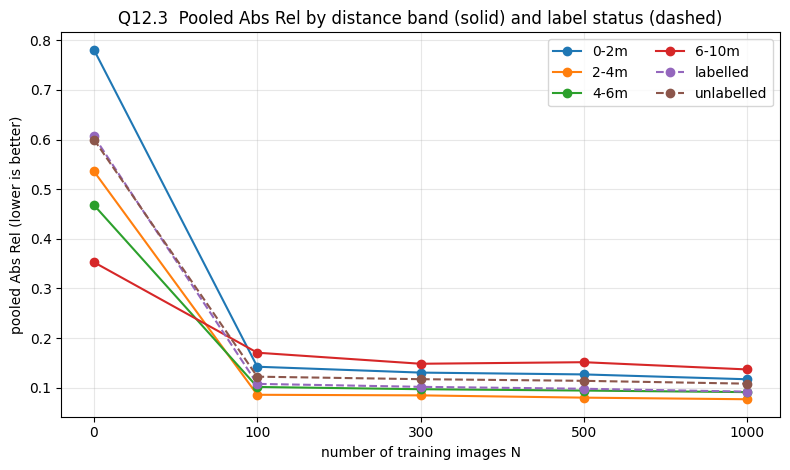

N=   0: 0-2m = 0.7808   6-10m = 0.3527   ratio (0-2m / 6-10m) = 2.21
N=1000: 0-2m = 0.1169   6-10m = 0.1366   ratio (0-2m / 6-10m) = 0.86

N=   0: labelled 0.6063  unlabelled 0.6000  gap (unlabelled - labelled) = -0.0063
N= 100: labelled 0.1076  unlabelled 0.1221  gap (unlabelled - labelled) = +0.0145
N= 300: labelled 0.1016  unlabelled 0.1170  gap (unlabelled - labelled) = +0.0154
N= 500: labelled 0.0977  unlabelled 0.1137  gap (unlabelled - labelled) = +0.0160
N=1000: labelled 0.0919  unlabelled 0.1080  gap (unlabelled - labelled) = +0.0161


In [ ]:
# YOUR CODE HERE
STRATA = ["0-2m", "2-4m", "4-6m", "6-10m", "labelled", "unlabelled"]

rows = []
for s in STRATA:
    row = {"stratum": s}
    for n in NS:
        st = RESULTS[n]["strata"]
        st = st[st["stratum"] == s]
        # pool: sum of per-pixel errors over ALL images divided by pixel count over ALL images
        row[f"N={n}"] = st["sum_absrel"].sum() / st["n"].sum()
        if n == 0:
            row["valid pixels"] = int(st["n"].sum())
    rows.append(row)
strata_tbl = pd.DataFrame(rows)[["stratum", "valid pixels"] + [f"N={n}" for n in NS]]
display(strata_tbl.round(4))

fig, ax = plt.subplots(figsize=(8, 4.8))
for _, r in strata_tbl.iterrows():
    ls = "--" if r["stratum"] in ("labelled", "unlabelled") else "-"
    ax.plot(xpos, [r[f"N={n}"] for n in NS], "o" + ls, label=r["stratum"])
ax.set_xticks(xpos); ax.set_xticklabels(NS)
ax.set_xlabel("number of training images N"); ax.set_ylabel("pooled Abs Rel (lower is better)")
ax.set_title("Q12.3  Pooled Abs Rel by distance band (solid) and label status (dashed)")
ax.grid(alpha=0.3); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

# numbers for the answer
t = strata_tbl.set_index("stratum")
for n in (0, 1000):
    print(f"N={n:>4}: 0-2m = {t.loc['0-2m', f'N={n}']:.4f}   6-10m = {t.loc['6-10m', f'N={n}']:.4f}   "
          f"ratio (0-2m / 6-10m) = {t.loc['0-2m', f'N={n}'] / t.loc['6-10m', f'N={n}']:.2f}")
print()
for n in NS:
    lab, unl = t.loc["labelled", f"N={n}"], t.loc["unlabelled", f"N={n}"]
    print(f"N={n:>4}: labelled {lab:.4f}  unlabelled {unl:.4f}  gap (unlabelled - labelled) = {unl - lab:+.4f}")


*Answer:*

## 13. W&B experiment tracking

Every run you made logged its own config, history and test metrics. This section adds one more run that collects the whole result in one place, and asks you to link everything.

**Q13.1.** Start a W&B run named `summary` with the whole `CONFIG` as its config. Log `results_df` from Q11.1 as a `wandb.Table`, the learning-curve figure from Q11.2 as an image, and the object-level tables from Section 12 as `wandb.Table`s. Print the run URL.

In [ ]:
# Q13.1  W&B summary run
wandb.finish()   # make sure no earlier run is still active

NS = [0, 100, 300, 500, 1000]
STRATA = ["0-2m", "2-4m", "4-6m", "6-10m", "labelled", "unlabelled"]

# ---------- 1. Main results table (results_df from Q11.1), plain-word column titles ----------
results_plain = results_df.rename(columns={
    "n_train":   "Training images",
    "absrel":    "Average relative error (Abs Rel, lower is better)",
    "rmse":      "Average error in metres (RMSE, lower is better)",
    "d1":        "Share of pixels within 25% (d1, higher is better)",
    "d2":        "Share of pixels within 56% (d2, higher is better)",
    "d3":        "Share of pixels within 95% (d3, higher is better)",
    "best_step": "Best training step",
    "minutes":   "Minutes taken",
}).round(4)

# ---------- 2. Object-level table by class (top 10 classes by instance count) ----------
obj0 = RESULTS[0]["objects"]
top_counts = obj0["cls"].value_counts().head(10)

class_rows = []
for c, cnt in top_counts.items():
    row = {"Class": CLASS_NAMES[int(c)], "Number of objects": int(cnt)}
    for n in NS:
        o = RESULTS[n]["objects"]
        row[f"Error with {n} training images"] = o.loc[o["cls"] == c, "absrel"].mean()
    class_rows.append(row)
class_df = pd.DataFrame(class_rows).round(4)

# ---------- 3. Object-level table by object size ----------
BUCKETS = ["small (under 1% of image)", "medium (1% to 5%)", "large (5% or more)"]
def size_bucket(a):
    return pd.cut(a, bins=[0, 0.01, 0.05, np.inf], right=False, labels=BUCKETS)

size_rows = []
for b in BUCKETS:
    row = {"Object size": b}
    for n in NS:
        o = RESULTS[n]["objects"]
        sel = o[size_bucket(o["area_frac"]) == b]
        row[f"Error with {n} training images"] = sel["absrel"].mean()
        if n == 0:
            row["Number of objects"] = len(sel)
    size_rows.append(row)
size_df = pd.DataFrame(size_rows)
size_df = size_df[["Object size", "Number of objects"] + [c for c in size_df.columns if c.startswith("Error")]].round(4)

# ---------- 4. Distance / labelled-vs-unlabelled strata (pooled over all test pixels) ----------
strata_rows = []
for s in STRATA:
    row = {"Region": s}
    for n in NS:
        st = RESULTS[n]["strata"]
        st = st[st["stratum"] == s]
        row[f"Error with {n} training images"] = st["sum_absrel"].sum() / max(st["n"].sum(), 1)
    strata_rows.append(row)
strata_df = pd.DataFrame(strata_rows).round(4)

display(class_df); display(size_df); display(strata_df)

# ---------- 5. Graphs ----------
x = np.arange(len(NS))
err_cols = [f"Error with {n} training images" for n in NS]

fig_class, ax = plt.subplots(figsize=(11, 6))
for _, r in class_df.iterrows():
    ax.plot(x, r[err_cols].values.astype(float), "o-", label=f"{r['Class']} ({r['Number of objects']})")
ax.set_xticks(x); ax.set_xticklabels(NS)
ax.set_xlabel("Number of training images"); ax.set_ylabel("Average relative error (lower is better)")
ax.set_title("Error by object class"); ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.close(fig_class)

fig_size, ax = plt.subplots(figsize=(9, 6))
for _, r in size_df.iterrows():
    ax.plot(x, r[err_cols].values.astype(float), "o-", label=f"{r['Object size']} ({r['Number of objects']} objects)")
ax.set_xticks(x); ax.set_xticklabels(NS)
ax.set_xlabel("Number of training images"); ax.set_ylabel("Average relative error (lower is better)")
ax.set_title("Error by object size"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.close(fig_size)

fig_strata, ax = plt.subplots(figsize=(9, 6))
for _, r in strata_df.iterrows():
    ax.plot(x, r[err_cols].values.astype(float), "o-", label=r["Region"])
ax.set_xticks(x); ax.set_xticklabels(NS)
ax.set_xlabel("Number of training images"); ax.set_ylabel("Average relative error (lower is better)")
ax.set_title("Error by distance band and labelled / unlabelled pixels (pooled over pixels)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.close(fig_strata)

# ---------- 6. Start the summary run and log everything ----------
run = wandb.init(
    project=CONFIG["wandb_project"], name="summary", reinit=True,
    config={"CONFIG": CONFIG, "model_id": CONFIG["pretrained_id"],
            "split_sizes": {k: len(v) for k, v in SPLITS.items()},
            "train_sizes": NS},
)

log_dict = {
    "results_table":        wandb.Table(dataframe=results_plain),
    "objects_by_class":     wandb.Table(dataframe=class_df),
    "objects_by_size":      wandb.Table(dataframe=size_df),
    "error_by_region":      wandb.Table(dataframe=strata_df),
    "plot_objects_by_class": wandb.Image(fig_class),
    "plot_objects_by_size":  wandb.Image(fig_size),
    "plot_error_by_region":  wandb.Image(fig_strata),
}

# learning-curve figure from Q11.2 (and the power-law fit from Q11.5 if it was saved)
for key, fname in [("learning_curve", "learning_curve.png"), ("power_law_fit", "powerlaw_fit.png")]:
    p = f"{WORK}/{fname}"
    if os.path.exists(p):
        log_dict[key] = wandb.Image(p)
    else:
        print(f"WARNING: {p} not found - re-run the cell that saves it, then re-run this cell")

run.log(log_dict)

# headline numbers on the run page
for n in NS:
    for k in METRIC_COLS:
        run.summary[f"N{n}_{k}"] = RESULTS[n]["summary"][k]

print("W&B run URL:", run.url)
wandb.finish()# YOUR CODE HERE

,Class,Number of objects,Error with 0 training images,Error with 100 training images,Error with 300 training images,Error with 500 training images,Error with 1000 training images
0,wall,884,0.5107,0.1060,0.0999,0.0967,0.0905
1,chair,491,0.7595,0.1293,0.1236,0.1218,0.1226
2,picture,488,0.5220,0.0947,0.0878,0.0831,0.0807
3,cabinet,377,0.5903,0.1089,0.1012,0.1000,0.0953
4,floor,316,0.5681,0.0818,0.0786,0.0781,0.0776
5,pillow,217,0.4886,0.0846,0.0860,0.0914,0.0853
6,table,171,0.7442,0.1472,0.1377,0.1333,0.1357
7,bottle,163,0.7232,0.1184,0.1107,0.1040,0.1011
8,book,140,0.6957,0.0888,0.0892,0.0815,0.0730
9,books,136,0.6630,0.0950,0.0834,0.0798,0.0633


,Object size,Number of objects,Error with 0 training images,Error with 100 training images,Error with 300 training images,Error with 500 training images,Error with 1000 training images
0,small (under 1% of image),3297,0.6273,0.1095,0.1050,0.1022,0.0977
1,medium (1% to 5%),2396,0.6228,0.1172,0.1116,0.1090,0.1048
2,large (5% or more),1691,0.6042,0.1071,0.1012,0.0971,0.0921


,Region,Error with 0 training images,Error with 100 training images,Error with 300 training images,Error with 500 training images,Error with 1000 training images
0,0-2m,0.7808,0.1421,0.1303,0.1266,0.1169
1,2-4m,0.5359,0.0856,0.0844,0.0798,0.0766
2,4-6m,0.4679,0.1013,0.0968,0.0941,0.0910
3,6-10m,0.3527,0.1704,0.1481,0.1513,0.1366
4,labelled,0.6063,0.1076,0.1016,0.0977,0.0919
5,unlabelled,0.6000,0.1221,0.1170,0.1137,0.1080


W&B run URL: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/wudq0xf2


N0_absrel,0.60554
N0_d1,0.08831
N0_d2,0.50815
N0_d3,0.88613
N0_rmse,1.55675
N1000_absrel,0.09383
N1000_d1,0.92231
N1000_d2,0.98603
N1000_d3,0.99617
N1000_rmse,0.34688
+15,...


Paste links to your W&B runs below. At minimum: `N0-pretrained-seg`; `ft-N100-s0`, `ft-N300-s0`, `ft-N500-s0`, `ft-N1000-s0`; the two extra N = 100 runs of Q11.4; and `summary`. Each needs a meaningful name and a complete config.

*W&B run links:*
- View run N0-pretrained-seg at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/kqnb7iy9

- View run ft-N100-s0 at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/l36ksccl

- View run ft-N300-s0 at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/vbt0cvsi

- View run ft-N500-s0 at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/rgx9xmpm

- View run ft-N1000-s0 at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/9udxsg6l

- View run ft-N100-s1-sub1 at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/m8lpicto

- View run ft-N100-s2-sub2 at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/hyn7qcpw

- View run summary at: https://wandb.ai/2671832-university-of-the-witwatersrand/cv-depth-seg/runs/s08s2p8v


## 14. Final analysis

Three short written answers. Write them for a reader who has not seen the notebook, and use numbers from your tables.

**Q14.1. Findings.** In at most 200 words, answer the project's question: how does depth-estimation performance change as the number of labelled training images grows from 0 to 1,000? Report the N = 0 and N = 1000 values of Abs Rel, RMSE and $\delta_1$ with their confidence intervals, say where the curve flattens (if it does), and whether the seed spread of Q11.4 changes your reading of the 100-image result.

*Answer:*

**Q14.2. What this experiment can and cannot show.** Address each of these in one or two sentences:

- The instance masks are **ground truth at test time**. What does that make the numbers, and what would you expect to happen to them if the masks were predicted by a segmentation network?
- There is **no RGB-only control**. The improvement from N = 0 to N = 1000 combines two things: fine-tuning a depth model on indoor Kinect data, and learning to use the masks. Which of the two can this design not separate, and what single extra experiment would separate them?
- **One split, one test set of about 349 images from 3 cities.** What does that limit?
- **Depth maps with filled-in holes** and a **Kinect with a 10 m range**: what do they limit about the claim "this works indoors"?

*Answer:*

**Q14.3. Relevance to mobility assistance.** Using Q12.3, say what error your best model makes in the 0–2 m band, and what that error means in centimetres at 1 m. Say whether an Abs Rel of that size is likely to be good enough to tell a user "something is about a metre ahead of you", and what else a real system would need before it could be tested with visually impaired users. Do not claim that this project provides a navigation system.

*Answer:*

## 15. Before you submit

- [ ] A full **Restart session and run all** retrains five models and takes hours, so instead confirm that every run you report used the **same** `CONFIG`, and that the checkpoints in `WORK` match the numbers in your tables. Re-run Sections 0 to 6 from the top at least once to make sure they work from a clean session.
- [ ] Group members filled in; every member can explain every cell.
- [ ] Q4.1 and Q6.1 answered from paper, with the arithmetic shown, not copied from the code below them.
- [ ] Every *Answer:* cell answered; W&B links pasted in Section 13.
- [ ] Q5.3's identity check prints `0.0`; Q2.1's leakage assertion passes.
- [ ] No result in any table was produced by an image you chose after seeing the outcome (`VIS_IDX` fixed in Q6.5; test set used only for the final evaluation).
- [ ] **File ▸ Download ▸ Download .ipynb**, and submit one copy per group.